# Benchmark de Visão Computacional — EuroSAT RGB

**CNN do zero + Optuna · ResNet50 · ViT + LightGBM · ViT + LoRA**

Este notebook é simultaneamente uma aula prática e o ponto de entrada executável do projeto. O percurso é:

> arquivo de imagem → pixels RGB → array NumPy → tensor PyTorch → filtros e convoluções → `Dataset`/`DataLoader` → quatro estratégias de modelagem → benchmark comum

Ao final, saberemos não apenas qual modelo obteve o maior **F1 Macro**, mas também quanto custou treiná-lo, quantos parâmetros foram adaptados e em quais classes ele errou.


## Como usar este notebook

1. Execute primeiro toda a **Parte I**; ela valida os dados e materializa um único split estratificado.
2. Na configuração, mantenha `EXECUTAR_TREINOS = False` para estudar o fluxo sem iniciar tarefas longas.
3. Quando o ambiente estiver pronto, altere a flag para `True` e execute os experimentos em ordem.
4. O teste só é consultado uma vez por modelo, depois de todas as decisões feitas com treino/validação.

Os blocos caros estão marcados com a tag `treino-pesado`. Em CPU, prefira `MODO_RAPIDO = True` para validar o pipeline antes da execução completa.


# Parte I — Fundamentos e exploração guiada

## 1. Apresentação, objetivos e mapa

**Pergunta de aprendizagem:** como números organizados em uma imagem se transformam em uma decisão de classe?

Objetivos:

- interpretar `H × W × C`, pixels, canais, `dtype` e faixa de valores;
- acompanhar `PIL → NumPy → Tensor`;
- entender kernels, feature maps, ativações e pooling;
- construir splits sem vazamento;
- distinguir aprendizado do zero, transfer learning, embeddings e LoRA.


### Mapa experimental

| Estratégia | Representação | O que é treinado |
|---|---|---|
| CNN do zero | filtros aprendidos no EuroSAT | toda a rede |
| ResNet50 | features ImageNet | cabeça e, opcionalmente, último bloco |
| ViT + LightGBM | embedding `[CLS]` congelado | somente LightGBM |
| ViT + LoRA | patches + self-attention | adaptadores LoRA e classificador |

**Conclusão da seção:** todos partem dos mesmos arquivos e índices; o que muda é como a representação visual é obtida e adaptada.


## 2. Problema de negócio e EuroSAT RGB

**Pergunta de aprendizagem:** qual decisão o modelo apoia e o que existe nos dados?

O EuroSAT RGB contém imagens aéreas de uso e cobertura do solo em dez classes. Um classificador pode apoiar triagem cartográfica e monitoramento territorial, mas não substitui validação geoespacial. Este escopo usa **somente RGB**; vermelho, verde e azul não devem ser confundidos com todas as bandas multiespectrais do Sentinel-2.

A unidade de análise é uma imagem e o alvo é uma das dez classes. Como errar uma classe rara importa tanto quanto errar uma frequente, o critério principal será **F1 Macro**.


## 3. Bibliotecas, ambiente, dispositivo e reprodutibilidade

**Objetivo:** carregar apenas dependências básicas no início e diagnosticar as opcionais antes dos experimentos.

PyTorch conduz os modelos; `transformers` fornece o ViT; `peft` aplica LoRA; LightGBM classifica embeddings; Optuna busca somente hiperparâmetros da CNN.


In [60]:
# -----------------------------------------------------------------------------
# Objetivo desta célula: Verificar se o kernel possui as dependências básicas do projeto.
# -----------------------------------------------------------------------------
# importlib permite verificar a presença de um pacote sem importá-lo por completo.
import importlib.util

# Estes pacotes são obrigatórios para executar a parte fundamental do notebook.
PACOTES_BASE = [
    "matplotlib",
    "numpy",
    "pandas",
    "PIL",
    "seaborn",
    "sklearn",
    "torch",
    "torchvision",
]
# find_spec retorna None quando o pacote não existe no ambiente do kernel.
ausentes_base = [p for p in PACOTES_BASE if importlib.util.find_spec(p) is None]

# Interrompemos cedo para evitar erros menos claros em células posteriores.
if ausentes_base:
    raise RuntimeError(
        "O kernel selecionado não possui as dependências básicas: "
        f"{ausentes_base}. Instale-as nesse ambiente ou selecione o kernel "
        "correto antes de continuar."
    )
print("Dependências básicas encontradas no kernel.")


Dependências básicas encontradas no kernel.


In [61]:
# -----------------------------------------------------------------------------
# Objetivo desta célula: Importar bibliotecas e configurar a apresentação de tabelas e gráficos.
# -----------------------------------------------------------------------------
# Adia a avaliação dos type hints e facilita referências a tipos definidos depois.
from __future__ import annotations

# Biblioteca padrão: arquivos, sistema, serialização, tempo e reprodutibilidade.
import copy
import hashlib
import importlib.util
import json
import os
import pickle
import platform
import random
import sys
import time
from dataclasses import asdict, dataclass
from pathlib import Path
from typing import Callable, Iterable

# Bibliotecas para cálculo numérico, tabelas e visualizações.
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
# Scikit-learn fornece splits e métricas; PyTorch conduz o deep learning.
import sklearn
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
# PIL decodifica imagens; os imports seguintes organizam métricas e DataLoaders.
from PIL import Image, ImageFile
from sklearn.metrics import (
    accuracy_score, confusion_matrix, f1_score, precision_score,
    recall_score, roc_auc_score,
)
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Dataset
from torchvision import models, transforms
from torchvision.transforms import InterpolationMode

# Arquivos truncados devem gerar erro, pois imagens incompletas comprometem o dataset.
ImageFile.LOAD_TRUNCATED_IMAGES = False
# Define um estilo visual comum e permite visualizar mais colunas nas tabelas.
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)


In [62]:
# -----------------------------------------------------------------------------
# Objetivo desta célula: Diagnosticar as dependências opcionais usadas nos experimentos avançados.
# -----------------------------------------------------------------------------
# Cada pacote abaixo é necessário apenas para uma etapa avançada específica.
PACOTES_OPCIONAIS = ["optuna", "lightgbm", "transformers", "peft", "safetensors"]
# A tabela torna explícito o que poderá ou não ser executado neste ambiente.
diagnostico = pd.DataFrame({
    "pacote": PACOTES_OPCIONAIS,
    "disponivel": [importlib.util.find_spec(p) is not None for p in PACOTES_OPCIONAIS],
})
# Exibe disponibilidade e versões para tornar a execução reproduzível.
display(diagnostico)
print(
    f"Python: {sys.version.split()[0]} | "
    f"PyTorch: {torch.__version__} | "
    f"torchvision: {torchvision.__version__}"
)
print(f"Sistema: {platform.platform()}")


,pacote,disponivel
0,optuna,True
1,lightgbm,True
2,transformers,True
3,peft,True
4,safetensors,True


Python: 3.10.19 | PyTorch: 2.6.0+cu126 | torchvision: 0.21.0+cu126
Sistema: Windows-10-10.0.19041-SP0


**Interpretação:** dependências opcionais ausentes afetam apenas seus respectivos experimentos. Instale-as no ambiente do kernel antes de ativar os treinos; não escondemos instalações dentro do notebook porque isso dificulta a reprodução.

**Conclusão da seção:** versões e disponibilidade ficam visíveis antes de consumir GPU ou baixar pesos.


## 4. Configurações e funções auxiliares

**Objetivo:** centralizar caminhos, semente e controles de custo. Nada abaixo deve depender do conjunto de teste para tomar decisões.


In [63]:
# -----------------------------------------------------------------------------
# Objetivo desta célula: Centralizar caminhos, semente, dispositivo e controles de execução.
# -----------------------------------------------------------------------------
@dataclass(frozen=True)
class Config:
    """Agrupa as configurações fixas e reproduzíveis do benchmark."""

    # Semente usada nas operações aleatórias: divisão dos dados, inicialização
    # dos pesos, embaralhamento dos lotes e amostragens.
    seed: int = 42

    # Altura e largura padronizadas das imagens. O valor 224 é compatível com
    # as entradas esperadas pela ResNet50 e pelo ViT escolhidos no projeto.
    img_size: int = 224

    # Frações reservadas para validação e teste. Os 70% restantes formam o
    # treino. Esses valores ficam fixos para todos os modelos do benchmark.
    val_size: float = 0.15
    test_size: float = 0.15

    # Quantidade de subprocessos usados pelo DataLoader. No Windows usamos 0
    # por padrão para evitar problemas de multiprocessamento em notebooks.
    num_workers: int = 0 if os.name == "nt" else 2

    # Limite máximo de épocas da CNN definitiva. O early stopping pode encerrar
    # o treinamento antes desse limite quando a validação deixa de melhorar.
    epochs: int = 30

    # Número de épocas consecutivas sem melhora toleradas pelo early stopping.
    patience: int = 6

    # Orçamento máximo de configurações que o Optuna testará na CNN.
    n_trials: int = 20

    # Identificador do ViT pré-treinado compartilhado pelos experimentos de
    # embeddings e LoRA, garantindo que ambos usem o mesmo backbone.
    vit_model_id: str = "google/vit-base-patch16-224-in21k"


# Cria uma única configuração. frozen=True evita que seus campos sejam
# alterados acidentalmente depois desta instanciação.
CFG = Config()

# Atalho para a semente, usado em várias funções ao longo do notebook.
SEED = CFG.seed

# Considera como raiz do projeto a pasta na qual o notebook foi iniciado e
# transforma o caminho em uma forma absoluta.
ROOT = Path.cwd().resolve()

# Centraliza os diretórios de entrada, modelos treinados e relatórios.
DATA_DIR = ROOT / "data"
ARTIFACT_DIR = ROOT / "models"
REPORT_DIR = ROOT / "reports"

# Arquivo que guarda a divisão oficial dos dados. Incluir a semente no nome
# evita confundir splits criados com configurações aleatórias diferentes.
SPLIT_FILE = DATA_DIR / f"splits_eurosat_seed{SEED}.csv"

# True reduz dados, épocas e tentativas para testar rapidamente o pipeline.
MODO_RAPIDO = True

# False funciona como uma trava de segurança contra treinamentos demorados.
# Altere conscientemente para True quando quiser executar os experimentos.
EXECUTAR_TREINOS = True

# Seleciona a GPU CUDA quando disponível; caso contrário, utiliza a CPU.
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Cria somente as pastas de saída. exist_ok=True evita erro se elas já existem.
for pasta in (ARTIFACT_DIR, REPORT_DIR):
    pasta.mkdir(parents=True, exist_ok=True)

# Exibe um resumo para confirmar os caminhos e o modo de execução antes de
# qualquer processamento ou treinamento.
print(f"Projeto: {ROOT}")
print(f"Dados: {DATA_DIR}")
print(f"Dispositivo: {DEVICE} | modo rápido: {MODO_RAPIDO} | treinos: {EXECUTAR_TREINOS}")


Projeto: D:\Projetos_v2\Modelo_VC_Satelites
Dados: D:\Projetos_v2\Modelo_VC_Satelites\data
Dispositivo: cuda | modo rápido: True | treinos: True


In [64]:
# -----------------------------------------------------------------------------
# Objetivo desta célula: Definir utilitários compartilhados pelas etapas do notebook.
# -----------------------------------------------------------------------------
# --- Reprodutibilidade -------------------------------------------------------
def definir_semente(seed: int = SEED) -> None:
    '''Reduz variação acidental entre execuções.'''
    # Cada biblioteca mantém seu próprio gerador de números aleatórios.
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    # GPUs possuem geradores próprios; por isso também recebem a semente.
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    # Priorizamos repetibilidade em vez de escolher automaticamente o algoritmo mais rápido.
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


# --- Validação de dependências opcionais ------------------------------------
def exigir_pacote(nome: str) -> None:
    '''Produz erro acionável somente quando um experimento opcional é solicitado.'''
    if importlib.util.find_spec(nome) is None:
        raise ImportError(f"Instale '{nome}' no ambiente deste kernel para executar esta seção.")


# --- Sementes dos processos usados pelo DataLoader --------------------------
def worker_seed(worker_id: int) -> None:
    """Define uma semente diferente e reproduzível para cada worker."""
    np.random.seed(SEED + worker_id)
    random.seed(SEED + worker_id)


# O gerador controla especificamente a ordem aleatória dos mini-batches.
def criar_gerador(seed: int = SEED) -> torch.Generator:
    """Cria o gerador usado pelo DataLoader para embaralhamento reproduzível."""
    return torch.Generator().manual_seed(seed)


# --- Conversão para visualização --------------------------------------------
def desnormalizar(
    tensor: torch.Tensor,
    media: Iterable[float],
    desvio: Iterable[float],
) -> torch.Tensor:
    """Retorna um tensor à escala visual aproximada de zero a um."""
    # [:, None, None] transforma três valores em (C, 1, 1) para broadcasting.
    media_t = torch.tensor(list(media), device=tensor.device)[:, None, None]
    desvio_t = torch.tensor(list(desvio), device=tensor.device)[:, None, None]
    return (tensor * desvio_t + media_t).clamp(0, 1)


# --- Medidas de custo do modelo ---------------------------------------------
def tamanho_modelo_mb(modelo: nn.Module) -> float:
    """Estima a memória ocupada por parâmetros e buffers do modelo."""
    # numel × bytes por elemento estima a memória ocupada por cada tensor.
    bytes_total = sum(p.numel() * p.element_size() for p in modelo.parameters())
    bytes_total += sum(b.numel() * b.element_size() for b in modelo.buffers())
    return bytes_total / 1024**2


# Separamos parâmetros totais dos que realmente receberão gradientes.
def contar_parametros(modelo: nn.Module) -> tuple[int, int]:
    """Conta parâmetros totais e parâmetros efetivamente treináveis."""
    total = sum(p.numel() for p in modelo.parameters())
    treinaveis = sum(p.numel() for p in modelo.parameters() if p.requires_grad)
    return total, treinaveis


# --- Inspeção didática de tensores ------------------------------------------
def resumo_tensor(nome: str, x: torch.Tensor | np.ndarray) -> None:
    """Mostra forma, tipo e faixa de valores de um array ou tensor."""
    print(f"{nome}: shape={tuple(x.shape)}, dtype={x.dtype}, min={x.min():.4f}, max={x.max():.4f}")


# --- Compatibilidade entre saídas PyTorch e Hugging Face --------------------
def logits_do_modelo(modelo: nn.Module, imagens: torch.Tensor) -> torch.Tensor:
    """Uniformiza a saída de modelos PyTorch e Hugging Face."""
    saida = modelo(imagens)
    return saida.logits if hasattr(saida, "logits") else saida


# --- Amostragem balanceada para o modo rápido -------------------------------
def subconjunto_rapido(df: pd.DataFrame, n_por_classe: int = 120) -> pd.DataFrame:
    """Seleciona uma amostra balanceada para validar o pipeline."""
    amostras_por_classe = []

    # Amostramos separadamente para nenhuma classe desaparecer do teste rápido.
    for _, grupo in df.groupby("classe"):
        quantidade = min(len(grupo), n_por_classe)
        amostras_por_classe.append(
            grupo.sample(
                n=quantidade,
                random_state=SEED,
            )
        )

    amostra_balanceada = pd.concat(
        amostras_por_classe,
        ignore_index=True,
    )
    return amostra_balanceada


# --- Registro padronizado do benchmark --------------------------------------
def registrar_resultado(
    nome: str,
    metricas: dict,
    treino_s: float,
    inferencia_s: float,
    modelo: nn.Module | None = None,
) -> None:
    """Adiciona métricas e custos ao registro consolidado."""
    # Modelos externos, como LightGBM, podem não ser instâncias de nn.Module.
    total, treinaveis, tamanho = np.nan, np.nan, np.nan
    if modelo is not None:
        total, treinaveis = contar_parametros(modelo)
        tamanho = tamanho_modelo_mb(modelo)

    RESULTADOS[nome] = {
        "modelo": nome,
        **metricas,
        "treino_s": treino_s,
        "inferencia_s": inferencia_s,
        "parametros_totais": total,
        "parametros_treinaveis": treinaveis,
        "tamanho_mb": tamanho,
    }


# --- Proteções contra vazamento entre os splits -----------------------------
def assert_splits_disjuntos(df: pd.DataFrame) -> None:
    """Confirma que nenhum caminho aparece em dois splits."""
    nomes_splits = ("treino", "validacao", "teste")
    grupos = {
        split: set(df.loc[df["split"].eq(split), "caminho_relativo"])
        for split in nomes_splits
    }
    # A interseção entre quaisquer dois conjuntos precisa ser vazia.
    assert not (grupos["treino"] & grupos["validacao"])
    assert not (grupos["treino"] & grupos["teste"])
    assert not (grupos["validacao"] & grupos["teste"])


# Uma assinatura muda se caminhos, classes, labels ou splits forem alterados.
def fingerprint_splits(df: pd.DataFrame) -> str:
    """Calcula uma assinatura curta e reproduzível dos splits."""
    colunas = ["caminho_relativo", "classe", "label", "split"]
    conteudo = (
        df[colunas]
        .sort_values("caminho_relativo")
        .to_csv(index=False)
        .encode("utf-8")
    )
    return hashlib.sha256(conteudo).hexdigest()[:16]


# --- Limpeza entre experimentos independentes ------------------------------
def limpar_memoria() -> None:
    """Libera o cache da GPU entre experimentos independentes."""
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


# Inicializa a sessão reproduzível e o dicionário que receberá os resultados.
definir_semente()
RESULTADOS: dict[str, dict] = {}


**Por que não importamos `src`?** Os módulos existentes em `src/` são utilitários de modelagem tabular e binária; forçá-los neste fluxo multiclasse de imagens criaria acoplamento incorreto. As rotinas visuais reutilizáveis permanecem autocontidas até serem estabilizadas e então poderão migrar para um módulo específico.

**Conclusão da seção:** caminhos e decisões experimentais estão em um único lugar, e a semente é aplicada também aos workers.


## 5. Leitura e inventário dos arquivos

**Pergunta de aprendizagem:** como comprovamos que as dez classes e os arquivos esperados realmente existem?


In [65]:
# -----------------------------------------------------------------------------
# Objetivo desta célula: Inventariar as imagens e criar o mapeamento entre classes e rótulos.
# -----------------------------------------------------------------------------
# Limitamos o inventário a extensões de imagem conhecidas.
EXTENSOES = {".jpg", ".jpeg", ".png", ".tif", ".tiff"}
# Falhar aqui produz uma mensagem mais clara do que um DataFrame vazio depois.
if not DATA_DIR.exists():
    raise FileNotFoundError(f"Diretório não encontrado: {DATA_DIR}")

# Percorremos a estrutura esperada data/<classe>/<imagem>.
registros = []
for pasta_classe in sorted(p for p in DATA_DIR.iterdir() if p.is_dir()):
    for caminho in sorted(pasta_classe.iterdir()):
        if caminho.is_file() and caminho.suffix.lower() in EXTENSOES:
            registros.append({
                "caminho": caminho,
                "caminho_relativo": caminho.relative_to(ROOT).as_posix(),
                "classe": pasta_classe.name,
            })

# Uma tabela central passa a representar todo o inventário do dataset.
df_arquivos = pd.DataFrame(registros)
if df_arquivos.empty:
    raise RuntimeError(
        "Nenhuma imagem foi encontrada em data/<classe>/. "
        "Confira a extração do EuroSAT RGB."
    )

# A ordenação garante que o mesmo nome sempre receba o mesmo índice numérico.
CLASSES = sorted(df_arquivos["classe"].unique())
classe_para_id = {nome: i for i, nome in enumerate(CLASSES)}
df_arquivos["label"] = df_arquivos["classe"].map(classe_para_id)

# Contagem e proporção revelam classes ausentes ou desbalanceadas.
inventario = (df_arquivos.groupby("classe").size().rename("imagens").to_frame()
              .assign(proporcao=lambda x: x["imagens"] / x["imagens"].sum()))
display(inventario)
print(f"Total: {len(df_arquivos):,} | classes: {len(CLASSES)} | {CLASSES}")
assert len(CLASSES) == 10, f"Esperávamos 10 classes, encontramos {len(CLASSES)}."


,imagens,proporcao
classe,,
AnnualCrop,3000,0.111111
Forest,3000,0.111111
HerbaceousVegetation,3000,0.111111
Highway,2500,0.092593
Industrial,2500,0.092593
Pasture,2000,0.074074
PermanentCrop,2500,0.092593
Residential,3000,0.111111
River,2500,0.092593


Total: 27,000 | classes: 10 | ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']


**Interpretação:** o inventário local deve totalizar 27.000 imagens. Diferenças pequenas ou grandes precisam ser explicadas antes do split; uma pasta ausente muda o problema.

**Conclusão da seção:** agora temos uma tabela explícita `arquivo → classe → label`, base de todas as etapas seguintes.


## 6. Da imagem ao array e ao tensor

**Pergunta de aprendizagem:** o que de fato entra em uma rede neural?

Um JPEG é um arquivo comprimido. A PIL o decodifica; o NumPy organiza intensidades em `(H, W, C)`; PyTorch usa `(C, H, W)`. Em lote, a convenção é `(N, C, H, W)`.

| Letra | Significado | Descrição |
|---|---|---|
| `N` | Number/Batch | Quantidade de imagens no lote |
| `C` | Channels | Quantidade de canais da imagem |
| `H` | Height | Altura da imagem em pixels |
| `W` | Width | Largura da imagem em pixels |

x.shape = (32, 3, 224, 224)

- 32 imagens no lote
- 3 canais por imagem: vermelho, verde e azul
- 224 pixels de altura
- 224 pixels de largura


In [66]:
# -----------------------------------------------------------------------------
# Objetivo desta célula: Converter uma imagem real de PIL para NumPy e depois para PyTorch.
# -----------------------------------------------------------------------------
# A semente mantém a mesma imagem didática entre execuções.
amostra = df_arquivos.sample(1, random_state=SEED).iloc[0]
# O gerenciador with fecha o arquivo assim que a cópia RGB é criada.
with Image.open(amostra["caminho"]) as img_aberta:
    imagem_pil = img_aberta.convert("RGB").copy()

# NumPy usa HWC e uint8; ToTensor reorganiza para CHW e converte para float.
imagem_np = np.asarray(imagem_pil)
imagem_tensor = transforms.ToTensor()(imagem_pil)

print(f"Arquivo: {amostra['caminho_relativo']} | classe: {amostra['classe']}")
print(f"PIL: size={imagem_pil.size}, mode={imagem_pil.mode}, format decodificado em RGB")
resumo_tensor("NumPy (H, W, C)", imagem_np)
resumo_tensor("PyTorch (C, H, W)", imagem_tensor)
print("Recorte NumPy [0:3, 0:3, :]:\n", imagem_np[:3, :3, :])


Arquivo: data/Forest/Forest_38.jpg | classe: Forest
PIL: size=(64, 64), mode=RGB, format decodificado em RGB
NumPy (H, W, C): shape=(64, 64, 3), dtype=uint8, min=25.0000, max=77.0000
PyTorch (C, H, W): shape=(3, 64, 64), dtype=torch.float32, min=0.0980, max=0.3020
Recorte NumPy [0:3, 0:3, :]:
 [[[31 58 65]
  [31 58 67]
  [30 54 64]]

 [[33 58 65]
  [33 58 65]
  [31 53 64]]

 [[32 55 63]
  [32 55 63]
  [32 55 63]]]


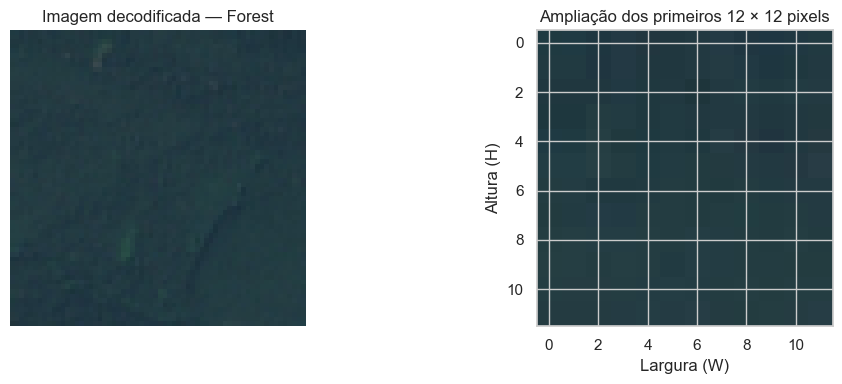

In [67]:
# -----------------------------------------------------------------------------
# Objetivo desta célula: Visualizar a imagem completa e ampliar uma pequena região de pixels.
# -----------------------------------------------------------------------------
# Colocamos a imagem completa e o recorte lado a lado para comparar escalas.
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].imshow(imagem_pil)
axes[0].set_title(f"Imagem decodificada — {amostra['classe']}")
axes[0].axis("off")

# O recorte usa somente uma região pequena para que pixels individuais apareçam.
recorte = imagem_np[:12, :12]
axes[1].imshow(recorte)
axes[1].set_title("Ampliação dos primeiros 12 × 12 pixels")
axes[1].set_xlabel("Largura (W)")
axes[1].set_ylabel("Altura (H)")
plt.tight_layout()


### Checkpoint 1 e 2 — resposta

- `H × W × C` significa altura, largura e canais; cada pixel RGB guarda três intensidades.
- `uint8 [0,255] → float32 [0,1]` ocorre no `ToTensor`.
- o arquivo não entra diretamente na rede: entram números reorganizados de `(H,W,C)` para `(C,H,W)`.

**Conclusão da seção:** a imagem visual e o tensor são duas representações do mesmo conteúdo, com convenções e escalas diferentes.


## 7. Canais RGB, escala de cinza e visualização numérica

**Pergunta de aprendizagem:** que informação cada canal carrega e o que se perde ao reduzir para cinza?

#### Do espectro da luz até uma imagem RGB

A luz é uma forma de radiação eletromagnética. O espectro eletromagnético inclui diferentes regiões:

`Raios gama → Raios X → Ultravioleta → Luz visível → Infravermelho → Micro-ondas → Ondas de rádio`

O olho humano percebe apenas uma pequena parte desse espectro, chamada de **luz visível**, com comprimentos de onda aproximadamente entre 380 e 750 nanômetros.

##### Espectro aproximado das cores visíveis

| Cor percebida | Comprimento de onda aproximado |
|---|---:|
| Violeta | 380–450 nm |
| Azul | 450–495 nm |
| Verde | 495–570 nm |
| Amarelo | 570–590 nm |
| Laranja | 590–620 nm |
| Vermelho | 620–750 nm |

Essas divisões são aproximações. O espectro é contínuo: não existe uma fronteira física rígida entre azul, verde, amarelo ou vermelho.

##### Como o espectro se transforma em RGB?

Uma câmera ou sensor não armazena diretamente todas as cores do espectro. Em uma imagem RGB, a luz recebida é resumida em três medições:

- `R`: intensidade associada à região vermelha;
- `G`: intensidade associada à região verde;
- `B`: intensidade associada à região azul.

O processo pode ser resumido assim:

`Luz refletida pela superfície → sensor → filtros vermelho, verde e azul → valores digitais R, G e B → imagem`

Cada canal mede uma faixa de comprimentos de onda, e não uma única cor ou frequência exata. As três medições são combinadas para representar computacionalmente as cores percebidas.

Cores como amarelo e laranja não precisam de canais próprios. Elas são representadas pela combinação de RGB:

| Combinação aproximada | Cor resultante |
|---|---|
| Vermelho + verde | Amarelo |
| Vermelho + pouco verde | Laranja |
| Verde + azul | Ciano |
| Vermelho + azul | Magenta |
| Vermelho + verde + azul | Branco |
| Ausência dos três canais | Preto |

Esse processo é chamado de **síntese aditiva de cores**, pois aumentar as intensidades luminosas dos canais produz novas cores.

#### Como canais RGB e pixels funcionam

Uma imagem RGB possui três canais. Cada pixel é representado por:

`Pixel = [R, G, B]`

Em uma imagem de 8 bits, cada canal pode assumir 256 valores:

`0 a 255`

Isso acontece porque:

\[
2^8 = 256
\]

A interpretação geral é:

- `0`: menor intensidade digital daquele canal;
- `255`: maior intensidade digital daquele canal.

Exemplos:

| RGB | Cor resultante |
|---|---|
| `[255, 0, 0]` | Vermelho |
| `[0, 255, 0]` | Verde |
| `[0, 0, 255]` | Azul |
| `[255, 255, 0]` | Amarelo |
| `[0, 255, 255]` | Ciano |
| `[255, 0, 255]` | Magenta |
| `[255, 255, 255]` | Branco |
| `[0, 0, 0]` | Preto |
| `[128, 128, 128]` | Cinza |

Na imagem `Forest_38.jpg`, um dos pixels possui:

`[31, 58, 65]`

Isso significa:

- vermelho com intensidade digital 31;
- verde com intensidade digital 58;
- azul com intensidade digital 65.

A combinação produz um tom escuro com predominância azul-esverdeada.

#### Os valores RGB possuem unidade física?

Os valores entre 0 e 255 são **níveis digitais**, também chamados de *Digital Numbers*. Eles não possuem uma unidade física direta.

Por exemplo, o valor `65` não significa:

- 65% de luz;
- 65 fótons;
- 65 watts.

Ele significa apenas que, depois da captura e do processamento, aquele canal recebeu o nível digital 65.

Quando usamos `ToTensor()`, o PyTorch divide esses valores por 255:

$$x_{normalizado}=\frac{x_{uint8}}{255}$$

Assim:

`uint8 [0,255] → float32 [0,1]`

Para o pixel `[31, 58, 65]`, temos aproximadamente:

`[0,122; 0,227; 0,255]`

A escala muda, mas a proporção entre os canais é preservada.

#### Relação com imagens de satélite

Materiais diferentes absorvem e refletem partes diferentes do espectro. A vegetação, por exemplo, costuma absorver bastante luz vermelha e refletir relativamente mais verde. Atmosfera, sombras, iluminação, resposta do sensor e processamento também influenciam os valores registrados.

Uma imagem RGB comum representa somente a região visível. Ela não contém diretamente informações de micro-ondas, raios gama ou infravermelho.

Satélites multiespectrais podem registrar outras bandas, como:

- azul;
- verde;
- vermelho;
- red edge;
- infravermelho próximo;
- infravermelho de ondas curtas.

No EuroSAT RGB utilizado neste projeto, trabalhamos somente com três canais visíveis:

`C = 3 → vermelho, verde e azul`

Portanto, RGB possui duas dimensões complementares:

- **origem física:** luz visível refletida pela superfície e medida pelo sensor;
- **representação computacional:** três matrizes numéricas combinadas para formar as cores da imagem.


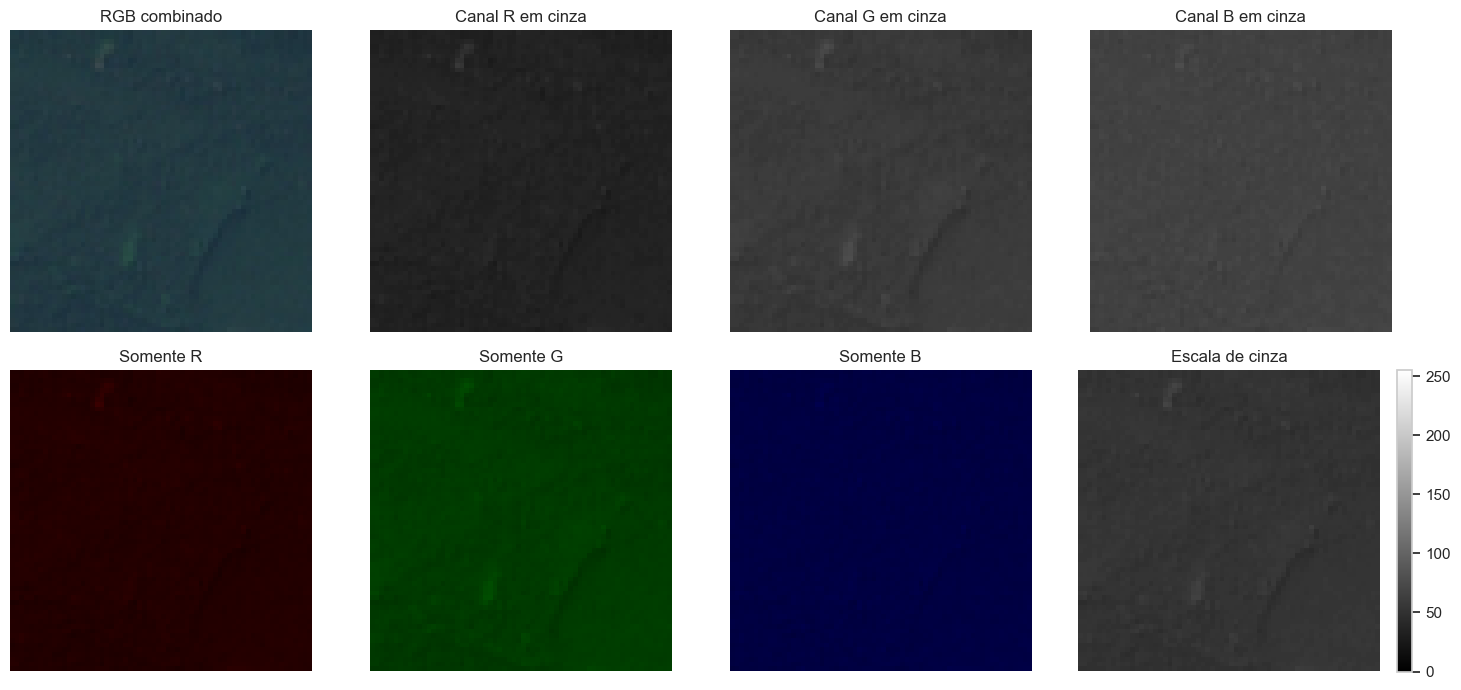

In [68]:
# -----------------------------------------------------------------------------
# Objetivo desta célula: Separar os canais RGB e comparar a informação visual de cada canal.
# -----------------------------------------------------------------------------
# A grade compara RGB, canais em cinza, canais coloridos e escala de cinza.
fig, axes = plt.subplots(2, 4, figsize=(15, 7))
axes[0, 0].imshow(imagem_np)
axes[0, 0].set_title("RGB combinado")
axes[0, 0].axis("off")

# Cada posição da última dimensão corresponde a R, G ou B.
cores = [(1, 0, 0), (0, 1, 0), (0, 0, 1)]
nomes = ["R", "G", "B"]
# Para cada canal, mostramos intensidades e uma imagem com as outras cores zeradas.
for i, (nome, cor) in enumerate(zip(nomes, cores)):
    canal = imagem_np[:, :, i]
    axes[0, i + 1].imshow(canal, cmap="gray", vmin=0, vmax=255)
    axes[0, i + 1].set_title(f"Canal {nome} em cinza")
    axes[0, i + 1].axis("off")
    isolada = np.zeros_like(imagem_np)
    isolada[:, :, i] = canal
    axes[1, i].imshow(isolada)
    axes[1, i].set_title(f"Somente {nome}")
    axes[1, i].axis("off")

# A conversão L combina RGB em uma única intensidade luminosa.
cinza = np.asarray(imagem_pil.convert("L"))
im = axes[1, 3].imshow(cinza, cmap="gray", vmin=0, vmax=255)
axes[1, 3].set_title("Escala de cinza")
axes[1, 3].axis("off")
fig.colorbar(im, ax=axes[1, 3], fraction=0.046)
plt.tight_layout()


,linha,coluna,RGB
0,0,0,"[31, 58, 65]"
1,32,32,"[38, 63, 68]"
2,-1,-1,"[33, 62, 70]"


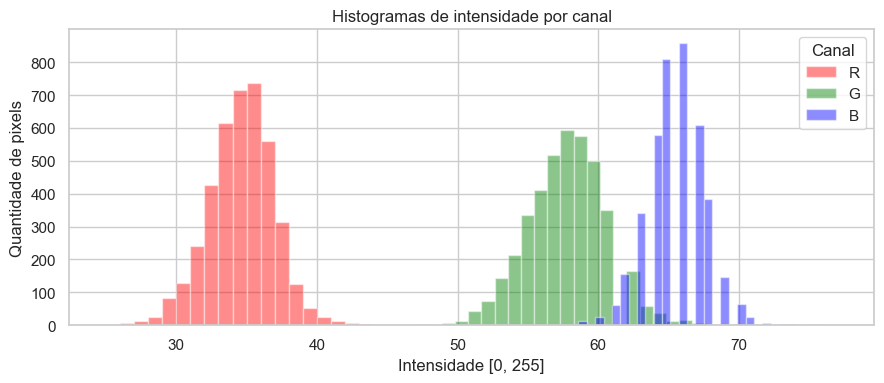

In [69]:
# -----------------------------------------------------------------------------
# Objetivo desta célula: Comparar histogramas RGB e inspecionar valores de pixels específicos.
# -----------------------------------------------------------------------------
# Histogramas mostram como as intensidades se distribuem em cada canal.
plt.figure(figsize=(9, 4))
for i, (nome, cor) in enumerate(zip(nomes, ["red", "green", "blue"])):
    plt.hist(imagem_np[:, :, i].ravel(), bins=32, alpha=0.45, color=cor, label=nome)
plt.title("Histogramas de intensidade por canal")
plt.xlabel("Intensidade [0, 255]")
plt.ylabel("Quantidade de pixels")
plt.legend(title="Canal")
plt.tight_layout()

# Inspecionamos o primeiro pixel, o pixel central e o último pixel.
pontos = [(0, 0), (imagem_np.shape[0] // 2, imagem_np.shape[1] // 2), (-1, -1)]
pixels_selecionados = [
    {"linha": y, "coluna": x, "RGB": imagem_np[y, x].tolist()}
    for y, x in pontos
]
display(pd.DataFrame(pixels_selecionados))


**Interpretação:** diferenças entre histogramas indicam como cada faixa visível participa da cena. A conversão para cinza combina canais e elimina distinções cromáticas potencialmente úteis. Isso ainda não representa bandas multiespectrais.

**Conclusão da seção:** RGB preserva três medições visíveis por pixel; cinza reduz informação para uma intensidade.


## 8. Transformações geométricas, interpolação e normalização

**Pergunta de aprendizagem:** por que padronizar tamanho e escala, e como fazer isso sem confundir visualização com entrada do modelo?

#### Redimensionamento e interpolação

A transformação de uma imagem de `64 × 64` para `224 × 224` é chamada de **redimensionamento** (*resize*).

Como estamos aumentando a imagem, também podemos chamar essa operação de **upsampling**.

```text
Imagem original:       64 × 64
Imagem redimensionada: 224 × 224
```

O fator de aumento em cada dimensão é:

$\frac{224}{64}=3{,}5$

A imagem original não possui valores para todas as novas posições da grade 224 × 224. O algoritmo precisa estimá-los usando os pixels existentes. A **interpolação** é o método utilizado durante o redimensionamento para estimar os valores dos novos pixels.

No notebook, utilizamos:

```python
transforms.Resize(
    (224, 224),
    interpolation=InterpolationMode.BILINEAR,
)
```

Isso significa:

```text
Resize   → operação de alterar o tamanho
Bilinear → método usado para calcular os novos pixels
```

##### Principais métodos de interpolação

- **Nearest neighbor:** copia o valor do pixel original mais próximo. É rápido, mas pode produzir blocos.
- **Bilinear:** combina os quatro pixels vizinhos mais próximos, produzindo transições mais suaves.
- **Bicubic:** considera uma vizinhança maior e pode gerar resultados ainda mais suaves.

É importante lembrar que aumentar a imagem não cria novos detalhes reais:

```text
64 × 64   = 4.096 pixels originais
224 × 224 = 50.176 posições após o resize
```

Os novos valores são estimados a partir dos pixels originais. O redimensionamento é necessário porque modelos como ResNet50 e ViT normalmente esperam imagens de entrada com `224 × 224` pixels.


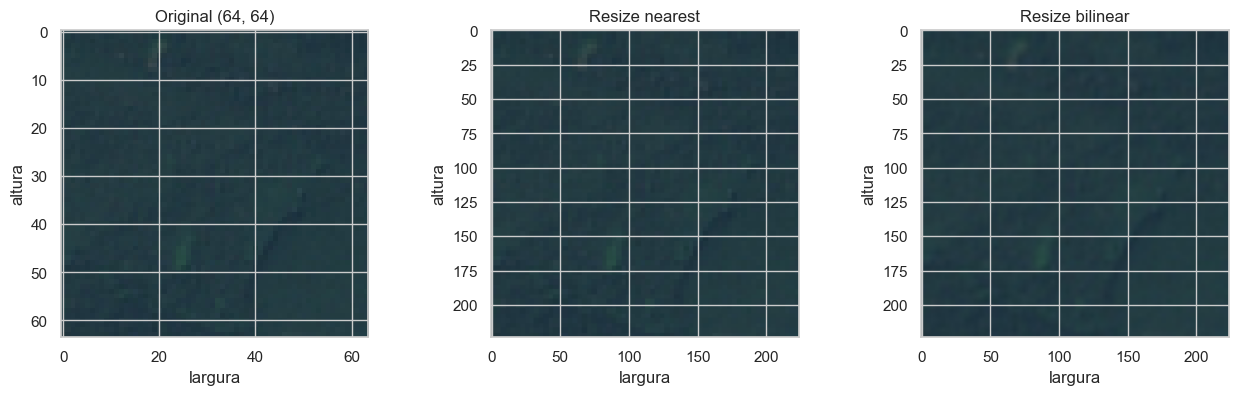

In [70]:
# -----------------------------------------------------------------------------
# Objetivo desta célula: Comparar os métodos nearest e bilinear durante o redimensionamento.
# -----------------------------------------------------------------------------
# Nearest copia o vizinho mais próximo; bilinear interpola quatro vizinhos.
resize_nearest = transforms.Resize(
    (CFG.img_size, CFG.img_size),
    interpolation=InterpolationMode.NEAREST,
)
resize_bilinear = transforms.Resize(
    (CFG.img_size, CFG.img_size),
    interpolation=InterpolationMode.BILINEAR,
)

# Aplicamos os dois métodos à mesma imagem para uma comparação justa.
t_nearest = resize_nearest(imagem_pil)
t_bilinear = resize_bilinear(imagem_pil)

# A grade mantém original e resultados lado a lado.
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, img, titulo in zip(
    axes, [imagem_pil, t_nearest, t_bilinear],
    [f"Original {imagem_pil.size}", "Resize nearest", "Resize bilinear"],
):
    ax.imshow(img)
    ax.set_title(titulo)
    ax.set_xlabel("largura")
    ax.set_ylabel("altura")
plt.tight_layout()


Antes da normalização: shape=(3, 224, 224), dtype=torch.float32, min=0.0980, max=0.3020
Depois da normalização: shape=(3, 224, 224), dtype=torch.float32, min=-1.6898, max=-0.4624


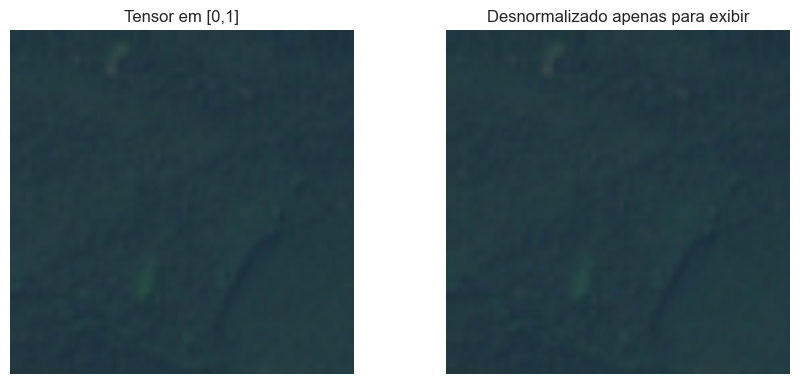

In [71]:
# -----------------------------------------------------------------------------
# Objetivo desta célula: Normalizar o tensor e desfazer a normalização somente para visualização.
# -----------------------------------------------------------------------------
# Estatísticas da ImageNet esperadas pelos pesos pré-treinados usados depois.
MEAN_IMAGENET = (0.485, 0.456, 0.406)
STD_IMAGENET = (0.229, 0.224, 0.225)
to_tensor = transforms.ToTensor()
normalizar = transforms.Normalize(MEAN_IMAGENET, STD_IMAGENET)

# Primeiro convertemos para [0,1]; depois centralizamos e escalamos cada canal.
x_01 = to_tensor(t_bilinear)
x_norm = normalizar(x_01)
resumo_tensor("Antes da normalização", x_01)
resumo_tensor("Depois da normalização", x_norm)

# A normalização é desfeita apenas na cópia usada para visualização.
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
axes[0].imshow(x_01.permute(1, 2, 0))
axes[0].set_title("Tensor em [0,1]")
axes[1].imshow(desnormalizar(x_norm, MEAN_IMAGENET, STD_IMAGENET).permute(1, 2, 0))
axes[1].set_title("Desnormalizado apenas para exibir")
for ax in axes:
    ax.axis("off")
plt.tight_layout()


**Interpretação:** resize altera a grade espacial, não o rótulo. Nearest preserva blocos; bilinear suaviza a interpolação. Normalização pode produzir valores negativos e acima de 1 — isso é esperado. Desnormalizamos somente para plotar.

**Conclusão da seção:** modelos exigem dimensões previsíveis e a normalização esperada pelos pesos pré-treinados.


## 9. Filtros clássicos e convolução passo a passo

**Pergunta de aprendizagem:** como um kernel local produz um mapa de características?

Para entrada de tamanho `H×W`, kernel `K`, padding `P` e stride `S`, a saída por eixo é `floor((H + 2P - K)/S) + 1`.

### Como o kernel produz um mapa de características

A convolução aplica um pequeno filtro, chamado **kernel**, sobre diferentes regiões da imagem. Em cada posição, os valores da janela são multiplicados pelos pesos do kernel e depois somados.

Neste exemplo, usamos uma janela `3 × 3`:

```text
[[0.200, 0.200, 0.188],
 [0.200, 0.200, 0.188],
 [0.192, 0.192, 0.192]]
```

e um kernel Sobel vertical:

```text
[[-1, 0, 1],
 [-2, 0, 2],
 [-1, 0, 1]]
```

Esse kernel compara aproximadamente o lado direito com o lado esquerdo da janela, procurando mudanças horizontais de intensidade que indicam bordas verticais.

#### Multiplicação elemento a elemento

```text
Janela                 Kernel               Produto

 0.200  0.200  0.188    -1  0  1          -0.200  0  0.188
 0.200  0.200  0.188 ×  -2  0  2    =     -0.400  0  0.376
 0.192  0.192  0.192    -1  0  1          -0.192  0  0.192
```

Somando os produtos:


$$(-0{,}200+0{,}188)+(-0{,}400+0{,}376)+(-0{,}192+0{,}192)
=-0{,}035294$$

Esse resultado corresponde a uma única ativação do mapa de características.

#### Interpretação da ativação

- valor positivo: a intensidade aumenta da esquerda para a direita;
- valor negativo: a intensidade diminui da esquerda para a direita;
- valor próximo de zero: pouca diferença entre os lados;
- grande valor absoluto: presença de uma borda mais intensa.

Como o resultado foi `-0,035294`, existe uma pequena redução de intensidade da esquerda para a direita, indicando uma borda fraca.

#### Formação do mapa de características

O kernel desliza sobre toda a entrada, produzindo uma ativação em cada posição.

Para:

```text
Entrada:  7 × 7
Kernel:   3 × 3
Stride:   1
Padding:  0
```

o tamanho da saída é:


$$\left\lfloor\frac{7+2(0)-3}{1}\right\rfloor+1=5$$

Portanto:

```text
Entrada 7 × 7
      ↓ kernel aplicado em 25 posições
Mapa de características 5 × 5
```

No exemplo, o kernel Sobel foi definido manualmente. Em uma CNN, os valores dos kernels são aprendidos por backpropagation.

```text
Filtro clássico → pesos definidos manualmente
CNN             → pesos aprendidos durante o treinamento
```

Uma camada também pode utilizar vários filtros:

```text
1 filtro    → 1 feature map
32 filtros → 32 feature maps
```

Assim, diferentes filtros podem aprender a identificar bordas, cores, texturas, formas e padrões mais abstratos.


In [72]:
# -----------------------------------------------------------------------------
# Objetivo desta célula: Implementar manualmente a convolução para observar cada operação.
# -----------------------------------------------------------------------------
# Esta implementação explícita prioriza entendimento, não desempenho.
def convolucao_2d_manual(entrada: np.ndarray, kernel: np.ndarray,
                         stride: int = 1, padding: int = 0) -> np.ndarray:
    '''Convolução 2D didática, sem rotação do kernel (correlação cruzada).'''
    # Padding adiciona uma borda de zeros antes de deslizar o kernel.
    entrada_pad = np.pad(entrada, padding, mode="constant")
    kh, kw = kernel.shape
    # Calculamos previamente as dimensões espaciais do mapa de saída.
    oh = (entrada_pad.shape[0] - kh) // stride + 1
    ow = (entrada_pad.shape[1] - kw) // stride + 1
    saida = np.zeros((oh, ow), dtype=np.float32)
    # Cada posição multiplica uma janela local pelo kernel e soma os produtos.
    for i in range(oh):
        for j in range(ow):
            janela = entrada_pad[i * stride:i * stride + kh, j * stride:j * stride + kw]
            saida[i, j] = np.sum(janela * kernel)
    return saida


# Usamos um recorte pequeno e normalizado para visualizar a conta completa.
janela = cinza[:7, :7].astype(np.float32) / 255
sobel_vertical = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype=np.float32)
produto = janela[:3, :3] * sobel_vertical
print("Janela 3×3:\n", np.round(janela[:3, :3], 3))
print("Kernel:\n", sobel_vertical)
print("Produto elemento a elemento:\n", np.round(produto, 3))
print("Soma / primeira ativação:", produto.sum())
display(pd.DataFrame(convolucao_2d_manual(janela, sobel_vertical)))


Janela 3×3:
 [[0.2   0.2   0.188]
 [0.2   0.2   0.188]
 [0.192 0.192 0.192]]
Kernel:
 [[-1.  0.  1.]
 [-2.  0.  2.]
 [-1.  0.  1.]]
Produto elemento a elemento:
 [[-0.2    0.     0.188]
 [-0.4    0.     0.376]
 [-0.192  0.     0.192]]
Soma / primeira ativação: -0.035294116


,0,1,2,3,4
0,-0.035294,0.019608,0.011765,-0.039216,0.015686
1,0.007843,0.035294,-0.011765,-0.023529,-0.003922
2,0.054902,0.035294,-0.050980,-0.007843,-0.003922
3,0.058824,0.003922,-0.074510,0.000000,0.000000
4,0.019608,-0.023529,-0.054902,0.007843,0.007843


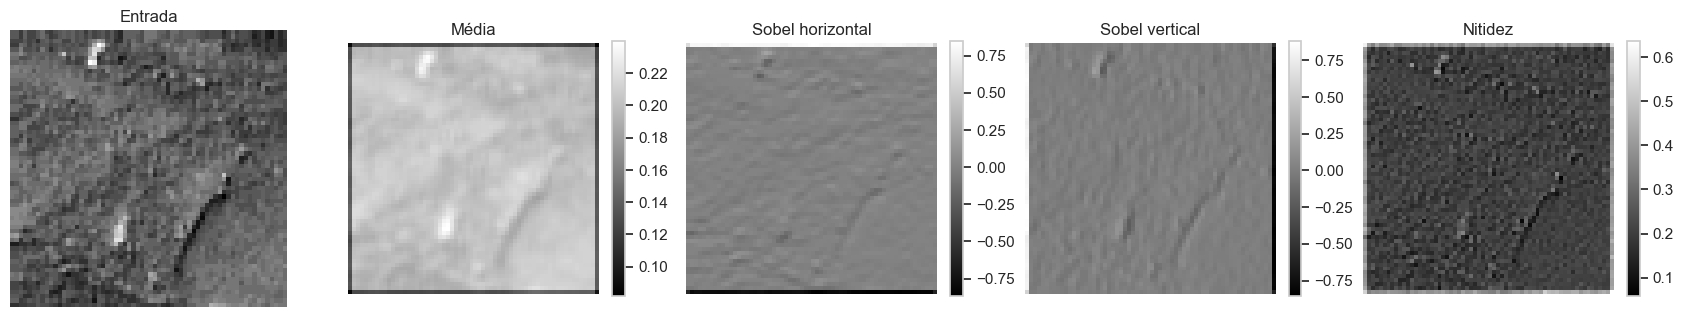

In [73]:
# -----------------------------------------------------------------------------
# Objetivo desta célula: Aplicar filtros clássicos e comparar seus mapas de características.
# -----------------------------------------------------------------------------
# Cada kernel enfatiza um tipo diferente de padrão local.
cinza_01 = cinza.astype(np.float32) / 255
kernels = {
    "Média": np.ones((3, 3), dtype=np.float32) / 9,
    "Sobel horizontal": np.array([[-1,-2,-1],[0,0,0],[1,2,1]], dtype=np.float32),
    "Sobel vertical": sobel_vertical,
    "Nitidez": np.array([[0,-1,0],[-1,5,-1],[0,-1,0]], dtype=np.float32),
}
# A entrada ocupa o primeiro eixo; os quatro mapas ocupam os seguintes.
fig, axes = plt.subplots(1, 5, figsize=(17, 4))
axes[0].imshow(cinza_01, cmap="gray")
axes[0].set_title("Entrada")
axes[0].axis("off")
# Padding 1 preserva altura e largura para kernels 3 × 3 com stride 1.
for ax, (nome, kernel) in zip(axes[1:], kernels.items()):
    mapa = convolucao_2d_manual(cinza_01, kernel, padding=1)
    im = ax.imshow(mapa, cmap="gray")
    ax.set_title(nome)
    ax.axis("off")
    fig.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()


In [74]:
# -----------------------------------------------------------------------------
# Objetivo desta célula: Reproduzir o filtro manual com uma camada Conv2d do PyTorch.
# -----------------------------------------------------------------------------
# As duas dimensões adicionadas representam batch N e canal C: (1,1,H,W).
x_gray = torch.from_numpy(cinza_01)[None, None]
conv = nn.Conv2d(1, 1, kernel_size=3, stride=1, padding=1, bias=False)
# Copiamos o Sobel para a camada e desativamos gradientes nesta demonstração.
with torch.no_grad():
    conv.weight.copy_(torch.from_numpy(sobel_vertical)[None, None])
    y_conv = conv(x_gray)

# allclose confirma numericamente que as duas implementações são equivalentes.
print("Entrada NCHW:", tuple(x_gray.shape), "→ saída NCHW:", tuple(y_conv.shape))
print("Saídas manual e PyTorch próximas:", np.allclose(
    convolucao_2d_manual(cinza_01, sobel_vertical, padding=1), y_conv[0, 0].numpy(), atol=1e-5
))


Entrada NCHW: (1, 1, 64, 64) → saída NCHW: (1, 1, 64, 64)
Saídas manual e PyTorch próximas: True


### Checkpoint 3 — resposta

- kernel define a vizinhança; stride define o salto; padding controla bordas e tamanho;
- um filtro gera um feature map; vários filtros geram vários canais de saída;
- filtros clássicos são fixos, enquanto `Conv2d` aprende os pesos por backpropagation.

**Conclusão da seção:** convolução transforma padrões locais em mapas que realçam propriedades úteis.


## 10. Ativação, pooling, feature maps e data augmentation

**Pergunta de aprendizagem:** como a rede reduz a dimensão e ganha diversidade sem alterar o significado da classe?

### Ativação, pooling, feature maps e data augmentation

Esta demonstração mostra como a ReLU modifica as ativações e como o Max Pooling reduz as dimensões espaciais de um feature map.

A entrada possui formato:

```text
(N, C, H, W) = (1, 1, 4, 4)
```

Isso significa:

- `N = 1`: uma amostra no batch;
- `C = 1`: um feature map ou canal;
- `H = 4`: quatro linhas;
- `W = 4`: quatro colunas.

A matriz de entrada é:

```text
[[-2,  1,  0,  3],
 [ 4, -1,  2,  0],
 [ 1,  5, -3,  2],
 [ 0,  2,  1,  4]]
```

#### Aplicação da ReLU

A função ReLU é definida por:


$$ReLU(x)=\max(0,x)$$

Ela mantém valores positivos e substitui valores negativos por zero:

```text
Entrada negativa → 0
Entrada positiva → permanece igual
```

Resultado:

```text
[[0, 1, 0, 3],
 [4, 0, 2, 0],
 [1, 5, 0, 2],
 [0, 2, 1, 4]]
```

O formato permanece igual:

```text
Antes da ReLU:  (1, 1, 4, 4)
Depois da ReLU: (1, 1, 4, 4)
```

A ReLU não reduz a imagem. Sua função é introduzir não linearidade e impedir que todas as camadas da rede sejam equivalentes a uma única transformação linear.

#### Aplicação do Max Pooling

Em seguida, aplicamos:

```python
F.max_pool2d(relu, kernel_size=2)
```

O Max Pooling divide o feature map em janelas `2 × 2` e conserva apenas o maior valor de cada janela.

### Janela superior esquerda

```text
[[0, 1],
 [4, 0]]
```

Maior valor:

```text
4
```

### Janela superior direita

```text
[[0, 3],
 [2, 0]]
```

Maior valor:

```text
3
```

### Janela inferior esquerda

```text
[[1, 5],
 [0, 2]]
```

Maior valor:

```text
5
```

### Janela inferior direita

```text
[[0, 2],
 [1, 4]]
```

Maior valor:

```text
4
```

Esses quatro valores formam a saída:

```text
[[4, 3],
 [5, 4]]
```

O formato muda de:

```text
(1, 1, 4, 4)
        ↓
(1, 1, 2, 2)
```

Portanto, o Max Pooling reduz altura e largura pela metade, mas preserva a quantidade de amostras e canais.

#### Por que reduzir as dimensões?

O pooling ajuda a:

- reduzir o custo computacional;
- diminuir o uso de memória;
- manter as ativações mais fortes;
- reduzir a sensibilidade a pequenos deslocamentos;
- concentrar a representação nos padrões mais importantes.

Entretanto, parte da informação espacial é descartada. Por isso, pooling excessivo pode eliminar detalhes relevantes.

#### O que é um feature map?

Um feature map é a saída produzida por um filtro convolucional. Ele indica onde determinado padrão foi encontrado.

```text
Filtro de bordas  → feature map de bordas
Filtro de textura → feature map de texturas
Filtro de cor     → feature map de cores
```

A sequência demonstrada é:

```text
Feature map original
        ↓
ReLU remove ativações negativas
        ↓
Max Pooling conserva ativações fortes
        ↓
Feature map menor e mais concentrado
```

#### Relação com data augmentation

ReLU e pooling modificam ativações **dentro da rede**. Data augmentation modifica as imagens **antes de entrarem na rede**.

Exemplos de augmentation:

- rotações;
- espelhamentos;
- recortes;
- mudanças moderadas de brilho, contraste ou saturação.

O objetivo é apresentar diferentes versões plausíveis da mesma imagem:

```text
Imagem original
        ↓ transformação aleatória
Nova versão da imagem, mas com a mesma classe
```

Por exemplo, uma imagem de floresta continua sendo floresta após uma pequena rotação ou espelhamento.

A augmentation aumenta a diversidade do treino, mas não cria informação completamente nova. Ela ensina ao modelo que pequenas transformações não devem alterar a classe.

Por isso:

```text
Treino     → transformações aleatórias
Validação  → transformações determinísticas
Teste      → transformações determinísticas
```

Em resumo:

```text
Data augmentation → aumenta a diversidade das entradas
Convolução         → produz feature maps
ReLU               → remove ativações negativas
Max Pooling        → reduz dimensões e conserva ativações fortes
```

In [75]:
# -----------------------------------------------------------------------------
# Objetivo desta célula: Demonstrar separadamente os efeitos de ReLU e Max Pooling.
# -----------------------------------------------------------------------------
# A matriz contém valores positivos e negativos para tornar o efeito visível.
matriz_exemplo = [
    [-2.0, 1.0, 0.0, 3.0],
    [4.0, -1.0, 2.0, 0.0],
    [1.0, 5.0, -3.0, 2.0],
    [0.0, 2.0, 1.0, 4.0],
]
# Adicionamos batch e canal para obter o formato NCHW esperado pelo pooling.
exemplo = torch.tensor(matriz_exemplo)[None, None]
# ReLU zera negativos; MaxPool conserva o maior valor de cada janela 2 × 2.
relu = F.relu(exemplo)
pooled = F.max_pool2d(relu, kernel_size=2)
print("Entrada:", tuple(exemplo.shape), "\n", exemplo[0, 0])
print("Após ReLU:", tuple(relu.shape), "\n", relu[0, 0])
print("Após MaxPool 2×2:", tuple(pooled.shape), "\n", pooled[0, 0])


Entrada: (1, 1, 4, 4) 
 tensor([[-2.,  1.,  0.,  3.],
        [ 4., -1.,  2.,  0.],
        [ 1.,  5., -3.,  2.],
        [ 0.,  2.,  1.,  4.]])
Após ReLU: (1, 1, 4, 4) 
 tensor([[0., 1., 0., 3.],
        [4., 0., 2., 0.],
        [1., 5., 0., 2.],
        [0., 2., 1., 4.]])
Após MaxPool 2×2: (1, 1, 2, 2) 
 tensor([[4., 3.],
        [5., 4.]])


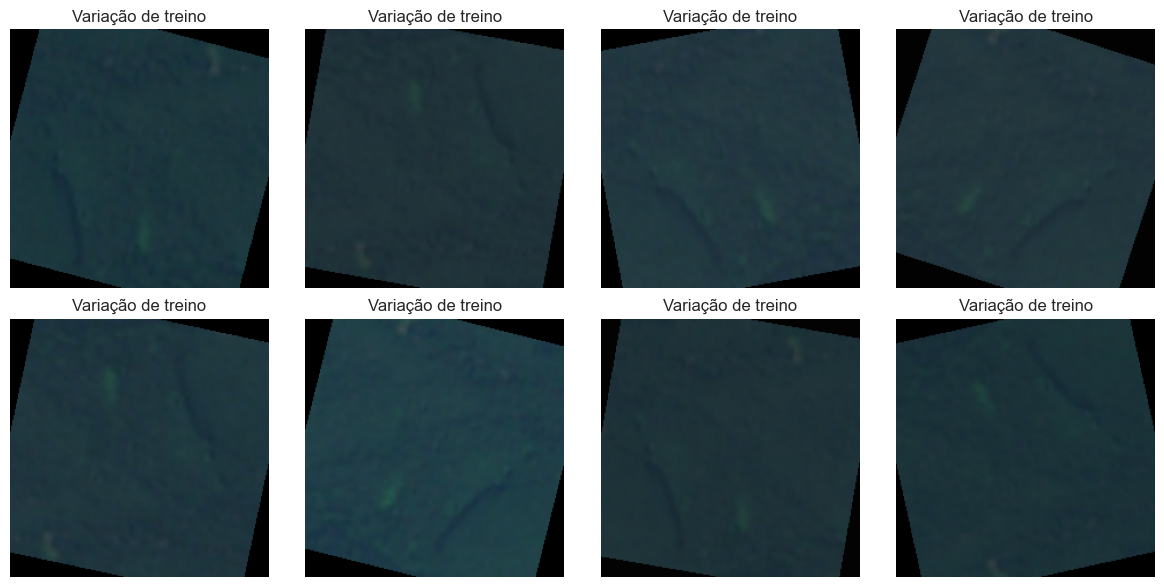

In [77]:
# -----------------------------------------------------------------------------
# Objetivo desta célula: Construir transformações distintas para treino e para avaliação.
# -----------------------------------------------------------------------------
# A pipeline de treino cria variações plausíveis para reduzir sobreajuste.
transform_treino = transforms.Compose([
    transforms.RandomResizedCrop(
        CFG.img_size,
        scale=(0.85, 1.0),
        interpolation=InterpolationMode.BILINEAR,
    ),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(20, interpolation=InterpolationMode.BILINEAR),
    transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.10),
    transforms.ToTensor(),
    transforms.Normalize(MEAN_IMAGENET, STD_IMAGENET),
])
# Validação e teste são determinísticos para manter a régua de avaliação fixa.
transform_avaliacao = transforms.Compose([
    transforms.Resize((CFG.img_size, CFG.img_size), interpolation=InterpolationMode.BILINEAR),
    transforms.ToTensor(),
    transforms.Normalize(MEAN_IMAGENET, STD_IMAGENET),
])

# Repetir a mesma transformação evidencia sua natureza aleatória.
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax in axes.flat:
    x_aug = transform_treino(imagem_pil)
    ax.imshow(desnormalizar(x_aug, MEAN_IMAGENET, STD_IMAGENET).permute(1, 2, 0))
    ax.set_title("Variação de treino")
    ax.axis("off")
plt.tight_layout()


### Checkpoint 4 — resposta

ReLU remove ativações negativas; MaxPool reduz custo e resolução espacial. Augmentation aumenta diversidade, não cria informação nova. Treino recebe variações moderadas; validação/teste usam transformação determinística para medir sempre o mesmo problema. Transformações agressivas podem apagar sinais úteis.

**Conclusão da seção:** a pipeline de treino ensina invariâncias plausíveis; a de avaliação mantém a régua estável.


## 11. Análise exploratória e qualidade dos dados

**Pergunta de aprendizagem:** há desbalanceamento, arquivos ilegíveis, formatos inesperados ou duplicatas exatas?


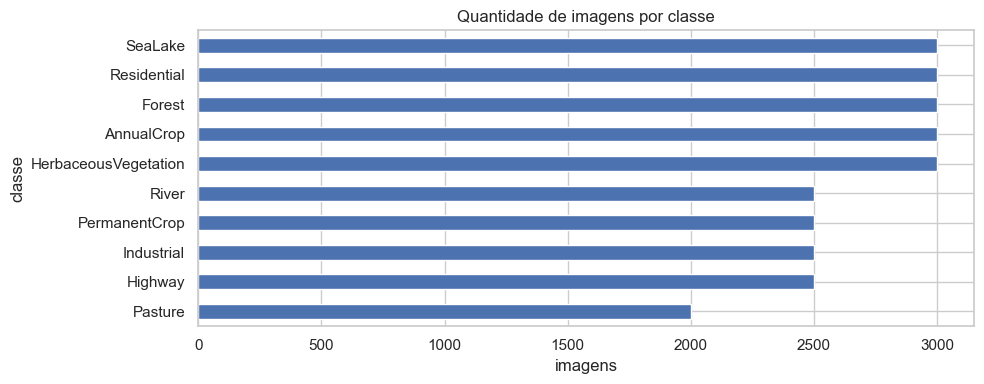

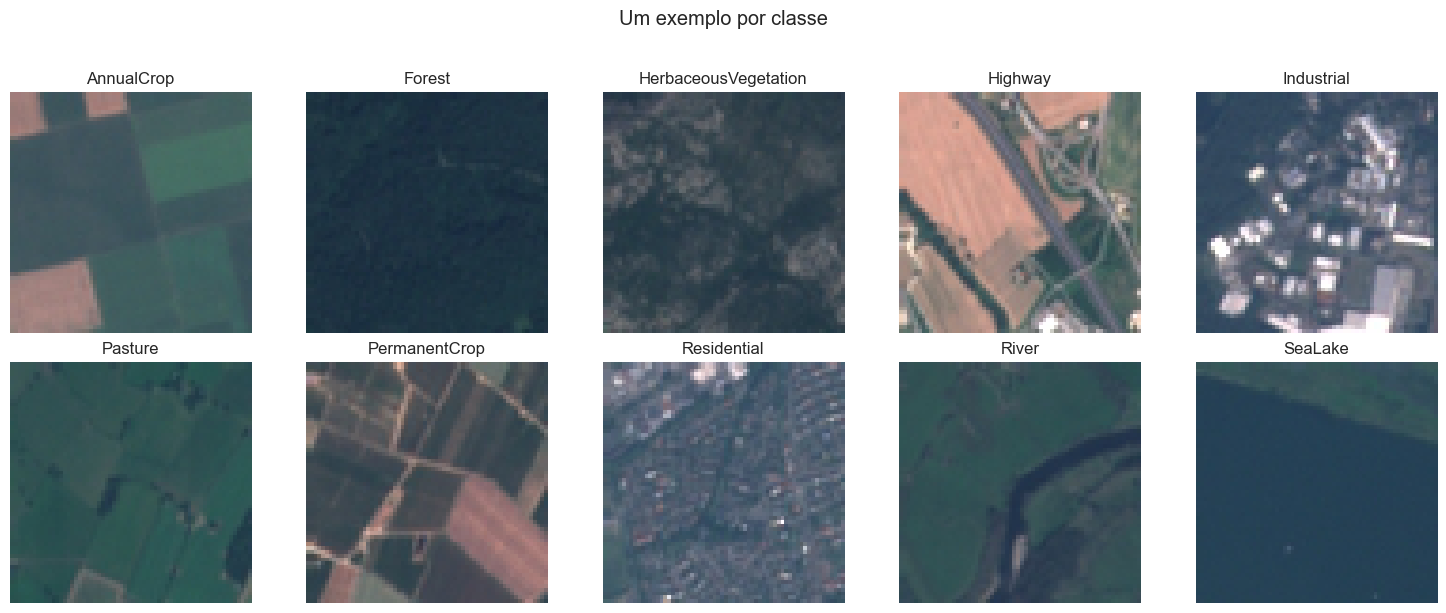

In [78]:
# -----------------------------------------------------------------------------
# Objetivo desta célula: Examinar distribuição e exemplos representativos das dez classes.
# -----------------------------------------------------------------------------
# O gráfico de barras permite detectar rapidamente desbalanceamento entre classes.
fig, ax = plt.subplots(figsize=(10, 4))
inventario["imagens"].sort_values().plot.barh(ax=ax)
ax.set_title("Quantidade de imagens por classe")
ax.set_xlabel("imagens")
ax.set_ylabel("classe")
plt.tight_layout()

# Em seguida, amostramos uma imagem reproduzível de cada uma das dez classes.
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for ax, classe in zip(axes.flat, CLASSES):
    linha = df_arquivos[df_arquivos["classe"].eq(classe)].sample(1, random_state=SEED).iloc[0]
    with Image.open(linha["caminho"]) as img:
        ax.imshow(img.convert("RGB"))
    ax.set_title(classe)
    ax.axis("off")
fig.suptitle("Um exemplo por classe", y=1.02)
plt.tight_layout()


In [79]:
# -----------------------------------------------------------------------------
# Objetivo desta célula: Verificar resolução, modo de cor e legibilidade dos arquivos.
# -----------------------------------------------------------------------------
# A função isola o tratamento de erro para que um arquivo ruim não esconda os demais.
def inspecionar_arquivo(caminho: Path) -> dict:
    """Valida a imagem e retorna suas propriedades básicas."""
    try:
        # verify valida a integridade sem decodificar toda a imagem.
        with Image.open(caminho) as img:
            img.verify()
        # Reabrimos porque verify encerra o uso normal do objeto PIL.
        with Image.open(caminho) as img:
            return {"largura": img.width, "altura": img.height, "modo": img.mode, "erro": None}
    except Exception as exc:
        return {"largura": np.nan, "altura": np.nan, "modo": None, "erro": repr(exc)}


# No modo rápido inspecionamos uma amostra; na execução completa, todos os arquivos.
if MODO_RAPIDO:
    tamanho_amostra = min(1500, len(df_arquivos))
    amostra_qc = df_arquivos.sample(tamanho_amostra, random_state=SEED)
else:
    amostra_qc = df_arquivos

# Convertemos os diagnósticos em tabela para resumir formatos e erros.
qc = pd.DataFrame([inspecionar_arquivo(p) for p in amostra_qc["caminho"]])
resumo_qualidade = (
    qc.groupby(["largura", "altura", "modo"], dropna=False)
    .size()
    .rename("arquivos")
    .reset_index()
)
display(resumo_qualidade)
print("Arquivos ilegíveis na verificação:", qc["erro"].notna().sum())


,largura,altura,modo,arquivos
0,64,64,RGB,1500


Arquivos ilegíveis na verificação: 0


In [80]:
# -----------------------------------------------------------------------------
# Objetivo desta célula: Detectar conteúdo duplicado antes da criação dos splits.
# -----------------------------------------------------------------------------
# MD5 é usado somente como impressão digital rápida de conteúdo, não para segurança.
def md5_arquivo(caminho: Path, bloco: int = 1 << 20) -> str:
    """Calcula uma impressão digital para detectar cópias exatas."""
    h = hashlib.md5()  # usado como impressão digital, não para segurança
    # Leitura em blocos evita carregar cada arquivo inteiro na memória.
    with caminho.open("rb") as f:
        while pedaco := f.read(bloco):
            h.update(pedaco)
    return h.hexdigest()


# Hashes iguais indicam cópias byte a byte do mesmo arquivo.
df_arquivos["md5"] = df_arquivos["caminho"].map(md5_arquivo)
duplicatas_exatas = df_arquivos.loc[df_arquivos["md5"].duplicated(keep=False)].sort_values("md5")
# A mesma imagem com rótulos diferentes representa inconsistência grave.
conflitos = duplicatas_exatas.groupby("md5")["classe"].nunique().gt(1)
if conflitos.any():
    raise ValueError(
        "Há imagens idênticas com rótulos diferentes. "
        "Revise esses arquivos antes de modelar."
    )
print(f"Cópias duplicadas encontradas: {len(duplicatas_exatas)}")
display(duplicatas_exatas[["caminho_relativo", "classe", "md5"]].head(20))


Cópias duplicadas encontradas: 0


,caminho_relativo,classe,md5


**Interpretação:** `AnnualCrop`, `PermanentCrop`, `Pasture` e `HerbaceousVegetation` podem compartilhar texturas; `Highway` e `River` podem compartilhar estruturas lineares. Duplicatas exatas atravessando splits seriam vazamento e devem ser agrupadas ou removidas antes de continuar.

**Conclusão da seção:** qualidade não é só “o arquivo abre”; inclui distribuição, resolução, ambiguidade visual e independência entre amostras.


## 12. Separação estratificada, Dataset e DataLoaders

**Pergunta de aprendizagem:** como garantir exatamente os mesmos splits em todos os experimentos?

Criamos o split uma vez, persistimos caminhos relativos e registramos um fingerprint. Augmentation não participa da divisão.


In [81]:
# -----------------------------------------------------------------------------
# Objetivo desta célula: Criar ou carregar splits estratificados, persistentes e sem vazamento.
# -----------------------------------------------------------------------------
# Reutilizar o CSV existente garante os mesmos exemplos em todos os modelos.
if SPLIT_FILE.exists():
    df_splits = pd.read_csv(SPLIT_FILE)
    esperadas = {"caminho_relativo", "classe", "label", "split"}
    if not esperadas.issubset(df_splits.columns):
        raise ValueError(f"Split existente inválido: faltam {esperadas - set(df_splits.columns)}")
else:
    # Se ainda não existe CSV, criamos uma única divisão oficial.
    # Uma única cópia por conteúdo impede que arquivos idênticos atravessem splits.
    df_para_split = df_arquivos.drop_duplicates("md5", keep="first").copy()
    # Primeiro isolamos o teste, que permanecerá intocado durante a seleção.
    treino_val, teste = train_test_split(
        df_para_split, test_size=CFG.test_size, random_state=SEED, stratify=df_para_split["classe"]
    )
    # Ajustamos a fração relativa porque a segunda divisão ocorre sem o teste.
    fracao_val_relativa = CFG.val_size / (1 - CFG.test_size)
    treino, validacao = train_test_split(
        treino_val, test_size=fracao_val_relativa, random_state=SEED, stratify=treino_val["classe"]
    )
    # Registramos o nome do split em cada linha antes de concatenar.
    partes = []
    for nome, parte in (("treino", treino), ("validacao", validacao), ("teste", teste)):
        partes.append(parte.assign(split=nome))
    colunas_split = ["caminho_relativo", "classe", "label", "split"]
    df_splits = pd.concat(partes, ignore_index=True)[colunas_split]
    df_splits.to_csv(SPLIT_FILE, index=False)

# Caminhos relativos tornam o CSV portátil; caminhos absolutos são reconstruídos em memória.
df_splits["caminho"] = df_splits["caminho_relativo"].map(lambda p: ROOT / p)
arquivos_existem = df_splits["caminho"].map(Path.exists).all()
assert arquivos_existem, "O arquivo de split aponta para imagens ausentes."
# Reanexamos os hashes para confirmar que nenhuma duplicata atravessa os splits.
hash_por_caminho = df_arquivos.set_index("caminho_relativo")["md5"]
df_splits["md5"] = df_splits["caminho_relativo"].map(hash_por_caminho)
if df_splits["md5"].isna().any() or df_splits["md5"].duplicated().any():
    raise ValueError(
        "O split persistido contém caminhos desconhecidos ou conteúdo duplicado; "
        "revise-o e regenere."
    )
assert_splits_disjuntos(df_splits)
print("Fingerprint do split:", fingerprint_splits(df_splits))
display(pd.crosstab(df_splits["classe"], df_splits["split"], margins=True))


Fingerprint do split: c3b4fc18906f34dc


split,teste,treino,validacao,All
classe,,,,
AnnualCrop,450,2100,450,3000
Forest,450,2100,450,3000
HerbaceousVegetation,450,2099,451,3000
Highway,375,1750,375,2500
Industrial,375,1750,375,2500
Pasture,300,1400,300,2000
PermanentCrop,375,1750,375,2500
Residential,450,2100,450,3000
River,375,1750,375,2500


In [82]:
# -----------------------------------------------------------------------------
# Objetivo desta célula: Implementar o Dataset e criar DataLoaders reprodutíveis.
# -----------------------------------------------------------------------------
# O Dataset guarda apenas caminhos e abre cada imagem sob demanda.
class EuroSATPaths(Dataset):
    '''Dataset orientado pela tabela persistida de caminhos e splits.'''

    def __init__(
        self,
        tabela: pd.DataFrame,
        transformacao: Callable,
    ) -> None:
        # Resetar o índice permite acessar qualquer amostra por posição inteira.
        self.tabela = tabela.reset_index(drop=True).copy()
        self.transformacao = transformacao

    # O DataLoader consulta este método para saber quantas amostras existem.
    def __len__(self) -> int:
        return len(self.tabela)

    # Retorna exatamente um par (imagem transformada, rótulo inteiro).
    def __getitem__(self, indice: int) -> tuple[torch.Tensor, int]:
        linha = self.tabela.iloc[indice]

        # A imagem é aberta somente quando solicitada, evitando manter
        # milhares de arquivos simultaneamente na memória.
        with Image.open(linha["caminho"]) as img:
            imagem = img.convert("RGB")

        # A transformação adequada ao split é aplicada somente neste momento.
        return self.transformacao(imagem), int(linha["label"])


# Esta função centraliza a ordem treino, validação e teste.
def tabelas_experimento(
    modo_rapido: bool = MODO_RAPIDO,
) -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    """Retorna treino, validação e teste na ordem oficial."""
    nomes_splits = ("treino", "validacao", "teste")
    partes = [
        df_splits[df_splits["split"].eq(nome)].copy()
        for nome in nomes_splits
    ]

    # A redução é feita dentro de cada split e mantém todas as classes.
    if modo_rapido:
        partes = [subconjunto_rapido(parte) for parte in partes]

    return tuple(partes)


# Constrói os três DataLoaders a partir da mesma tabela oficial.
def criar_loaders(
    batch_size: int,
    modo_rapido: bool = MODO_RAPIDO,
    transform_train: Callable = transform_treino,
    transform_eval: Callable = transform_avaliacao,
) -> tuple[DataLoader, DataLoader, DataLoader]:
    """Cria os três DataLoaders com transformações apropriadas."""
    treino_df, val_df, teste_df = tabelas_experimento(modo_rapido)
    # Somente o treino recebe augmentation; validação e teste são determinísticos.
    datasets = (
        EuroSATPaths(treino_df, transform_train),
        EuroSATPaths(val_df, transform_eval),
        EuroSATPaths(teste_df, transform_eval),
    )
    # shuffle ocorre apenas no treino; pin_memory acelera transferências para CUDA.
    loaders = tuple(
        DataLoader(
            dataset,
            batch_size=batch_size,
            shuffle=(indice == 0),
            num_workers=CFG.num_workers,
            pin_memory=torch.cuda.is_available(),
            worker_init_fn=worker_seed,
            generator=criar_gerador(SEED),
            persistent_workers=CFG.num_workers > 0,
        )
        for indice, dataset in enumerate(datasets)
    )
    return loaders


# Um primeiro lote confirma imediatamente shapes e integração do pipeline.
train_loader, val_loader, test_loader = criar_loaders(batch_size=32)
x_batch, y_batch = next(iter(train_loader))
print("Batch NCHW:", tuple(x_batch.shape), "| labels N:", tuple(y_batch.shape))


Batch NCHW: (32, 3, 224, 224) | labels N: (32,)


### Checkpoint 5 — resposta

Todos os modelos leem `splits_eurosat_seed42.csv`; somente a transformação e o `batch_size` podem mudar. O teste não seleciona arquitetura, hiperparâmetros, época ou modelo. O fingerprint permite detectar alterações acidentais.

## O que aprendemos antes de modelar

O arquivo comprimido foi decodificado em pixels RGB, convertido de `uint8 HWC` para `float32 CHW`, redimensionado, normalizado e agrupado em lotes NCHW. Vimos filtros fixos, feature maps, ReLU, pooling e augmentation. Agora os modelos podem receber a mesma evidência, sem vazamento.


# Parte II — Modelagem e benchmark

## 13. Baseline e protocolo experimental comum

**Pergunta de aprendizagem:** como acompanhar o início, o meio e o fim de cada experimento sem esconder etapas importantes?

Nesta Parte II, a repetição é **intencional e pedagógica**. Cada modelo apresenta novamente seu próprio fluxo:

1. Separar treino, validação e teste.
2. Criar transformações quando forem específicas do modelo.
3. Criar Dataset.
4. Criar DataLoader.
5. Construir ou carregar o modelo.
6. Definir loss.
7. Definir otimizador e scheduler.
8. Executar treino.
9. Executar validação.
10. Selecionar a melhor época ou configuração.
11. Avaliar uma única vez no teste.
12. Calcular métricas, criar gráficos e salvar artefatos.

Algumas linhas poderiam ser transformadas em funções reutilizáveis, mas foram mantidas visíveis para permitir acompanhar todo o processo de cada técnica de forma independente.

### O que continua igual para garantir uma comparação justa

- split e semente idênticos;
- seleção por **F1 Macro de validação**;
- teste intocado até a versão final;
- métricas comuns: accuracy, precision/recall/F1 Macro, Log Loss, AUC OVR Macro e F1 por classe;
- custos comuns: treino, inferência, parâmetros treináveis e tamanho do artefato.

Uma baseline majoritária contextualiza o problema, mas não integra as quatro metodologias finais.

In [83]:
# -----------------------------------------------------------------------------
# Objetivo desta célula: Iniciar a Parte II e registrar claramente o protocolo comum.
# -----------------------------------------------------------------------------
# A Parte II evita funções genéricas de treino e avaliação.
# Cada modelo terá seu próprio fluxo explícito:
# dados -> DataLoaders -> modelo -> loss -> otimizador -> treino -> validação -> teste.
RESULTADOS = {}

# Esta tabela funciona como um contrato do benchmark.
# As regras abaixo serão repetidas e aplicadas em cada modelo.
protocolo_benchmark = pd.DataFrame({
    "regra": [
        "Split",
        "Seleção do melhor modelo",
        "Uso do teste",
        "Métrica principal",
        "Métricas complementares",
        "Custos registrados",
    ],
    "decisão": [
        "Mesmo CSV splits_eurosat_seed42.csv",
        "F1 Macro de validação",
        "Uma única vez após finalizar as decisões",
        "F1 Macro",
        "Accuracy, Precision Macro, Recall Macro, Log Loss, AUC e F1 por classe",
        "Tempo de treino, inferência, parâmetros treináveis e tamanho",
    ],
})

display(protocolo_benchmark)
print("Dispositivo dos experimentos:", DEVICE)
print("Modo rápido:", MODO_RAPIDO)
print("Treinamentos autorizados:", EXECUTAR_TREINOS)

,regra,decisão
0,Split,Mesmo CSV splits_eurosat_seed42.csv
1,Seleção do melhor modelo,F1 Macro de validação
2,Uso do teste,Uma única vez após finalizar as decisões
3,Métrica principal,F1 Macro
4,Métricas complementares,"Accuracy, Precision Macro, Recall Macro, Log L..."
5,Custos registrados,"Tempo de treino, inferência, parâmetros treiná..."


Dispositivo dos experimentos: cuda
Modo rápido: True
Treinamentos autorizados: True


In [84]:
# -----------------------------------------------------------------------------
# Objetivo desta célula: Calcular uma baseline simples antes dos modelos neurais.
# -----------------------------------------------------------------------------
# Separamos explicitamente a validação usando o CSV oficial.
baseline_validacao_df = df_splits[
    df_splits["split"].eq("validacao")
].copy()

# No modo rápido, usamos até 120 exemplos de cada classe.
if MODO_RAPIDO:
    partes_baseline = []

    for _, grupo_classe in baseline_validacao_df.groupby("classe"):
        quantidade = min(120, len(grupo_classe))

        partes_baseline.append(
            grupo_classe.sample(
                n=quantidade,
                random_state=SEED,
            )
        )

    baseline_validacao_df = pd.concat(
        partes_baseline,
        ignore_index=True,
    )

# A classe majoritária é descoberta somente no treino.
classe_majoritaria = (
    df_splits.loc[
        df_splits["split"].eq("treino"),
        "label",
    ]
    .mode()
    .iloc[0]
)

# A baseline prevê a mesma classe para todas as imagens de validação.
y_baseline = baseline_validacao_df["label"].to_numpy()
pred_baseline = np.full(
    shape=len(y_baseline),
    fill_value=classe_majoritaria,
)

# Calculamos as métricas diretamente, sem esconder a operação em uma função.
metricas_baseline = pd.DataFrame({
    "métrica": [
        "Accuracy",
        "Precision Macro",
        "Recall Macro",
        "F1 Macro",
    ],
    "valor": [
        accuracy_score(y_baseline, pred_baseline),
        precision_score(y_baseline, pred_baseline, average="macro", zero_division=0),
        recall_score(y_baseline, pred_baseline, average="macro", zero_division=0),
        f1_score(y_baseline, pred_baseline, average="macro", zero_division=0),
    ],
})

print("Classe prevista pela baseline:", CLASSES[int(classe_majoritaria)])
display(metricas_baseline)

Classe prevista pela baseline: AnnualCrop


,métrica,valor
0,Accuracy,0.100000
1,Precision Macro,0.010000
2,Recall Macro,0.100000
3,F1 Macro,0.018182


**Interpretação:** accuracy pode parecer aceitável mesmo ignorando classes; F1 Macro pune esse comportamento. AUC usa probabilidades e mede separação OVR, mas não substitui análise da matriz de confusão.

**Conclusão da seção:** o protocolo separa seleção (validação) de estimativa final (teste) e mede desempenho e custo.


## 14. CNN desenvolvida do zero

**Pergunta de aprendizagem:** o que uma CNN consegue aprender sem pesos externos?

### Ideia central: uma única rede processa o batch inteiro

Não existem 32 CNNs diferentes quando `batch_size=32`. Existe **uma única CNN**, com um único conjunto de pesos compartilhados, aplicada paralelamente às 32 imagens. A dimensão `N` identifica as imagens e nunca é misturada pelo `Flatten`.

```text
32 imagens RGB transformadas
(N, C, H, W) = (32, 3, 224, 224)
        ↓
Bloco 1: Conv → BatchNorm → ReLU → MaxPool → Dropout2d
(32, 32, 112, 112)
        ↓
Bloco 2: Conv → BatchNorm → ReLU → MaxPool → Dropout2d
(32, 64, 56, 56)
        ↓
Bloco 3: Conv → BatchNorm → ReLU → MaxPool → Dropout2d
(32, 128, 28, 28)
        ↓
AdaptiveAvgPool2d(4, 4)
(32, 128, 4, 4)
        ↓
Flatten por imagem
(32, 2048)
        ↓
Linear → ReLU → Dropout
(32, 256)
        ↓
Linear de saída
(32, 10 logits)
```

Os valores acima usam a configuração padrão `filtros=32` e `dimensao_fc=256`. O primeiro eixo continua representando as 32 imagens durante todo o percurso.

### 1. Convolução: procurar padrões locais

Um filtro não observa a imagem inteira de uma vez. Para produzir uma ativação, ele combina uma pequena janela dos canais de entrada com seus pesos:

$$
Y_{n,k,i,j} = b_k + \sum_c \sum_u \sum_v W_{k,c,u,v}\,X_{n,c,i+u,j+v}
$$

- $n$: imagem dentro do batch;
- $k$: filtro e canal de saída;
- $c$: canal de entrada;
- $(i,j)$: posição espacial;
- $(u,v)$: posição dentro do kernel;
- $W$: pesos aprendidos por backpropagation.

Com kernel $3\times3$, `stride=1` e `padding=1`, a convolução preserva altura e largura. A dimensão de saída por eixo é:

$$
H_{out}=\left\lfloor\frac{H+2P-K}{S}\right\rfloor+1
$$

### 2. Batch Normalization: estabilizar as ativações

Para cada canal, a BatchNorm normaliza as ativações do mini-batch e aprende uma nova escala e deslocamento:

$$
\hat{x}=\frac{x-\mu_B}{\sqrt{\sigma_B^2+\varepsilon}},\qquad y=\gamma\hat{x}+\beta
$$

Durante o treino, $\mu_B$ e $\sigma_B^2$ vêm do batch. Durante a avaliação, `modelo.eval()` utiliza as estatísticas acumuladas.

### 3. ReLU: introduzir não linearidade

$$
ReLU(x)=\max(0,x)
$$

Sem uma ativação não linear, várias convoluções seriam equivalentes a uma única transformação linear e a rede teria menor capacidade de representar padrões complexos.

### 4. Max Pooling: reduzir a resolução espacial

O `MaxPool2d(2)` divide cada feature map em regiões $2\times2$ e conserva o maior valor. Assim, `224 → 112 → 56 → 28`. O número de canais não muda no pooling; apenas `H` e `W` diminuem.

### 5. Dropout: regularizar

Durante o treino, o Dropout zera aleatoriamente parte das ativações. Isso reduz dependências excessivas entre features. Na avaliação, `modelo.eval()` desativa esse sorteio e utiliza toda a rede.

### 6. Pool adaptativo e Flatten

O `AdaptiveAvgPool2d((4,4))` resume cada um dos 128 canais em uma grade $4\times4$. Depois, o Flatten reorganiza **cada imagem separadamente**:

$$
128\times4\times4=2048	ext{ características por imagem}
$$

Portanto, `(32,128,4,4)` vira `(32,2048)`, e não um único vetor misturando o batch.

### 7. Camadas densas, logits e probabilidades

A última camada produz dez logits $z_1,\ldots,z_{10}$ por imagem. Logits são escores livres, ainda não probabilidades. A Softmax os converte em probabilidades que somam 1:

$$
p_k=\frac{e^{z_k}}{\sum_{j=1}^{10}e^{z_j}}
$$

No treino, `CrossEntropyLoss` combina internamente LogSoftmax e Log Loss. Para um batch com $N$ imagens:

$$
\mathcal{L}=-\frac{1}{N}\sum_{n=1}^{N}\log p_{n,y_n}
$$

### 8. Uma atualização dos pesos por batch

```text
32 imagens → forward → 32 previsões → loss média
→ backward → gradientes médios → optimizer.step()
→ uma atualização dos pesos compartilhados
```

| Teoria | Implementação abaixo |
|---|---|
| Extração de padrões locais | `nn.Conv2d` |
| Normalização das ativações | `nn.BatchNorm2d` |
| Não linearidade | `nn.ReLU` |
| Redução espacial | `nn.MaxPool2d` e `nn.AdaptiveAvgPool2d` |
| Regularização | `nn.Dropout2d` e `nn.Dropout` |
| Vetor por imagem | `nn.Flatten` |
| Dez escores de classe | `nn.Linear(..., num_classes)` |

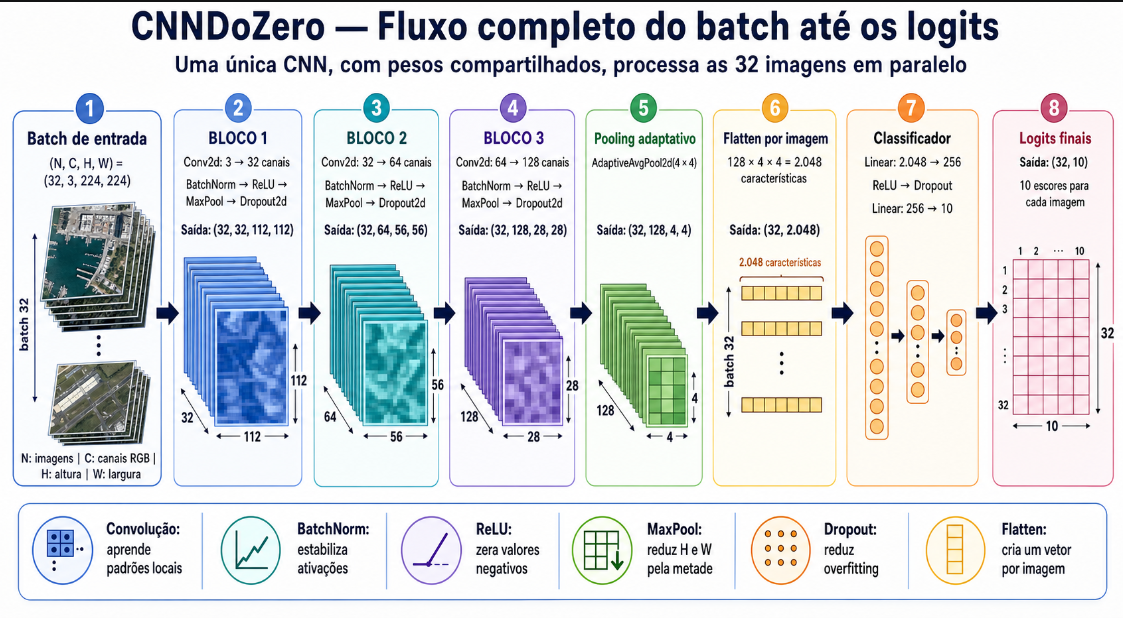


In [52]:
# -----------------------------------------------------------------------------
# Objetivo desta célula:
# Construir uma CNN manualmente, organizando suas camadas em blocos explícitos,
# e verificar o formato do tensor na entrada e na saída.
# -----------------------------------------------------------------------------


# A classe CNNDoZero herda de nn.Module.
# nn.Module é a classe-base utilizada pelo PyTorch para redes neurais.
# Ao herdar dela, o PyTorch consegue:
# - localizar os parâmetros treináveis;
# - mover o modelo para CPU ou GPU;
# - salvar e carregar os pesos;
# - alternar entre treino e avaliação;
# - calcular gradientes durante o backpropagation.
class CNNDoZero(nn.Module):

    # Docstring: descrição resumida da responsabilidade da classe.
    """CNN didática construída manualmente para as dez classes do EuroSAT."""

    # -------------------------------------------------------------------------
    # MÉTODO CONSTRUTOR
    # -------------------------------------------------------------------------
    # __init__ é executado quando criamos uma instância da classe:
    #
    # modelo = CNNDoZero(...)
    #
    # Ele define todas as camadas que existirão na rede.
    def __init__(
        self,

        # Quantidade de classes que a rede deve prever.
        # No EuroSAT RGB temos dez classes.
        num_classes: int = 10,

        # Quantidade de filtros produzidos pela primeira convolução.
        # Os próximos blocos usarão filtros*2 e filtros*4.
        filtros: int = 32,

        # Quantidade de neurônios da primeira camada totalmente conectada.
        dimensao_fc: int = 256,

        # Probabilidade de desligamento usada pelo Dropout.
        # 0.35 significa que aproximadamente 35% das ativações serão
        # zeradas aleatoriamente durante o treinamento.
        dropout: float = 0.35,
    ):

        # Inicializa a parte da classe que pertence a nn.Module.
        # Essa chamada é obrigatória para que o PyTorch registre corretamente
        # as camadas e seus parâmetros treináveis.
        super().__init__()

        # =====================================================================
        # BLOCO CONVOLUCIONAL 1
        # =====================================================================
        # Formato esperado na entrada:
        #
        # (N, 3, 224, 224)
        #
        # N   = quantidade de imagens no batch
        # 3   = canais RGB
        # 224 = altura
        # 224 = largura
        #
        # Com filtros=32, a saída do bloco será:
        #
        # (N, 32, 112, 112)
        # =====================================================================
        self.bloco1 = nn.Sequential(

            # -----------------------------------------------------------------
            # CONVOLUÇÃO
            # -----------------------------------------------------------------
            # Recebe três canais RGB e produz "filtros" feature maps.
            #
            # in_channels=3:
            #   a entrada possui os canais vermelho, verde e azul.
            #
            # out_channels=filtros:
            #   com filtros=32, a camada aprende 32 kernels diferentes.
            #
            # kernel_size=3:
            #   cada kernel observa uma região local de 3x3 pixels.
            #
            # padding=1:
            #   adiciona uma borda de zeros de tamanho 1.
            #   Com stride=1, isso preserva altura e largura:
            #   224x224 permanece 224x224.
            #
            # bias=False:
            #   remove o bias da convolução porque a BatchNorm aplicada
            #   logo depois já possui parâmetros de deslocamento.
            nn.Conv2d(
                in_channels=3,
                out_channels=filtros,
                kernel_size=3,
                padding=1,
                bias=False,
            ),

            # Normaliza separadamente as ativações de cada feature map.
            #
            # Com filtros=32, existem 32 canais para normalizar.
            # A BatchNorm ajuda a estabilizar e acelerar o treinamento.
            #
            # Shape:
            # (N, 32, 224, 224) -> (N, 32, 224, 224)
            nn.BatchNorm2d(
                num_features=filtros,
            ),

            # Aplica a função de ativação ReLU:
            #
            # ReLU(x) = max(0, x)
            #
            # Valores negativos viram zero e valores positivos são mantidos.
            # A ReLU introduz não linearidade na rede.
            #
            # inplace=True permite reutilizar parte da memória do tensor.
            nn.ReLU(
                inplace=True,
            ),

            # Divide cada feature map em janelas 2x2 e conserva o maior valor.
            #
            # Como o stride padrão é igual ao kernel_size, a altura e a largura
            # são reduzidas pela metade:
            #
            # 224x224 -> 112x112
            #
            # A quantidade de canais continua igual a "filtros".
            nn.MaxPool2d(
                kernel_size=2,
            ),

            # Dropout2d desliga canais completos dos feature maps durante
            # o treinamento, ajudando a reduzir o overfitting.
            #
            # Se dropout=0.35:
            #
            # dropout / 2 = 0.175
            #
            # Portanto, a probabilidade utilizada nos blocos convolucionais
            # será de 17,5%.
            #
            # Dropout não altera o shape do tensor.
            nn.Dropout2d(
                p=dropout / 2,
            ),
        )

        # =====================================================================
        # BLOCO CONVOLUCIONAL 2
        # =====================================================================
        # Entrada:
        # (N, filtros, 112, 112)
        #
        # Com filtros=32:
        # (N, 32, 112, 112)
        #
        # Saída:
        # (N, filtros*2, 56, 56)
        #
        # Com filtros=32:
        # (N, 64, 56, 56)
        # =====================================================================
        self.bloco2 = nn.Sequential(

            # A segunda convolução recebe os canais produzidos pelo bloco 1.
            #
            # Entrada: filtros canais
            # Saída:   filtros*2 canais
            #
            # Com filtros=32:
            # 32 canais -> 64 canais
            #
            # A convolução preserva 112x112 porque utiliza:
            # kernel_size=3, stride=1 e padding=1.
            nn.Conv2d(
                in_channels=filtros,
                out_channels=filtros * 2,
                kernel_size=3,
                padding=1,
                bias=False,
            ),

            # Normaliza os filtros*2 canais produzidos pela convolução.
            #
            # Com filtros=32:
            # num_features = 64
            nn.BatchNorm2d(
                num_features=filtros * 2,
            ),

            # Remove ativações negativas e introduz não linearidade.
            nn.ReLU(
                inplace=True,
            ),

            # Reduz as dimensões espaciais pela metade:
            #
            # 112x112 -> 56x56
            nn.MaxPool2d(
                kernel_size=2,
            ),

            # Regulariza os feature maps do segundo bloco.
            nn.Dropout2d(
                p=dropout / 2,
            ),
        )

        # =====================================================================
        # BLOCO CONVOLUCIONAL 3
        # =====================================================================
        # Entrada:
        # (N, filtros*2, 56, 56)
        #
        # Com filtros=32:
        # (N, 64, 56, 56)
        #
        # Saída:
        # (N, filtros*4, 28, 28)
        #
        # Com filtros=32:
        # (N, 128, 28, 28)
        # =====================================================================
        self.bloco3 = nn.Sequential(

            # A terceira convolução aumenta novamente a quantidade de canais.
            #
            # Com filtros=32:
            # 64 canais -> 128 canais
            #
            # A ideia é que camadas mais profundas possam representar uma
            # quantidade maior de padrões visuais mais abstratos.
            nn.Conv2d(
                in_channels=filtros * 2,
                out_channels=filtros * 4,
                kernel_size=3,
                padding=1,
                bias=False,
            ),

            # Normaliza os filtros*4 canais.
            #
            # Com filtros=32:
            # num_features = 128
            nn.BatchNorm2d(
                num_features=filtros * 4,
            ),

            # Mantém valores positivos e transforma negativos em zero.
            nn.ReLU(
                inplace=True,
            ),

            # Reduz as dimensões:
            #
            # 56x56 -> 28x28
            nn.MaxPool2d(
                kernel_size=2,
            ),

            # Regulariza os feature maps do terceiro bloco.
            nn.Dropout2d(
                p=dropout / 2,
            ),
        )

        # =====================================================================
        # POOLING ADAPTATIVO
        # =====================================================================
        # Até este ponto, considerando filtros=32, o tensor possui:
        #
        # (N, 128, 28, 28)
        #
        # O AdaptiveAvgPool2d resume cada feature map em uma grade 4x4:
        #
        # (N, 128, 28, 28) -> (N, 128, 4, 4)
        #
        # "Adaptativo" significa que o PyTorch calcula automaticamente como
        # agrupar as regiões para produzir exatamente uma saída 4x4.
        #
        # A quantidade de canais não muda.
        self.pool_adaptativo = nn.AdaptiveAvgPool2d(
            output_size=(4, 4),
        )

        # =====================================================================
        # CLASSIFICADOR
        # =====================================================================
        # Esta parte transforma os feature maps em uma decisão de classe.
        self.classificador = nn.Sequential(

            # Flatten transforma cada amostra separadamente em um vetor.
            #
            # Antes, com filtros=32:
            # (N, 128, 4, 4)
            #
            # Quantidade de características por imagem:
            #
            # 128 * 4 * 4 = 2048
            #
            # Depois:
            # (N, 2048)
            #
            # A dimensão N do batch não é misturada.
            nn.Flatten(),

            # Primeira camada totalmente conectada.
            #
            # in_features:
            #   filtros*4 é a quantidade de canais da última convolução;
            #   4*4 é a grade produzida pelo pooling adaptativo.
            #
            # Com filtros=32:
            # filtros*4*4*4 = 32*4*4*4 = 2048
            #
            # Transformação:
            # (N, 2048) -> (N, 256)
            nn.Linear(
                in_features=filtros * 4 * 4 * 4,
                out_features=dimensao_fc,
            ),

            # Introduz não linearidade na parte totalmente conectada.
            nn.ReLU(
                inplace=True,
            ),

            # Dropout tradicional aplicado ao vetor de características.
            #
            # Com dropout=0.35, aproximadamente 35% das ativações são
            # zeradas aleatoriamente durante o treinamento.
            nn.Dropout(
                p=dropout,
            ),

            # Camada de saída.
            #
            # Recebe dimensao_fc características e produz um logit para cada
            # classe.
            #
            # Com dimensao_fc=256 e num_classes=10:
            # (N, 256) -> (N, 10)
            #
            # Esses dez valores são logits, não probabilidades.
            nn.Linear(
                in_features=dimensao_fc,
                out_features=num_classes,
            ),
        )

    # -------------------------------------------------------------------------
    # FORWARD
    # -------------------------------------------------------------------------
    # O forward determina a ordem em que os dados percorrem as camadas.
    #
    # x representa o batch de imagens.
    #
    # O type hint informa que x deve ser um torch.Tensor e que o método
    # também retorna um torch.Tensor.
    def forward(
        self,
        x: torch.Tensor,
    ) -> torch.Tensor:
        """Executa cronologicamente os três blocos e o classificador."""

        # Entrada esperada:
        # (N, 3, 224, 224)
        x = self.bloco1(x)

        # Depois do bloco 1, com filtros=32:
        # (N, 32, 112, 112)
        x = self.bloco2(x)

        # Depois do bloco 2:
        # (N, 64, 56, 56)
        x = self.bloco3(x)

        # Depois do bloco 3:
        # (N, 128, 28, 28)
        x = self.pool_adaptativo(x)

        # Depois do pooling adaptativo:
        # (N, 128, 4, 4)
        #
        # O classificador aplica:
        # Flatten -> Linear -> ReLU -> Dropout -> Linear.
        logits = self.classificador(x)

        # Retorna um tensor de shape:
        #
        # (N, num_classes)
        #
        # Com batch_size=32 e num_classes=10:
        # (32, 10)
        return logits


# =============================================================================
# INSTANCIAÇÃO DO MODELO
# =============================================================================

# Criamos uma instância da CNN.
cnn_demo = CNNDoZero(

    # len(CLASSES) retorna a quantidade de classes encontradas no EuroSAT.
    # Neste projeto, o resultado esperado é 10.
    num_classes=len(CLASSES),

    # A primeira convolução terá 32 filtros.
    # Os blocos seguintes terão 64 e 128 filtros.
    filtros=32,

    # A primeira camada totalmente conectada terá 256 neurônios.
    dimensao_fc=256,

    # Dropout de 35% no classificador.
    # Nos blocos convolucionais será utilizada metade: 17,5%.
    dropout=0.35,

# Move o modelo para o dispositivo definido anteriormente:
# GPU CUDA, quando disponível, ou CPU.
).to(DEVICE)


# Exibe a arquitetura completa e todas as camadas.
print(cnn_demo)


# =============================================================================
# FORWARD DE TESTE
# =============================================================================

# torch.no_grad() desativa temporariamente o cálculo de gradientes.
#
# Aqui queremos apenas verificar os shapes, sem treinar ou atualizar pesos.
# Isso reduz o consumo de memória.
with torch.no_grad():

    # Move o batch para o mesmo dispositivo em que o modelo está.
    #
    # Shape esperado:
    # (32, 3, 224, 224)
    batch_demo = x_batch.to(DEVICE)

    # Envia as 32 imagens simultaneamente para a mesma CNN.
    #
    # Internamente, essa chamada executa:
    # cnn_demo.forward(batch_demo)
    #
    # Shape esperado da saída:
    # (32, 10)
    logits_demo = cnn_demo(batch_demo)


# Exibe o shape do batch de entrada.
print(
    "Entrada:",
    tuple(batch_demo.shape),
)

# Exibe o shape dos logits produzidos.
print(
    "Saída:",
    tuple(logits_demo.shape),
)

# Cada linha da saída pertence a uma imagem do batch.
# Cada coluna corresponde ao logit de uma classe.
print(
    "Uma linha de 10 logits para cada imagem do batch."
)

CNNDoZero(
  (bloco1): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Dropout2d(p=0.175, inplace=False)
  )
  (bloco2): Sequential(
    (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Dropout2d(p=0.175, inplace=False)
  )
  (bloco3): Sequential(
    (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=2, stride=2

**Interpretação:** cada bloco aumenta canais (mais tipos de padrão) e reduz altura/largura (menor custo espacial). `AdaptiveAvgPool2d` impede que a camada densa dependa de uma conta manual frágil.

**Conclusão da seção:** esta arquitetura aprende todos os filtros apenas com o EuroSAT e será otimizada, sem comparar ativações, poolings ou otimizadores.


## 15. Otimização da CNN com Optuna

**Pergunta de aprendizagem:** como escolher poucos hiperparâmetros sem tocar no teste?

### Parâmetros aprendidos versus hiperparâmetros

Os pesos dos filtros são **parâmetros aprendidos** pelo backpropagation. Já learning rate, quantidade de filtros e dropout são **hiperparâmetros** definidos antes do treinamento. O Optuna automatiza a escolha de uma combinação pequena e controlada desses hiperparâmetros.

A pergunta matemática da busca é:

$$
\theta^*=\arg\max_{\theta}F1_{macro}^{validação}(\theta)
$$

Aqui, $\theta$ representa uma configuração da CNN. O objetivo usa somente o F1 Macro da **validação**, nunca o teste.

### Fluxo cronológico de uma tentativa

```text
Optuna sugere uma configuração θ
        ↓
Cria novos DataLoaders com o batch_size sugerido
        ↓
Cria uma nova CNN com filtros, dimensão FC e dropout sugeridos
        ↓
Treina com Adam usando learning_rate e weight_decay sugeridos
        ↓
Early stopping seleciona a melhor época pela validação
        ↓
Devolve o maior F1 Macro de validação ao Optuna
        ↓
Descarta o checkpoint temporário e inicia a próxima tentativa
```

O sampler TPE utiliza resultados anteriores para privilegiar regiões promissoras do espaço de busca. Isso é mais eficiente que testar cegamente todas as combinações, mas não garante encontrar um ótimo global.

| Hiperparâmetro | Efeito prático |
|---|---|
| `learning_rate` | Tamanho de cada atualização dos pesos |
| `batch_size` | Imagens por atualização e consumo de memória |
| `filtros` | Quantidade de padrões que cada bloco pode representar |
| `dimensao_fc` | Capacidade da camada densa |
| `dropout` | Intensidade da regularização |
| `weight_decay` | Penalização de pesos grandes |

ReLU, MaxPool, BatchNorm, Adam, CrossEntropyLoss e ReduceLROnPlateau permanecem fixos. Assim, a busca responde uma pergunta limitada e interpretável, em vez de alterar toda a metodologia ao mesmo tempo.

### Depois da busca

A melhor configuração é treinada novamente. A melhor época é escolhida na validação e, somente então, o checkpoint definitivo é avaliado uma vez no teste. Esse isolamento evita adaptar decisões ao resultado final.

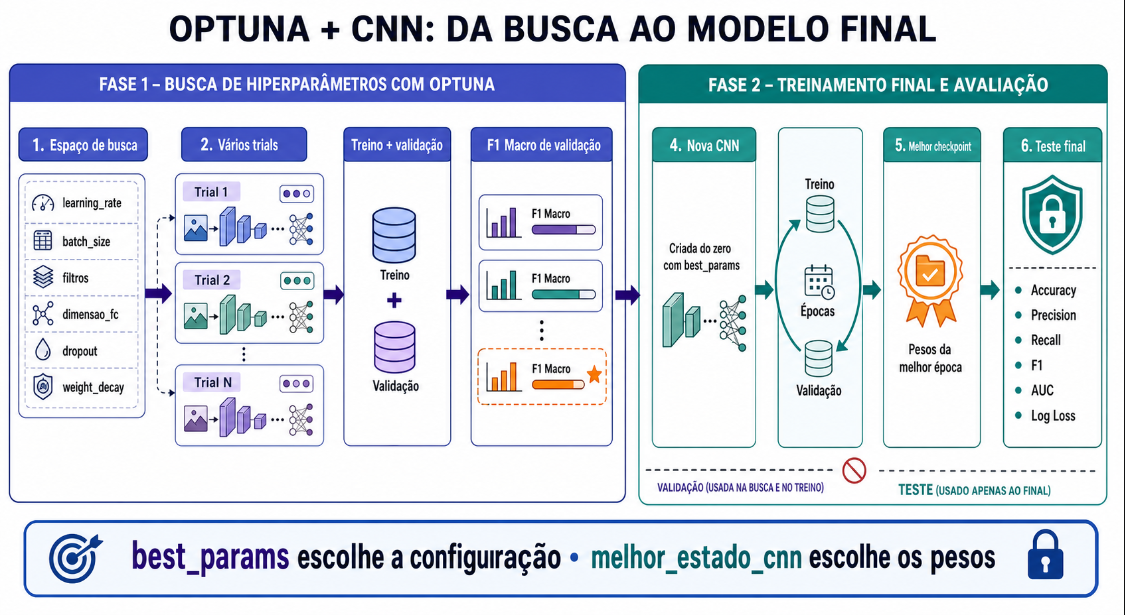


In [53]:
# =============================================================================
# OTIMIZAÇÃO DA CNN COM OPTUNA
# =============================================================================
# Objetivo:
#
# Testar diferentes combinações de hiperparâmetros da CNN e encontrar aquela
# que produz o maior F1 Macro no conjunto de validação.
#
# O conjunto de teste não participa da busca. Ele será utilizado somente depois
# que a melhor configuração tiver sido escolhida.
#
# Fluxo geral:
#
# Optuna sugere hiperparâmetros
#         ↓
# Cria DataLoaders de treino e validação
#         ↓
# Cria uma nova CNN
#         ↓
# Treina e valida por algumas épocas
#         ↓
# Retorna o melhor F1 Macro de validação
#         ↓
# Optuna utiliza o resultado para sugerir a próxima configuração
# =============================================================================


# O Optuna exige uma função objetivo.
#
# A biblioteca chamará esta função uma vez para cada tentativa, também chamada
# de trial.
#
# Exemplo:
#
# Trial 0 → uma combinação de hiperparâmetros
# Trial 1 → outra combinação
# Trial 2 → outra combinação
#
# Cada trial cria e treina uma CNN completamente nova.
def objetivo_cnn(trial):
    """
    Treina uma configuração da CNN e devolve o maior F1 Macro de validação.

    O Optuna utiliza esse valor para comparar as diferentes configurações.
    """

    # =========================================================================
    # 1. HIPERPARÂMETROS SUGERIDOS NESTA TENTATIVA
    # =========================================================================

    # O Optuna sugere uma learning rate entre 0.0001 e 0.003.
    #
    # log=True indica que a busca ocorre em escala logarítmica. Isso é adequado
    # porque learning rates costumam variar por ordens de grandeza:
    #
    # 0.0001, 0.0003, 0.001, 0.003...
    #
    # A learning rate controla o tamanho de cada atualização dos pesos.
    learning_rate = trial.suggest_float(
        name="learning_rate",
        low=1e-4,
        high=3e-3,
        log=True,
    )

    # O Optuna escolhe uma das duas opções de batch size.
    #
    # batch_size=32:
    #   - menos memória;
    #   - mais atualizações por época;
    #   - gradientes potencialmente mais variáveis.
    #
    # batch_size=64:
    #   - mais memória;
    #   - menos atualizações por época;
    #   - gradientes calculados com mais imagens.
    batch_size = trial.suggest_categorical(
        name="batch_size",
        choices=[32, 64],
    )

    # Quantidade de filtros da primeira convolução.
    #
    # Os três blocos utilizarão:
    #
    # filtros
    # filtros * 2
    # filtros * 4
    #
    # Exemplos:
    #
    # filtros=24 → canais: 24, 48, 96
    # filtros=32 → canais: 32, 64, 128
    # filtros=48 → canais: 48, 96, 192
    #
    # Mais filtros aumentam a capacidade da rede, mas também aumentam
    # o uso de memória e o custo computacional.
    filtros = trial.suggest_categorical(
        name="filtros",
        choices=[24, 32, 48],
    )

    # Quantidade de neurônios na camada totalmente conectada intermediária.
    #
    # Depois do Flatten, as características serão reduzidas para:
    #
    # 128, 256 ou 384 valores.
    #
    # Uma dimensão maior aumenta a capacidade do classificador, mas também
    # aumenta a quantidade de parâmetros e o risco de overfitting.
    dimensao_fc = trial.suggest_categorical(
        name="dimensao_fc",
        choices=[128, 256, 384],
    )

    # Probabilidade de Dropout utilizada no classificador.
    #
    # O Optuna pode escolher qualquer valor contínuo entre 0.20 e 0.50.
    #
    # Exemplo:
    #
    # dropout=0.20 → desliga aproximadamente 20% das ativações;
    # dropout=0.50 → desliga aproximadamente 50% das ativações.
    #
    # Um valor pequeno pode regularizar pouco.
    # Um valor muito alto pode dificultar o aprendizado.
    dropout = trial.suggest_float(
        name="dropout",
        low=0.20,
        high=0.50,
    )

    # Weight decay é uma regularização aplicada aos pesos pelo otimizador.
    #
    # Valores maiores penalizam mais fortemente pesos muito grandes.
    #
    # A busca também utiliza escala logarítmica:
    #
    # 0.000001 até 0.001
    weight_decay = trial.suggest_float(
        name="weight_decay",
        low=1e-6,
        high=1e-3,
        log=True,
    )

    # Exibe a configuração que será avaliada nesta tentativa.
    print("\n" + "=" * 80)
    print(f"INICIANDO TRIAL {trial.number}")
    print("=" * 80)
    print(f"Learning rate: {learning_rate:.6f}")
    print(f"Batch size: {batch_size}")
    print(f"Filtros iniciais: {filtros}")
    print(f"Dimensão FC: {dimensao_fc}")
    print(f"Dropout: {dropout:.4f}")
    print(f"Weight decay: {weight_decay:.8f}")

    # =========================================================================
    # 2. SEPARAÇÃO DOS DADOS
    # =========================================================================
    # Selecionamos somente treino e validação.
    #
    # O teste é propositalmente ignorado porque ele não pode influenciar a
    # escolha dos hiperparâmetros.

    # Seleciona todas as linhas marcadas como treino.
    #
    # .eq("treino") produz uma máscara booleana:
    #
    # True  → a linha pertence ao treino;
    # False → a linha pertence a outro split.
    #
    # .copy() cria um DataFrame independente.
    cnn_treino_trial_df = df_splits[
        df_splits["split"].eq("treino")
    ].copy()

    # Seleciona todas as linhas de validação.
    cnn_validacao_trial_df = df_splits[
        df_splits["split"].eq("validacao")
    ].copy()

    # MODO_RAPIDO=True utiliza somente uma amostra balanceada.
    #
    # Isso é útil para verificar se o código funciona sem precisar treinar
    # repetidamente sobre as 27 mil imagens.
    if MODO_RAPIDO:

        # Seleciona no máximo 120 imagens de cada classe no treino.
        cnn_treino_trial_df = subconjunto_rapido(
            df=cnn_treino_trial_df,
            n_por_classe=120,
        )

        # Seleciona no máximo 120 imagens de cada classe na validação.
        cnn_validacao_trial_df = subconjunto_rapido(
            df=cnn_validacao_trial_df,
            n_por_classe=120,
        )

    print(
        f"Imagens de treino: {len(cnn_treino_trial_df)} | "
        f"Imagens de validação: {len(cnn_validacao_trial_df)}"
    )

    # =========================================================================
    # 3. CRIAÇÃO DOS DATASETS
    # =========================================================================

    # Dataset de treino.
    #
    # transform_treino possui transformações aleatórias, como rotações,
    # flips e ajustes de cor.
    dataset_treino_trial = EuroSATPaths(
        tabela=cnn_treino_trial_df,
        transformacao=transform_treino,
    )

    # Dataset de validação.
    #
    # transform_avaliacao é determinística: a mesma imagem sempre recebe
    # exatamente o mesmo processamento.
    dataset_validacao_trial = EuroSATPaths(
        tabela=cnn_validacao_trial_df,
        transformacao=transform_avaliacao,
    )

    # =========================================================================
    # 4. CRIAÇÃO DOS DATALOADERS
    # =========================================================================

    # DataLoader de treino.
    loader_treino_trial = DataLoader(

        # Dataset que será percorrido.
        dataset=dataset_treino_trial,

        # Quantidade de imagens processadas em cada batch.
        batch_size=batch_size,

        # Embaralha as imagens a cada época.
        # Isso evita que a rede memorize uma ordem fixa dos exemplos.
        shuffle=True,

        # Quantidade de processos utilizados para carregar imagens.
        # No Windows, o notebook utiliza zero por segurança.
        num_workers=CFG.num_workers,

        # Quando há CUDA, prepara a memória para transferências mais eficientes
        # entre CPU e GPU.
        pin_memory=torch.cuda.is_available(),

        # Define uma semente para cada worker.
        worker_init_fn=worker_seed,

        # Controla de forma reproduzível a ordem do embaralhamento.
        generator=criar_gerador(SEED),
    )

    # DataLoader de validação.
    loader_validacao_trial = DataLoader(
        dataset=dataset_validacao_trial,
        batch_size=batch_size,

        # A validação não precisa ser embaralhada porque os pesos não serão
        # atualizados e queremos uma ordem previsível.
        shuffle=False,

        num_workers=CFG.num_workers,
        pin_memory=torch.cuda.is_available(),
        worker_init_fn=worker_seed,
    )

    print(
        f"Batches de treino: {len(loader_treino_trial)} | "
        f"Batches de validação: {len(loader_validacao_trial)}"
    )

    # =========================================================================
    # 5. CRIAÇÃO DO MODELO
    # =========================================================================

    # Cria uma nova CNN usando os hiperparâmetros deste trial.
    #
    # Cada trial começa com uma nova instância e, portanto, com novos pesos
    # iniciais.
    modelo_trial = CNNDoZero(
        num_classes=len(CLASSES),
        filtros=filtros,
        dimensao_fc=dimensao_fc,
        dropout=dropout,
    )

    # Move o modelo para GPU CUDA, quando disponível, ou CPU.
    modelo_trial = modelo_trial.to(DEVICE)

    # =========================================================================
    # 6. FUNÇÃO DE PERDA
    # =========================================================================

    # CrossEntropyLoss é utilizada para classificação multiclasse.
    #
    # Ela recebe:
    #
    # logits: shape (N, 10);
    # labels: shape (N,).
    #
    # Internamente, ela combina LogSoftmax e Log Loss.
    loss_fn_trial = nn.CrossEntropyLoss()

    # =========================================================================
    # 7. OTIMIZADOR
    # =========================================================================

    # Adam atualizará todos os parâmetros treináveis da CNN.
    optimizer_trial = torch.optim.Adam(

        # Parâmetros que serão atualizados pelo backpropagation.
        params=modelo_trial.parameters(),

        # Tamanho inicial de cada atualização.
        lr=learning_rate,

        # Regularização dos pesos.
        weight_decay=weight_decay,
    )

    # =========================================================================
    # 8. SCHEDULER
    # =========================================================================

    # ReduceLROnPlateau reduz a learning rate quando a loss de validação
    # deixa de melhorar.
    scheduler_trial = torch.optim.lr_scheduler.ReduceLROnPlateau(

        # Otimizador cuja learning rate será modificada.
        optimizer=optimizer_trial,

        # mode="min" porque queremos minimizar a loss de validação.
        mode="min",

        # Aguarda duas épocas sem melhora antes de reduzir a learning rate.
        patience=2,

        # Multiplica a learning rate por 0.5.
        #
        # Exemplo:
        # 0.001 → 0.0005
        factor=0.5,
    )

    # =========================================================================
    # 9. VARIÁVEIS DE CONTROLE
    # =========================================================================

    # Começamos com -infinito para garantir que o F1 da primeira época seja
    # considerado uma melhora.
    melhor_f1_trial = -np.inf

    # Conta quantas épocas consecutivas ocorreram sem melhora no F1.
    epocas_sem_melhora = 0

    # O modo rápido utiliza menos épocas.
    #
    # MODO_RAPIDO=True  → no máximo 8 épocas;
    # MODO_RAPIDO=False → no máximo 20 épocas.
    max_epocas_trial = 8 if MODO_RAPIDO else 20

    # =========================================================================
    # 10. LOOP DE ÉPOCAS
    # =========================================================================
    #
    # Em cada época:
    #
    # 1. percorremos todo o treino;
    # 2. atualizamos os pesos;
    # 3. percorremos toda a validação;
    # 4. calculamos o F1 Macro;
    # 5. decidimos se houve melhora.

    for epoca in range(1, max_epocas_trial + 1):

        # =====================================================================
        # 10.1 TREINAMENTO
        # =====================================================================

        # Ativa o comportamento de treinamento.
        #
        # Isso afeta principalmente:
        #
        # - Dropout: passa a desligar ativações;
        # - BatchNorm: utiliza e atualiza estatísticas do batch.
        modelo_trial.train()

        # Acumulará a loss de todos os batches de treino.
        soma_loss_treino = 0.0

        # Percorre os batches do treino.
        for imagens, labels in loader_treino_trial:

            # Move o batch de imagens para o mesmo dispositivo do modelo.
            #
            # non_blocking=True pode permitir transferências assíncronas quando
            # pin_memory está habilitado.
            imagens = imagens.to(
                DEVICE,
                non_blocking=True,
            )

            # Move os rótulos para o mesmo dispositivo.
            labels = labels.to(
                DEVICE,
                non_blocking=True,
            )

            # Remove os gradientes calculados no batch anterior.
            #
            # set_to_none=True pode economizar memória em comparação com
            # preencher todos os gradientes com zero.
            optimizer_trial.zero_grad(
                set_to_none=True
            )

            # Forward:
            #
            # envia as imagens para a CNN e produz dez logits por imagem.
            #
            # Shape esperado:
            #
            # imagens: (N, 3, 224, 224)
            # logits:  (N, 10)
            logits = modelo_trial(imagens)

            # Compara os logits com as classes verdadeiras.
            #
            # O resultado é um único valor escalar: a loss média do batch.
            loss = loss_fn_trial(
                logits,
                labels,
            )

            # Backward:
            #
            # calcula os gradientes da loss em relação a todos os parâmetros
            # treináveis da CNN.
            loss.backward()

            # Limita a norma dos gradientes a 1.0.
            #
            # Isso ajuda a evitar atualizações extremamente grandes e
            # instabilidade durante o treinamento.
            nn.utils.clip_grad_norm_(
                parameters=modelo_trial.parameters(),
                max_norm=1.0,
            )

            # Atualiza os pesos usando os gradientes calculados.
            optimizer_trial.step()

            # loss.item() extrai somente o valor numérico da loss.
            #
            # Isso evita armazenar o grafo computacional completo.
            soma_loss_treino += loss.item()

        # Calcula a média das losses dos batches de treino.
        loss_treino_media = (
            soma_loss_treino
            / len(loader_treino_trial)
        )

        # =====================================================================
        # 10.2 VALIDAÇÃO
        # =====================================================================

        # Ativa o comportamento de avaliação.
        #
        # Dropout é desativado e BatchNorm utiliza as estatísticas acumuladas.
        modelo_trial.eval()

        # Acumulará a loss de todos os batches de validação.
        soma_loss_validacao = 0.0

        # Guardará os rótulos verdadeiros de todos os batches.
        labels_validacao = []

        # Guardará as classes previstas de todos os batches.
        predicoes_validacao = []

        # Desativa o cálculo de gradientes.
        #
        # Na validação não atualizamos os pesos. Isso reduz memória e torna
        # a inferência mais rápida.
        with torch.no_grad():

            # Percorre todos os batches da validação.
            for imagens, labels in loader_validacao_trial:

                # Move somente as imagens para GPU ou CPU.
                imagens = imagens.to(
                    DEVICE,
                    non_blocking=True,
                )

                # Mantemos a variável original labels na CPU para depois usar
                # labels.numpy().
                #
                # Criamos uma segunda variável na GPU para calcular a loss.
                labels_device = labels.to(
                    DEVICE,
                    non_blocking=True,
                )

                # Forward de validação.
                logits = modelo_trial(imagens)

                # Calcula a loss do batch de validação.
                loss = loss_fn_trial(
                    logits,
                    labels_device,
                )

                # argmax(dim=1) encontra o índice do maior logit de cada imagem.
                #
                # Exemplo:
                #
                # logits de uma imagem: [0.2, 1.4, -0.5, ...]
                # maior posição: 1
                # classe prevista: 1
                predicoes = logits.argmax(
                    dim=1
                )

                # Acumula o valor da loss.
                soma_loss_validacao += loss.item()

                # Adiciona os rótulos verdadeiros à lista.
                #
                # labels continua na CPU, por isso pode ser convertido
                # diretamente para NumPy.
                labels_validacao.append(
                    labels.numpy()
                )

                # Move as previsões da GPU para a CPU e converte para NumPy.
                predicoes_validacao.append(
                    predicoes.cpu().numpy()
                )

        # Calcula a loss média da validação.
        loss_validacao_media = (
            soma_loss_validacao
            / len(loader_validacao_trial)
        )

        # Junta os arrays dos diferentes batches em um único vetor.
        #
        # Antes:
        # [
        #   labels do batch 1,
        #   labels do batch 2,
        #   labels do batch 3,
        # ]
        #
        # Depois:
        # [todos os labels da validação]
        y_validacao = np.concatenate(
            labels_validacao
        )

        # Junta todas as previsões em um único vetor.
        pred_validacao = np.concatenate(
            predicoes_validacao
        )

        # Calcula o F1 Macro.
        #
        # average="macro":
        #   calcula o F1 de cada classe separadamente e depois tira a média.
        #
        # zero_division=0:
        #   se nenhuma imagem for prevista para uma classe, o F1 dessa classe
        #   recebe zero em vez de gerar um erro.
        f1_validacao = f1_score(
            y_true=y_validacao,
            y_pred=pred_validacao,
            average="macro",
            zero_division=0,
        )

        # Informa a loss de validação ao scheduler.
        #
        # Se ela ficar sem melhorar por duas épocas, a learning rate será
        # multiplicada por 0.5.
        scheduler_trial.step(
            loss_validacao_media
        )

        # Consulta a learning rate atual para acompanhar possíveis reduções.
        learning_rate_atual = (
            optimizer_trial.param_groups[0]["lr"]
        )

        # Exibe o resultado desta época.
        print(
            f"Trial {trial.number:02d} | "
            f"Época {epoca:02d}/{max_epocas_trial:02d} | "
            f"Loss treino {loss_treino_media:.4f} | "
            f"Loss validação {loss_validacao_media:.4f} | "
            f"F1 validação {f1_validacao:.4f} | "
            f"LR {learning_rate_atual:.2e}"
        )

        # =====================================================================
        # 10.3 EARLY STOPPING
        # =====================================================================

        # Consideramos uma melhora apenas quando o novo F1 supera o melhor
        # resultado anterior por pelo menos 0.0001.
        if f1_validacao > melhor_f1_trial + 1e-4:

            # Atualiza o melhor resultado do trial.
            melhor_f1_trial = f1_validacao

            # Reinicia o contador porque houve melhora.
            epocas_sem_melhora = 0

        else:

            # Não houve melhora; incrementamos o contador.
            epocas_sem_melhora += 1

            # Se passarmos três épocas consecutivas sem melhora, encerramos
            # antecipadamente esta tentativa.
            if epocas_sem_melhora >= 3:
                print(
                    "Early stopping: três épocas "
                    "consecutivas sem melhora."
                )
                break

    # =========================================================================
    # 11. FINALIZAÇÃO DESTA TENTATIVA
    # =========================================================================

    print(
        f"Trial {trial.number:02d} concluído | "
        f"Melhor F1 Macro: {melhor_f1_trial:.4f}"
    )

    # Remove a referência principal ao modelo.
    #
    # Quando a função terminar, as outras variáveis locais também serão
    # liberadas pelo Python.
    del modelo_trial

    # Libera o cache não utilizado da GPU.
    limpar_memoria()

    # O Optuna espera um número como resposta.
    #
    # Como o estudo usa direction="maximize", valores maiores serão considerados
    # melhores.
    return float(melhor_f1_trial)


# =============================================================================
# 12. CRIAÇÃO E EXECUÇÃO DO ESTUDO OPTUNA
# =============================================================================

# A busca só será executada após autorização explícita.
if EXECUTAR_TREINOS:

    # Verifica se o pacote Optuna está instalado.
    exigir_pacote("optuna")

    # Importa o pacote somente quando a busca realmente será executada.
    import optuna

    # Cria um estudo de otimização.
    estudo_cnn = optuna.create_study(

        # Queremos maximizar o F1 Macro.
        direction="maximize",

        # TPE utiliza os resultados anteriores para escolher configurações
        # mais promissoras nas tentativas seguintes.
        #
        # seed=SEED torna as sugestões mais reproduzíveis.
        sampler=optuna.samplers.TPESampler(
            seed=SEED
        ),
    )

    # Executa a busca.
    estudo_cnn.optimize(

        # Função que será chamada em cada tentativa.
        func=objetivo_cnn,

        # No modo rápido, executa cinco tentativas.
        # Na execução completa, utiliza CFG.n_trials.
        n_trials=(
            5
            if MODO_RAPIDO
            else CFG.n_trials
        ),
    )

    # Exibe o melhor F1 Macro encontrado.
    print(
        "Melhor F1 Macro de validação:",
        estudo_cnn.best_value,
    )

    # Exibe os hiperparâmetros associados ao melhor resultado.
    print("Melhores hiperparâmetros:")

    display(
        pd.Series(
            estudo_cnn.best_params
        )
    )

else:

    # Esta mensagem aparece durante a leitura didática do notebook.
    print(
        "Busca Optuna desativada. "
        "Defina EXECUTAR_TREINOS=True quando quiser executá-la."
    )

c:\Users\leova\anaconda3\envs\engenharia_ia_venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
[I 2026-07-17 11:54:15,977] A new study created in memory with name: no-name-4c4ef770-8962-48bd-95ce-d0785d9dc7f5



INICIANDO TRIAL 0
Learning rate: 0.000357
Batch size: 32
Filtros iniciais: 24
Dimensão FC: 256
Dropout: 0.4124
Weight decay: 0.00000115
Imagens de treino: 1200 | Imagens de validação: 1200
Batches de treino: 38 | Batches de validação: 38
Trial 00 | Época 01/08 | Loss treino 2.0472 | Loss validação 1.7629 | F1 validação 0.3689 | LR 3.57e-04
Trial 00 | Época 02/08 | Loss treino 1.8207 | Loss validação 1.5908 | F1 validação 0.4348 | LR 3.57e-04
Trial 00 | Época 03/08 | Loss treino 1.7432 | Loss validação 1.4677 | F1 validação 0.4466 | LR 3.57e-04
Trial 00 | Época 04/08 | Loss treino 1.6761 | Loss validação 1.4337 | F1 validação 0.4634 | LR 3.57e-04
Trial 00 | Época 05/08 | Loss treino 1.6185 | Loss validação 1.3454 | F1 validação 0.5123 | LR 3.57e-04
Trial 00 | Época 06/08 | Loss treino 1.5513 | Loss validação 1.3389 | F1 validação 0.5376 | LR 3.57e-04
Trial 00 | Época 07/08 | Loss treino 1.5894 | Loss validação 1.2985 | F1 validação 0.5288 | LR 3.57e-04


[I 2026-07-17 11:55:29,155] Trial 0 finished with value: 0.5408839545311451 and parameters: {'learning_rate': 0.0003574712922600243, 'batch_size': 32, 'filtros': 24, 'dimensao_fc': 256, 'dropout': 0.4124217733388137, 'weight_decay': 1.1527987128232402e-06}. Best is trial 0 with value: 0.5408839545311451.


Trial 00 | Época 08/08 | Loss treino 1.5661 | Loss validação 1.2629 | F1 validação 0.5409 | LR 3.57e-04
Trial 00 concluído | Melhor F1 Macro: 0.5409

INICIANDO TRIAL 1
Learning rate: 0.002708
Batch size: 32
Filtros iniciais: 48
Dimensão FC: 128
Dropout: 0.3836
Weight decay: 0.00000262
Imagens de treino: 1200 | Imagens de validação: 1200
Batches de treino: 38 | Batches de validação: 38
Trial 01 | Época 01/08 | Loss treino 2.0935 | Loss validação 1.6336 | F1 validação 0.3085 | LR 2.71e-03
Trial 01 | Época 02/08 | Loss treino 1.7822 | Loss validação 1.5025 | F1 validação 0.4898 | LR 2.71e-03
Trial 01 | Época 03/08 | Loss treino 1.6883 | Loss validação 1.3843 | F1 validação 0.4829 | LR 2.71e-03
Trial 01 | Época 04/08 | Loss treino 1.6572 | Loss validação 1.3884 | F1 validação 0.4600 | LR 2.71e-03


[I 2026-07-17 11:56:20,210] Trial 1 finished with value: 0.4898291476691529 and parameters: {'learning_rate': 0.002708160864249967, 'batch_size': 32, 'filtros': 48, 'dimensao_fc': 128, 'dropout': 0.38355586841671385, 'weight_decay': 2.62108787826544e-06}. Best is trial 0 with value: 0.5408839545311451.


...

[I 2026-07-17 11:58:28,337] Trial 3 finished with value: 0.5056223997566432 and parameters: {'learning_rate': 0.00252126790477792, 'batch_size': 32, 'filtros': 48, 'dimensao_fc': 384, 'dropout': 0.21031655633456553, 'weight_decay': 0.0005345166110646819}. Best is trial 2 with value: 0.5687022138554945.


Trial 03 | Época 06/08 | Loss treino 1.4582 | Loss validação 1.2404 | F1 validação 0.5016 | LR 2.52e-03
Early stopping: três épocas consecutivas sem melhora.
Trial 03 concluído | Melhor F1 Macro: 0.5056

INICIANDO TRIAL 4
Learning rate: 0.000241
Batch size: 32
Filtros iniciais: 32
Dimensão FC: 128
Dropout: 0.4684
Weight decay: 0.00006219
Imagens de treino: 1200 | Imagens de validação: 1200
Batches de treino: 38 | Batches de validação: 38
Trial 04 | Época 01/08 | Loss treino 2.1680 | Loss validação 1.9669 | F1 validação 0.3026 | LR 2.41e-04
Trial 04 | Época 02/08 | Loss treino 1.8967 | Loss validação 1.6590 | F1 validação 0.3927 | LR 2.41e-04
Trial 04 | Época 03/08 | Loss treino 1.8008 | Loss validação 1.5293 | F1 validação 0.4446 | LR 2.41e-04
Trial 04 | Época 04/08 | Loss treino 1.7584 | Loss validação 1.4425 | F1 validação 0.4855 | LR 2.41e-04
Trial 04 | Época 05/08 | Loss treino 1.6827 | Loss validação 1.4010 | F1 validação 0.4948 | LR 2.41e-04
Trial 04 | Época 06/08 | Loss treino 1

[I 2026-07-17 11:59:41,208] Trial 4 finished with value: 0.5366768895596945 and parameters: {'learning_rate': 0.00024112898115291975, 'batch_size': 32, 'filtros': 32, 'dimensao_fc': 128, 'dropout': 0.46844820512829466, 'weight_decay': 6.218704727769077e-05}. Best is trial 2 with value: 0.5687022138554945.


Trial 04 | Época 08/08 | Loss treino 1.5456 | Loss validação 1.2888 | F1 validação 0.5367 | LR 2.41e-04
Trial 04 concluído | Melhor F1 Macro: 0.5367
Melhor F1 Macro de validação: 0.5687022138554945
Melhores hiperparâmetros:


learning_rate      0.000270
batch_size        64.000000
filtros           24.000000
dimensao_fc      384.000000
dropout            0.251157
weight_decay       0.000002
dtype: float64

Configuração final da CNN:


learning_rate      0.000270
batch_size        64.000000
filtros           24.000000
dimensao_fc      384.000000
dropout            0.251157
weight_decay       0.000002
dtype: float64

Imagens | treino: 18899 | validação: 4051 | teste: 4050
Época 01 | Loss treino 1.4550 | Loss validação 0.9801 | F1 validação 0.6355
Época 02 | Loss treino 1.1395 | Loss validação 0.8694 | F1 validação 0.6649
Época 03 | Loss treino 1.0441 | Loss validação 0.8091 | F1 validação 0.6859
Época 04 | Loss treino 0.9738 | Loss validação 0.7651 | F1 validação 0.7267
Época 05 | Loss treino 0.9174 | Loss validação 0.6983 | F1 validação 0.7506
Época 06 | Loss treino 0.8653 | Loss validação 0.6849 | F1 validação 0.7417
Época 07 | Loss treino 0.8439 | Loss validação 0.6190 | F1 validação 0.7711
Época 08 | Loss treino 0.8082 | Loss validação 0.6186 | F1 validação 0.7740
Época 09 | Loss treino 0.7930 | Loss validação 0.5917 | F1 validação 0.7835
Época 10 | Loss treino 0.7759 | Loss validação 0.5483 | F1 validação 0.7961
Época 11 | Loss treino 0.7541 | Loss validação 0.5531 | F1 validação 0.7986
Época 12 | Loss treino 0.7380 | Loss validação 0.5852 | F1 validação 0.7828
Época 13 | Loss treino 0.7289 | 

,métrica,valor
0,Accuracy,0.842963
1,Precision Macro,0.843396
2,Recall Macro,0.839333
3,F1 Macro,0.837882
4,AUC OVR Macro,0.987019
5,Log Loss,0.454358


,classe,f1
3,Highway,0.725948
6,PermanentCrop,0.750314
2,HerbaceousVegetation,0.758140
8,River,0.796089
5,Pasture,0.811502
0,AnnualCrop,0.852029
7,Residential,0.864865
4,Industrial,0.909567
1,Forest,0.944690
9,SeaLake,0.965675


Treino: 3276.2s | Inferência: 7.2s | Parâmetros treináveis: 646,882


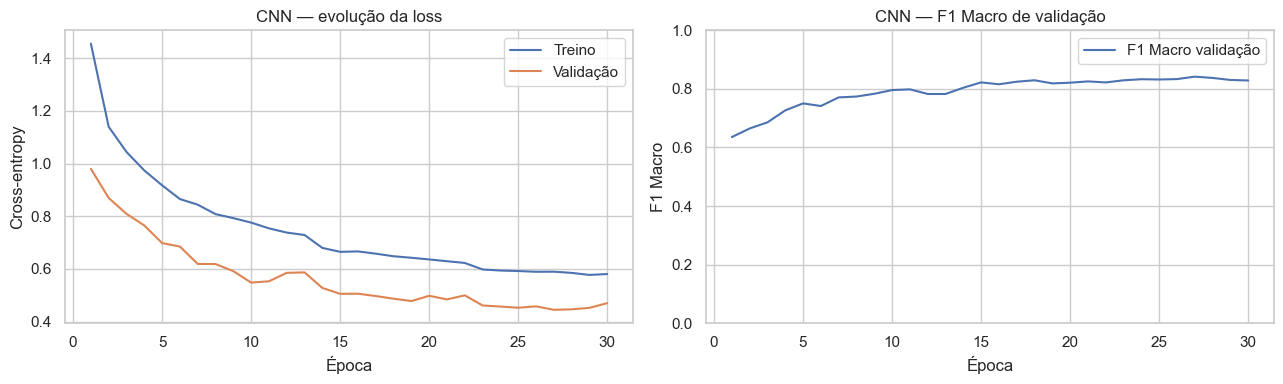

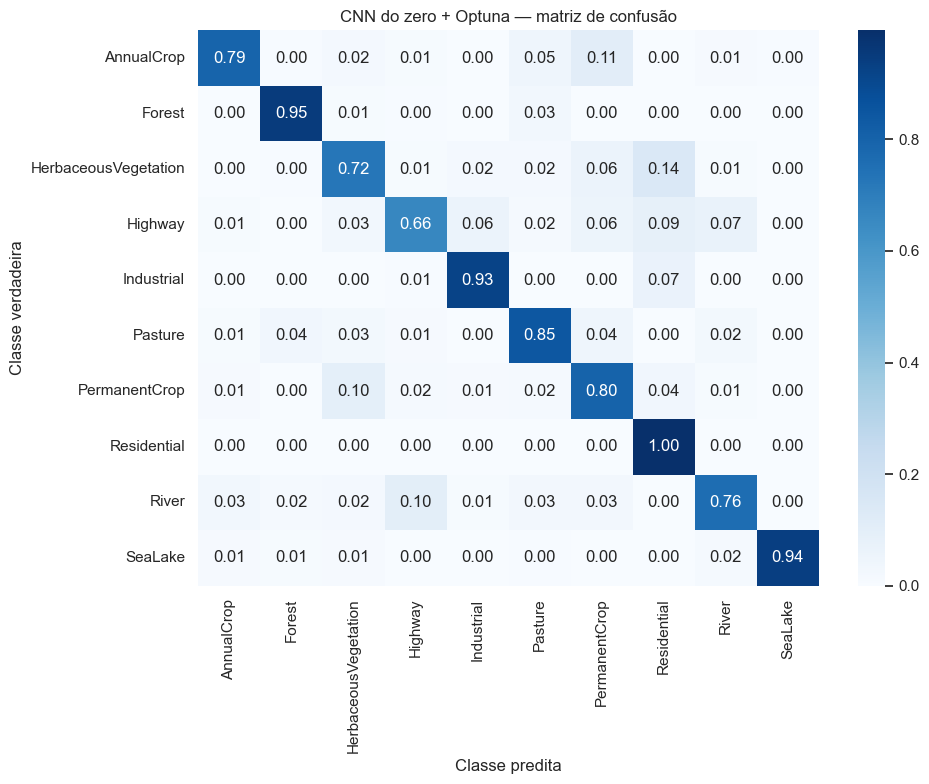

In [56]:
# -----------------------------------------------------------------------------
# Objetivo desta célula:
# Treinar a configuração final da CNN, escolhida pelo Optuna, acompanhar seu
# desempenho na validação e avaliar o melhor modelo no conjunto de teste.
#
# Fluxo completo:
# 1. Recuperar os melhores hiperparâmetros encontrados pelo Optuna.
# 2. Separar treino, validação e teste.
# 3. Criar os Datasets e DataLoaders.
# 4. Construir a CNN final.
# 5. Treinar a CNN.
# 6. Validar a CNN ao final de cada época.
# 7. Guardar os pesos da melhor época.
# 8. Avaliar uma única vez no conjunto de teste.
# 9. Calcular métricas, gráficos e matriz de confusão.
# 10. Registrar os resultados para comparação com os outros modelos.
# -----------------------------------------------------------------------------

# Responsável por eliminar a necessidade de amostragem de 1200 imagens e utilizar tudo para treino, validação e teste. 
# A amostragem é Útil para testes rápidos e para a otimização do Optuna, que treina diversos modelos. 
MODO_RAPIDO_TREINO_FINAL = False 

# Este bloco só será executado quando decidirmos iniciar os treinamentos.
# Enquanto EXECUTAR_TREINOS=False, evitamos iniciar um processo demorado.
if EXECUTAR_TREINOS:

    # Importamos a Log Loss aqui porque ela será usada na avaliação final.
    from sklearn.metrics import log_loss

    # =========================================================================
    # 1. RECUPERAR A MELHOR CONFIGURAÇÃO ENCONTRADA PELO OPTUNA
    # =========================================================================

    # estudo_cnn é o objeto criado pelo Optuna durante a busca de
    # hiperparâmetros.
    #
    # best_params retorna um dicionário semelhante a:
    # {
    #     "learning_rate": 0.0005,
    #     "batch_size": 32,
    #     "filtros": 32,
    #     "dimensao_fc": 256,
    #     "dropout": 0.35,
    #     "weight_decay": 0.0001
    # }
    melhores_cnn = estudo_cnn.best_params

    print("Configuração final da CNN:")

    # Transformamos o dicionário em uma Series somente para exibi-lo
    # verticalmente e facilitar a leitura no notebook.
    display(pd.Series(melhores_cnn))

    # =========================================================================
    # 2. SEPARAR TREINO, VALIDAÇÃO E TESTE
    # =========================================================================

    # Selecionamos apenas as linhas marcadas como "treino".
    # O resultado contém caminhos das imagens, classes e demais informações.
    cnn_treino_df = df_splits[
        df_splits["split"].eq("treino")
    ].copy()

    # Selecionamos as imagens reservadas para validação.
    #
    # A validação será consultada depois de cada época para:
    # - acompanhar a generalização;
    # - ajustar a taxa de aprendizado;
    # - aplicar early stopping;
    # - escolher a melhor época.
    cnn_validacao_df = df_splits[
        df_splits["split"].eq("validacao")
    ].copy()

    # Selecionamos as imagens reservadas para o teste final.
    #
    # O teste não participa do treinamento nem da escolha da melhor época.
    cnn_teste_df = df_splits[
        df_splits["split"].eq("teste")
    ].copy()

    # No modo rápido treino final, usamos somente uma pequena amostra de cada conjunto.
    # Isso permite verificar se todo o pipeline funciona sem esperar pelo
    # Para o treinamento completo, MODO_RAPIDO_TREINO_FINAL deve ser False.
    if MODO_RAPIDO_TREINO_FINAL:
        cnn_treino_df = subconjunto_rapido(
            cnn_treino_df,
            n_por_classe=120,
        )

        cnn_validacao_df = subconjunto_rapido(
            cnn_validacao_df,
            n_por_classe=120,
        )

        cnn_teste_df = subconjunto_rapido(
            cnn_teste_df,
            n_por_classe=120,
        )

    # Conferimos quantas imagens serão usadas em cada etapa.
    print(
        "Imagens | treino:",
        len(cnn_treino_df),
        "| validação:",
        len(cnn_validacao_df),
        "| teste:",
        len(cnn_teste_df),
    )

    # =========================================================================
    # 3. CRIAR OS DATASETS
    # =========================================================================

    # O Dataset sabe:
    # - onde está cada imagem;
    # - qual é a classe correta;
    # - qual transformação deve ser aplicada;
    # - como devolver a imagem como tensor.
    #
    # No treinamento usamos transform_treino, que inclui data augmentation.
    # Assim, uma mesma imagem pode aparecer com pequenas variações.
    dataset_cnn_treino = EuroSATPaths(
        cnn_treino_df,
        transform_treino,
    )

    # Na validação não usamos data augmentation aleatório.
    # Queremos medir o modelo sempre sobre uma versão estável das imagens.
    dataset_cnn_validacao = EuroSATPaths(
        cnn_validacao_df,
        transform_avaliacao,
    )

    # O teste também utiliza transformações determinísticas.
    dataset_cnn_teste = EuroSATPaths(
        cnn_teste_df,
        transform_avaliacao,
    )

    # =========================================================================
    # 4. CRIAR OS DATALOADERS
    # =========================================================================

    # Recuperamos o batch size escolhido pelo Optuna.
    #
    # Se batch_size=32, a CNN receberá normalmente um tensor com formato:
    #
    #     (32, 3, 224, 224)
    #
    # em que:
    # 32  = quantidade de imagens;
    # 3   = canais RGB;
    # 224 = altura;
    # 224 = largura.
    batch_size_cnn = melhores_cnn["batch_size"]

    # DataLoader do treinamento.
    loader_cnn_treino = DataLoader(
        dataset_cnn_treino,

        # Quantidade de imagens processadas em cada batch.
        batch_size=batch_size_cnn,

        # Embaralhamos o treinamento a cada época para evitar que o modelo
        # aprenda relações artificiais com a ordem das imagens.
        shuffle=True,

        # Quantidade de processos auxiliares usados para carregar os dados.
        num_workers=CFG.num_workers,

        # Quando existe GPU, mantém os dados em uma região de memória que
        # facilita sua transferência da RAM para a GPU.
        pin_memory=torch.cuda.is_available(),

        # Define uma semente para cada worker do DataLoader.
        worker_init_fn=worker_seed,

        # Controla de forma reproduzível o embaralhamento dos dados.
        generator=criar_gerador(SEED),
    )

    # DataLoader da validação.
    loader_cnn_validacao = DataLoader(
        dataset_cnn_validacao,
        batch_size=batch_size_cnn,

        # Não precisamos embaralhar porque nenhum aprendizado será feito.
        shuffle=False,

        num_workers=CFG.num_workers,
        pin_memory=torch.cuda.is_available(),
        worker_init_fn=worker_seed,
    )

    # DataLoader do teste final.
    loader_cnn_teste = DataLoader(
        dataset_cnn_teste,
        batch_size=batch_size_cnn,
        shuffle=False,
        num_workers=CFG.num_workers,
        pin_memory=torch.cuda.is_available(),
        worker_init_fn=worker_seed,
    )

    # =========================================================================
    # 5. CRIAR O MODELO FINAL
    # =========================================================================

    # Instanciamos uma nova CNN do zero.
    #
    # É importante criar um modelo novo porque os modelos usados pelo Optuna
    # serviram apenas para comparar configurações. Agora treinaremos a melhor
    # configuração de forma definitiva.
    cnn_final = CNNDoZero(
        # O EuroSAT possui dez classes.
        num_classes=len(CLASSES),

        # Quantidade inicial de filtros convolucionais escolhida pelo Optuna.
        filtros=melhores_cnn["filtros"],

        # Quantidade de neurônios da camada totalmente conectada.
        dimensao_fc=melhores_cnn["dimensao_fc"],

        # Percentual de ativações desligadas durante o treinamento.
        dropout=melhores_cnn["dropout"],
    )

    # Move todos os parâmetros do modelo para DEVICE.
    #
    # DEVICE será normalmente:
    # - "cuda", quando uma GPU compatível estiver disponível;
    # - "cpu", caso contrário.
    cnn_final = cnn_final.to(DEVICE)

    # =========================================================================
    # 6. DEFINIR LOSS, OTIMIZADOR E SCHEDULER
    # =========================================================================

    # CrossEntropyLoss é adequada para classificação multiclasse.
    #
    # Ela recebe:
    # - logits com formato (N, 10);
    # - labels inteiros com formato (N,).
    #
    # Não aplicamos softmax antes dessa loss porque a CrossEntropyLoss já
    # realiza internamente a operação equivalente ao LogSoftmax.
    loss_fn_cnn = nn.CrossEntropyLoss()

    # Adam atualizará os pesos da rede usando os gradientes calculados
    # durante o backpropagation.
    optimizer_cnn = torch.optim.Adam(
        # Informa ao otimizador quais parâmetros deverão ser atualizados.
        cnn_final.parameters(),

        # Tamanho inicial do passo dado na atualização dos pesos.
        lr=melhores_cnn["learning_rate"],

        # Penalização que desencoraja pesos excessivamente grandes.
        # Atua como uma forma de regularização.
        weight_decay=melhores_cnn["weight_decay"],
    )

    # ReduceLROnPlateau reduz a learning rate quando a loss de validação
    # deixa de melhorar.
    scheduler_cnn = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer_cnn,

        # Queremos minimizar a loss de validação.
        mode="min",

        # Espera duas épocas sem melhora antes de reduzir a learning rate.
        patience=2,

        # Nova learning rate = learning rate atual × 0.5.
        factor=0.5,
    )

    # =========================================================================
    # 7. PREPARAR O HISTÓRICO E O EARLY STOPPING
    # =========================================================================

    # Esta lista armazenará as métricas de cada época.
    # Depois ela será transformada em DataFrame para a criação dos gráficos.
    historico_cnn = []

    # Começamos com -infinito para garantir que o F1 da primeira época seja
    # considerado uma melhoria.
    melhor_f1_cnn = -np.inf

    # Aqui guardaremos uma cópia dos pesos da melhor época.
    melhor_estado_cnn = None

    # Contador usado pelo early stopping.
    epocas_sem_melhora = 0

    # No modo rápido limitamos o número de épocas.
    # Fora dele, usamos o valor definido em CFG.epochs.
    max_epocas_cnn = 10 if MODO_RAPIDO_TREINO_FINAL else CFG.epochs

    # Marcamos o horário inicial para calcular o tempo total de treinamento.
    inicio_treino_cnn = time.perf_counter()

    # =========================================================================
    # 8. LOOP PRINCIPAL DE ÉPOCAS
    # =========================================================================

    # Uma época representa uma passagem completa por todos os batches do
    # conjunto de treinamento.
    for epoca in range(1, max_epocas_cnn + 1):

        # ---------------------------------------------------------------------
        # 8.1. ETAPA DE TREINAMENTO
        # ---------------------------------------------------------------------

        # Ativa o comportamento de treinamento de camadas como:
        # - Dropout;
        # - Batch Normalization.
        cnn_final.train()

        # Acumularemos a loss de todos os batches da época.
        soma_loss_treino = 0.0

        # O DataLoader entrega um batch de imagens e seus respectivos rótulos.
        for imagens, labels in loader_cnn_treino:

            # Move o batch de imagens para CPU ou GPU.
            imagens = imagens.to(
                DEVICE,
                non_blocking=True,
            )

            # Move os rótulos corretos para o mesmo dispositivo do modelo.
            labels = labels.to(
                DEVICE,
                non_blocking=True,
            )

            # Remove os gradientes calculados no batch anterior.
            #
            # No PyTorch, os gradientes são acumulados por padrão. Portanto,
            # precisamos zerá-los antes de calcular os gradientes do novo batch.
            optimizer_cnn.zero_grad(set_to_none=True)

            # FORWARD:
            # as imagens atravessam as convoluções, ativações, poolings e
            # camadas totalmente conectadas.
            #
            # Saída esperada:
            #     logits.shape = (quantidade_de_imagens, 10)
            logits = cnn_final(imagens)

            # Compara os logits previstos com as classes verdadeiras.
            # O resultado é um único valor que representa o erro do batch.
            loss = loss_fn_cnn(
                logits,
                labels,
            )

            # BACKPROPAGATION:
            # calcula o gradiente da loss em relação a cada peso treinável.
            loss.backward()

            # Limita a norma dos gradientes a 1.0.
            #
            # Isso ajuda a evitar gradientes explosivos, que poderiam causar
            # atualizações excessivamente grandes e instabilidade.
            nn.utils.clip_grad_norm_(
                cnn_final.parameters(),
                max_norm=1.0,
            )

            # Atualiza os pesos do modelo usando os gradientes calculados.
            optimizer_cnn.step()

            # loss.item() transforma o tensor escalar em um número Python.
            soma_loss_treino += loss.item()

        # Calculamos a loss média dos batches da época.
        loss_treino_cnn = (
            soma_loss_treino / len(loader_cnn_treino)
        )

        # ---------------------------------------------------------------------
        # 8.2. ETAPA DE VALIDAÇÃO
        # ---------------------------------------------------------------------

        # Coloca o modelo em modo de avaliação.
        #
        # Isso desativa o Dropout e altera o comportamento do BatchNorm.
        cnn_final.eval()

        # Acumulará a loss dos batches de validação.
        soma_loss_validacao = 0.0

        # Guardaremos todas as classes verdadeiras.
        labels_validacao = []

        # Guardaremos todas as classes previstas.
        predicoes_validacao = []

        # Na validação não precisamos calcular gradientes porque não haverá
        # atualização dos pesos.
        with torch.no_grad():

            for imagens, labels in loader_cnn_validacao:

                # As imagens precisam estar no mesmo dispositivo do modelo.
                imagens = imagens.to(
                    DEVICE,
                    non_blocking=True,
                )

                # Criamos uma versão dos labels no dispositivo para calcular
                # a loss. Os labels originais continuam na CPU.
                labels_device = labels.to(
                    DEVICE,
                    non_blocking=True,
                )

                # Forward de validação.
                logits = cnn_final(imagens)

                # Calcula a loss sem alterar os pesos.
                loss = loss_fn_cnn(
                    logits,
                    labels_device,
                )

                # Cada linha de logits contém dez valores.
                # argmax(dim=1) encontra o índice do maior logit de cada imagem.
                #
                # Esse índice corresponde à classe prevista.
                predicoes = logits.argmax(dim=1)

                soma_loss_validacao += loss.item()

                # Os labels originais já estão na CPU, portanto podem ser
                # convertidos diretamente para NumPy.
                labels_validacao.append(
                    labels.numpy()
                )

                # As previsões estão na GPU. Por isso:
                # 1. usamos .cpu() para levá-las à CPU;
                # 2. usamos .numpy() para convertê-las em array NumPy.
                predicoes_validacao.append(
                    predicoes.cpu().numpy()
                )

        # Loss média de validação da época.
        loss_validacao_cnn = (
            soma_loss_validacao / len(loader_cnn_validacao)
        )

        # Cada batch gerou um array separado.
        # np.concatenate junta todos esses arrays em um único vetor.
        y_validacao_cnn = np.concatenate(
            labels_validacao
        )

        pred_validacao_cnn = np.concatenate(
            predicoes_validacao
        )

        # Calculamos o F1 separadamente para cada classe e depois tiramos
        # uma média simples entre as dez classes.
        #
        # Assim, todas as classes possuem a mesma importância na métrica.
        f1_validacao_cnn = f1_score(
            y_validacao_cnn,
            pred_validacao_cnn,
            average="macro",
            zero_division=0,
        )

        # O scheduler observa a loss de validação.
        # Caso ela não melhore por duas épocas, reduzirá a learning rate.
        scheduler_cnn.step(loss_validacao_cnn)

        # Registramos as métricas desta época.
        historico_cnn.append({
            "epoca": epoca,
            "loss_treino": loss_treino_cnn,
            "loss_validacao": loss_validacao_cnn,
            "f1_validacao": f1_validacao_cnn,
        })

        # Exibimos o andamento do treinamento.
        print(
            f"Época {epoca:02d} | "
            f"Loss treino {loss_treino_cnn:.4f} | "
            f"Loss validação {loss_validacao_cnn:.4f} | "
            f"F1 validação {f1_validacao_cnn:.4f}"
        )

        # ---------------------------------------------------------------------
        # 8.3. MELHOR CHECKPOINT E EARLY STOPPING
        # ---------------------------------------------------------------------

        # Consideramos uma melhoria quando o novo F1 supera o melhor F1
        # anterior por pelo menos 0.0001.
        if f1_validacao_cnn > melhor_f1_cnn + 1e-4:

            # Atualizamos a melhor métrica conhecida.
            melhor_f1_cnn = f1_validacao_cnn

            # state_dict contém todos os pesos e parâmetros internos do modelo.
            #
            # deepcopy é importante para criar uma cópia independente.
            # Sem a cópia, o objeto poderia continuar sendo alterado nas
            # épocas seguintes.
            melhor_estado_cnn = copy.deepcopy(
                cnn_final.state_dict()
            )

            # Como houve melhoria, zeramos o contador.
            epocas_sem_melhora = 0

        else:
            # Se não houve melhoria, aumentamos o contador.
            epocas_sem_melhora += 1

            # Quando o limite é atingido, interrompemos o treinamento.
            if epocas_sem_melhora >= CFG.patience:
                print("Early stopping acionado.")
                break

    # Calculamos o tempo total gasto no loop de treinamento.
    tempo_treino_cnn = (
        time.perf_counter() - inicio_treino_cnn
    )

    # =========================================================================
    # 9. RESTAURAR E SALVAR A MELHOR ÉPOCA
    # =========================================================================

    # O modelo atualmente contém os pesos da última época executada.
    #
    # Entretanto, a última época não necessariamente foi a melhor. Por isso,
    # restauramos os pesos associados ao melhor F1 de validação.
    cnn_final.load_state_dict(melhor_estado_cnn)

    # Define onde o arquivo com os pesos será salvo.
    caminho_cnn = ARTIFACT_DIR / "cnn_eurosat_best.pt"

    # Salva somente o state_dict.
    # Para utilizar esses pesos depois, será necessário recriar a mesma
    # arquitetura CNNDoZero e carregar o state_dict.
    torch.save(
        cnn_final.state_dict(),
        caminho_cnn,
    )

    # =========================================================================
    # 10. TESTE FINAL
    # =========================================================================

    # O teste deve ser consultado somente depois que:
    # - os hiperparâmetros foram escolhidos;
    # - o treinamento terminou;
    # - a melhor época foi selecionada.
    #
    # Isso evita usar o teste para tomar decisões sobre o modelo.
    cnn_final.eval()

    # Classes verdadeiras do conjunto de teste.
    labels_teste_cnn = []

    # Classes previstas pela CNN.
    predicoes_teste_cnn = []

    # Probabilidades previstas para cada uma das dez classes.
    probabilidades_teste_cnn = []

    # Começamos a medir o tempo de inferência.
    inicio_inferencia_cnn = time.perf_counter()

    # O teste também não exige cálculo de gradientes.
    with torch.no_grad():

        for imagens, labels in loader_cnn_teste:

            # Move somente as imagens para o dispositivo.
            # Os labels não são usados no forward e podem permanecer na CPU.
            imagens = imagens.to(
                DEVICE,
                non_blocking=True,
            )

            # Produz dez logits para cada imagem.
            logits = cnn_final(imagens)

            # Converte os logits em probabilidades.
            #
            # Para cada imagem, as dez probabilidades somam aproximadamente 1.
            probabilidades = logits.softmax(dim=1)

            # A classe com maior probabilidade é a classe prevista.
            predicoes = probabilidades.argmax(dim=1)

            # Guarda os rótulos verdadeiros.
            labels_teste_cnn.append(
                labels.numpy()
            )

            # Move as previsões para a CPU e converte para NumPy.
            predicoes_teste_cnn.append(
                predicoes.cpu().numpy()
            )

            # Também armazenamos as probabilidades porque métricas como
            # AUC e Log Loss precisam delas, e não apenas da classe final.
            probabilidades_teste_cnn.append(
                probabilidades.cpu().numpy()
            )

    # Tempo total de inferência sobre o conjunto de teste.
    tempo_inferencia_cnn = (
        time.perf_counter() - inicio_inferencia_cnn
    )

    # Junta os resultados de todos os batches.
    y_cnn = np.concatenate(
        labels_teste_cnn
    )

    pred_cnn = np.concatenate(
        predicoes_teste_cnn
    )

    # proba_cnn terá formato:
    #
    #     (quantidade_de_imagens_de_teste, 10)
    proba_cnn = np.concatenate(
        probabilidades_teste_cnn
    )

    # =========================================================================
    # 11. CALCULAR AS MÉTRICAS DA CNN
    # =========================================================================

    # Proporção total de previsões corretas.
    accuracy_cnn = accuracy_score(
        y_cnn,
        pred_cnn,
    )

    # Precision por classe:
    #
    # Entre as imagens que o modelo classificou como determinada classe,
    # quantas realmente pertenciam àquela classe?
    #
    # average="macro" calcula a precision para cada classe e depois tira
    # uma média simples.
    precision_cnn = precision_score(
        y_cnn,
        pred_cnn,
        average="macro",
        zero_division=0,
    )

    # Recall por classe:
    #
    # Entre as imagens que realmente pertenciam a determinada classe,
    # quantas foram encontradas pelo modelo?
    recall_cnn = recall_score(
        y_cnn,
        pred_cnn,
        average="macro",
        zero_division=0,
    )

    # F1 é a média harmônica entre precision e recall.
    f1_macro_cnn = f1_score(
        y_cnn,
        pred_cnn,
        average="macro",
        zero_division=0,
    )

    # AUC multiclasse usando a estratégia One-vs-Rest.
    #
    # Para cada classe, o problema é temporariamente tratado como:
    # - classe atual;
    # - todas as demais classes.
    #
    # Depois calculamos a média das dez AUCs.
    auc_cnn = roc_auc_score(
        y_cnn,
        proba_cnn,
        multi_class="ovr",
        average="macro",
    )

    # Log Loss avalia a qualidade das probabilidades.
    #
    # Ela penaliza fortemente previsões erradas feitas com confiança elevada.
    # Diferentemente da accuracy, não observa somente a classe escolhida.
    log_loss_cnn = log_loss(
        y_cnn,
        proba_cnn,
        labels=range(len(CLASSES)),
    )

    # Aqui não usamos average.
    # Portanto, recebemos um F1 separado para cada classe.
    f1_classes_cnn = f1_score(
        y_cnn,
        pred_cnn,
        labels=range(len(CLASSES)),
        average=None,
        zero_division=0,
    )

    # Conta todos os parâmetros do modelo.
    total_parametros_cnn = sum(
        parametro.numel()
        for parametro in cnn_final.parameters()
    )

    # Conta somente os parâmetros que poderiam ser atualizados pelo otimizador.
    parametros_treinaveis_cnn = sum(
        parametro.numel()
        for parametro in cnn_final.parameters()
        if parametro.requires_grad
    )

    # Obtém o tamanho do arquivo salvo e converte bytes para megabytes.
    tamanho_cnn_mb = (
        caminho_cnn.stat().st_size / 1024**2
    )

    # Organiza as métricas gerais em uma tabela.
    metricas_cnn = pd.DataFrame({
        "métrica": [
            "Accuracy",
            "Precision Macro",
            "Recall Macro",
            "F1 Macro",
            "AUC OVR Macro",
            "Log Loss",
        ],
        "valor": [
            accuracy_cnn,
            precision_cnn,
            recall_cnn,
            f1_macro_cnn,
            auc_cnn,
            log_loss_cnn,
        ],
    })

    # Cria uma tabela de F1 por classe.
    #
    # sort_values("f1") coloca as classes com pior desempenho no começo,
    # facilitando a identificação das maiores dificuldades do modelo.
    f1_por_classe_cnn = pd.DataFrame({
        "classe": CLASSES,
        "f1": f1_classes_cnn,
    }).sort_values("f1")

    display(metricas_cnn)
    display(f1_por_classe_cnn)

    # =========================================================================
    # 12. VISUALIZAR AS CURVAS DE APRENDIZADO
    # =========================================================================

    # Converte o histórico das épocas em DataFrame.
    historico_cnn_df = pd.DataFrame(
        historico_cnn
    )

    # Cria uma figura com dois gráficos lado a lado.
    fig, axes = plt.subplots(
        1,
        2,
        figsize=(13, 4),
    )

    # -------------------------------------------------------------------------
    # Gráfico 1: loss de treino e validação
    # -------------------------------------------------------------------------

    axes[0].plot(
        historico_cnn_df["epoca"],
        historico_cnn_df["loss_treino"],
        label="Treino",
    )

    axes[0].plot(
        historico_cnn_df["epoca"],
        historico_cnn_df["loss_validacao"],
        label="Validação",
    )

    axes[0].set_title("CNN — evolução da loss")
    axes[0].set_xlabel("Época")
    axes[0].set_ylabel("Cross-entropy")
    axes[0].legend()

    # -------------------------------------------------------------------------
    # Gráfico 2: F1 Macro de validação
    # -------------------------------------------------------------------------

    axes[1].plot(
        historico_cnn_df["epoca"],
        historico_cnn_df["f1_validacao"],
        label="F1 Macro validação",
    )

    axes[1].set_title(
        "CNN — F1 Macro de validação"
    )

    axes[1].set_xlabel("Época")
    axes[1].set_ylabel("F1 Macro")

    # Como o F1 varia entre 0 e 1, fixamos essa escala no eixo vertical.
    axes[1].set_ylim(0, 1)
    axes[1].legend()

    # Ajusta automaticamente os espaços entre os gráficos.
    plt.tight_layout()

    # =========================================================================
    # 13. MATRIZ DE CONFUSÃO
    # =========================================================================

    # A matriz de confusão compara:
    # - linhas: classes verdadeiras;
    # - colunas: classes previstas.
    #
    # normalize="true" divide cada linha pelo total de imagens daquela classe.
    # Por isso, os valores representam proporções entre 0 e 1.
    matriz_cnn = confusion_matrix(
        y_cnn,
        pred_cnn,
        labels=range(len(CLASSES)),
        normalize="true",
    )

    plt.figure(figsize=(10, 8))

    sns.heatmap(
        matriz_cnn,

        # Escreve o valor dentro de cada célula.
        annot=True,

        # Mostra os valores com duas casas decimais.
        fmt=".2f",

        # Define a paleta de cores.
        cmap="Blues",

        # Nomes das classes previstas no eixo horizontal.
        xticklabels=CLASSES,

        # Nomes das classes verdadeiras no eixo vertical.
        yticklabels=CLASSES,
    )

    plt.title(
        "CNN do zero + Optuna — matriz de confusão"
    )

    plt.xlabel("Classe predita")
    plt.ylabel("Classe verdadeira")
    plt.tight_layout()

    # =========================================================================
    # 14. REGISTRAR O RESULTADO PARA O BENCHMARK FINAL
    # =========================================================================

    # RESULTADOS é um dicionário compartilhado pelos modelos do notebook.
    #
    # Cada modelo registra suas métricas usando a mesma estrutura. Isso permite
    # criar posteriormente uma tabela comparando CNN, ResNet, ViT, LightGBM
    # e os demais modelos.
    RESULTADOS["CNN do zero + Optuna"] = {
        "modelo": "CNN do zero + Optuna",
        "accuracy": accuracy_cnn,
        "precision_macro": precision_cnn,
        "recall_macro": recall_cnn,
        "f1_macro": f1_macro_cnn,
        "auc_ovr_macro": auc_cnn,
        "log_loss": log_loss_cnn,
        "treino_s": tempo_treino_cnn,
        "inferencia_s": tempo_inferencia_cnn,
        "parametros_totais": total_parametros_cnn,
        "parametros_treinaveis": parametros_treinaveis_cnn,
        "tamanho_mb": tamanho_cnn_mb,

        # Este dicionário interno cria uma coluna de F1 para cada classe:
        #
        # f1_AnnualCrop
        # f1_Forest
        # f1_Highway
        # ...
        #
        # O operador ** insere esses pares dentro do dicionário principal.
        **{
            f"f1_{classe}": valor
            for classe, valor in zip(
                CLASSES,
                f1_classes_cnn,
            )
        },
    }

    # Resumo operacional do treinamento.
    print(
        f"Treino: {tempo_treino_cnn:.1f}s | "
        f"Inferência: {tempo_inferencia_cnn:.1f}s | "
        f"Parâmetros treináveis: "
        f"{parametros_treinaveis_cnn:,}"
    )

else:
    # Este aviso aparece quando EXECUTAR_TREINOS=False.
    #
    # Além disso, o estudo Optuna precisa ter sido executado anteriormente,
    # pois estudo_cnn.best_params depende de seus resultados.
    print(
        "Treino final da CNN aguardando "
        "EXECUTAR_TREINOS=True e a conclusão do Optuna."
    )

**Como interpretar:** procure convergência conjunta das perdas e o maior F1 de validação, não o menor erro de treino. O checkpoint definitivo é salvo antes do teste.

**Conclusão da seção:** Optuna escolhe a configuração da CNN somente na validação; o teste estima seu desempenho final.


## 16. Transfer Learning com ResNet50

**Pergunta de aprendizagem:** quanto ganhamos reutilizando filtros aprendidos na ImageNet?

### Ideia central: reutilizar uma representação já aprendida

Treinar do zero começa com filtros aleatórios. Transfer learning começa com filtros aprendidos na ImageNet, que já reconhecem bordas, cores, texturas, formas e composições visuais. Esses padrões gerais podem ser reutilizados no EuroSAT.

A ResNet50 possui um **backbone**, responsável por extrair features, e uma **cabeça**, responsável por transformá-las em classes. No notebook, o backbone é congelado e a cabeça original de 1.000 classes é substituída por uma saída de 10 classes.

```text
Batch EuroSAT
(32, 3, 224, 224)
        ↓
Conv inicial 7×7, stride 2
(32, 64, 112, 112)
        ↓
MaxPool + layer1
(32, 256, 56, 56)
        ↓
layer2
(32, 512, 28, 28)
        ↓
layer3
(32, 1024, 14, 14)
        ↓
layer4
(32, 2048, 7, 7)
        ↓
Global Average Pooling
(32, 2048)
        ↓
Nova cabeça: Dropout → Linear
(32, 10 logits)
```

### Por que ResNet é uma rede residual?

Em vez de um bloco aprender diretamente uma transformação completa $H(x)$, ele aprende um resíduo $F(x)$ e soma a entrada original por uma conexão de atalho:

$$
y=F(x,W)+x
$$

O caminho $x$ facilita a propagação do sinal e dos gradientes em redes profundas. Quando as dimensões mudam, uma projeção ajusta o atalho antes da soma.

### O que significa congelar o backbone?

O código define `requires_grad=False` nos parâmetros pré-treinados. Durante o backward, esses pesos não recebem atualizações. Com `DESCONGELAR_LAYER4=False`, somente a nova cabeça é treinada:

$$
z=W_{fc}h+b_{fc}
$$

onde $h\in\mathbb{R}^{2048}$ é a representação produzida pelo backbone e $z\in\mathbb{R}^{10}$ contém os logits.

Se `DESCONGELAR_LAYER4=True`, o último estágio residual também é ajustado. Isso aumenta a capacidade de adaptação ao domínio de satélite, mas exige mais memória, tempo e cuidado com sobreajuste.

| Teoria | Implementação abaixo |
|---|---|
| Pesos pré-treinados | `ResNet50_Weights.IMAGENET1K_V2` |
| Backbone congelado | `p.requires_grad = False` |
| Fine-tuning parcial opcional | `modelo.layer4.parameters()` |
| Nova cabeça EuroSAT | `Dropout + Linear(2048, 10)` |
| Atualizar somente o necessário | filtro por `requires_grad` no AdamW |

A mesma CrossEntropy da CNN compara os dez logits com o rótulo verdadeiro. A diferença é que a CNN aprende toda a representação do zero, enquanto a ResNet50 aprende principalmente a nova fronteira de decisão sobre uma representação já madura.

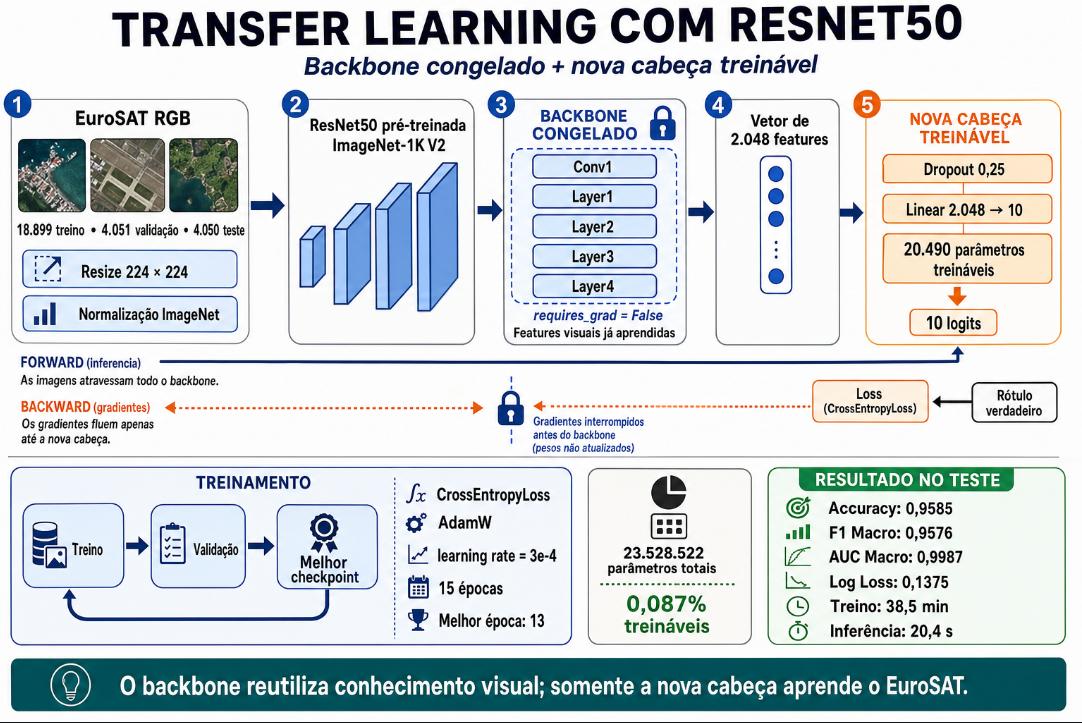


In [57]:
# =============================================================================
# PREPARAÇÃO DO EXPERIMENTO COM TRANSFER LEARNING — RESNET50
# =============================================================================
#
# Objetivo desta célula:
#
# 1. Separar os dados de treino, validação e teste.
# 2. Criar os Datasets específicos da ResNet50.
# 3. Criar os DataLoaders.
# 4. Carregar uma ResNet50 pré-treinada na ImageNet.
# 5. Congelar o backbone da rede.
# 6. Substituir a camada classificadora original.
# 7. Definir loss, otimizador e scheduler.
#
# Esta célula somente prepara o experimento.
# O treinamento será realizado na próxima célula.
# =============================================================================


# O bloco será executado somente quando os treinamentos estiverem habilitados.
if EXECUTAR_TREINOS:

    # =========================================================================
    # 1. SEPARAR TREINO, VALIDAÇÃO E TESTE
    # =========================================================================
    #
    # df_splits contém todas as imagens e uma coluna chamada "split".
    # Essa coluna informa se cada imagem pertence ao:
    #
    # - treino;
    # - validação;
    # - teste.
    #
    # Criamos DataFrames separados para deixar o fluxo explícito.
    # =========================================================================

    # Seleciona somente as imagens destinadas ao treinamento.
    resnet_treino_df = df_splits[
        df_splits["split"].eq("treino")
    ].copy()

    # Seleciona somente as imagens destinadas à validação.
    #
    # A validação será utilizada para:
    # - acompanhar a generalização;
    # - escolher a melhor época;
    # - controlar o scheduler;
    # - aplicar early stopping.
    resnet_validacao_df = df_splits[
        df_splits["split"].eq("validacao")
    ].copy()

    # Seleciona somente as imagens destinadas ao teste.
    #
    # O teste será consultado apenas depois que todas as decisões
    # sobre o modelo tiverem sido tomadas.
    resnet_teste_df = df_splits[
        df_splits["split"].eq("teste")
    ].copy()

    # No modo rápido, selecionamos até 120 imagens de cada classe.
    #
    # Como existem dez classes:
    #
    #     120 imagens × 10 classes = 1.200 imagens por split
    #
    # Esse modo é útil para testar o funcionamento do código.
    # SE MODO_RAPIDO_RESNET = False, o treinamento completo será realizado.
    MODO_RAPIDO_RESNET = False

    if MODO_RAPIDO_RESNET:
        resnet_treino_df = subconjunto_rapido(
            resnet_treino_df,
            n_por_classe=120,
        )

        resnet_validacao_df = subconjunto_rapido(
            resnet_validacao_df,
            n_por_classe=120,
        )

        resnet_teste_df = subconjunto_rapido(
            resnet_teste_df,
            n_por_classe=120,
        )

    # Exibe quantas imagens serão usadas no experimento.
    print(
        "Imagens | treino:",
        len(resnet_treino_df),
        "| validação:",
        len(resnet_validacao_df),
        "| teste:",
        len(resnet_teste_df),
    )

    # =========================================================================
    # 2. CRIAR OS DATASETS
    # =========================================================================
    #
    # EuroSATPaths é a classe Dataset definida anteriormente.
    #
    # Ela recebe:
    # - o DataFrame com os caminhos das imagens;
    # - as transformações que devem ser aplicadas.
    #
    # A ResNet50 pré-treinada espera imagens:
    # - com três canais RGB;
    # - redimensionadas para 224 × 224;
    # - normalizadas com as estatísticas da ImageNet.
    # =========================================================================

    # Dataset de treinamento.
    #
    # transform_treino contém data augmentation, por exemplo:
    # - cortes e redimensionamentos;
    # - flips;
    # - rotações;
    # - pequenas alterações de cor.
    dataset_resnet_treino = EuroSATPaths(
        resnet_treino_df,
        transform_treino,
    )

    # Dataset de validação.
    #
    # A validação não recebe augmentation aleatório.
    # Queremos avaliar sempre versões estáveis das imagens.
    dataset_resnet_validacao = EuroSATPaths(
        resnet_validacao_df,
        transform_avaliacao,
    )

    # Dataset de teste.
    #
    # Também utiliza apenas transformações determinísticas.
    dataset_resnet_teste = EuroSATPaths(
        resnet_teste_df,
        transform_avaliacao,
    )

    # =========================================================================
    # 3. CRIAR OS DATALOADERS
    # =========================================================================
    #
    # O DataLoader agrupa as imagens em batches.
    #
    # Com batch_size=32, cada batch terá normalmente:
    #
    #     imagens.shape = (32, 3, 224, 224)
    #     labels.shape  = (32,)
    #
    # A última parcela pode conter menos de 32 imagens.
    # =========================================================================

    batch_size_resnet = 32

    # -------------------------------------------------------------------------
    # DataLoader de treinamento
    # -------------------------------------------------------------------------

    loader_resnet_treino = DataLoader(
        # Dataset de onde as imagens serão obtidas.
        dataset_resnet_treino,

        # Quantidade de imagens processadas de uma vez.
        batch_size=batch_size_resnet,

        # Embaralha a ordem das imagens em cada época.
        shuffle=True,

        # Quantidade de processos auxiliares para carregar imagens.
        # No Windows, normalmente usamos zero para evitar problemas.
        num_workers=CFG.num_workers,

        # Quando existe GPU, prepara a memória para acelerar a transferência
        # dos dados da RAM para a GPU.
        pin_memory=torch.cuda.is_available(),

        # Define sementes reproduzíveis para os workers.
        worker_init_fn=worker_seed,

        # Torna o embaralhamento reproduzível.
        generator=criar_gerador(SEED),
    )

    # -------------------------------------------------------------------------
    # DataLoader de validação
    # -------------------------------------------------------------------------

    loader_resnet_validacao = DataLoader(
        dataset_resnet_validacao,
        batch_size=batch_size_resnet,

        # Não precisamos embaralhar porque não haverá treinamento.
        shuffle=False,

        num_workers=CFG.num_workers,
        pin_memory=torch.cuda.is_available(),
        worker_init_fn=worker_seed,
    )

    # -------------------------------------------------------------------------
    # DataLoader de teste
    # -------------------------------------------------------------------------

    loader_resnet_teste = DataLoader(
        dataset_resnet_teste,
        batch_size=batch_size_resnet,
        shuffle=False,
        num_workers=CFG.num_workers,
        pin_memory=torch.cuda.is_available(),
        worker_init_fn=worker_seed,
    )

    # =========================================================================
    # 4. CARREGAR A RESNET50 PRÉ-TREINADA
    # =========================================================================
    #
    # models.resnet50 cria a arquitetura ResNet50.
    #
    # IMAGENET1K_V2 seleciona pesos aprendidos previamente na ImageNet.
    # A ImageNet possui aproximadamente 1.000 classes de objetos.
    #
    # Na primeira execução, o torchvision pode precisar baixar os pesos.
    # =========================================================================

    resnet50 = models.resnet50(
        weights=models.ResNet50_Weights.IMAGENET1K_V2,
    )

    # =========================================================================
    # 5. CONGELAR O BACKBONE
    # =========================================================================
    #
    # O backbone é a parte da ResNet responsável pela extração das features.
    #
    # Ele já aprendeu padrões como:
    # - bordas;
    # - cores;
    # - texturas;
    # - formas;
    # - combinações visuais mais complexas.
    #
    # requires_grad=False informa ao PyTorch que esses parâmetros não devem
    # receber gradientes nem ser atualizados pelo otimizador.
    # =========================================================================

    for parametro in resnet50.parameters():
        parametro.requires_grad = False

    # Controla se o último bloco residual também será treinado.
    #
    # False:
    #     somente a nova cabeça classificadora será treinada.
    #
    # True:
    #     a layer4 e a nova cabeça serão treinadas.
    #
    # Começamos com False porque:
    # - exige menos memória;
    # - é mais rápido;
    # - reduz o risco de overfitting;
    # - preserva inicialmente as features pré-treinadas.
    DESCONGELAR_LAYER4 = False

    # Se decidirmos realizar fine-tuning parcial, reativamos os gradientes
    # apenas nos parâmetros da layer4.
    if DESCONGELAR_LAYER4:

        for parametro in resnet50.layer4.parameters():
            parametro.requires_grad = True

    # =========================================================================
    # 6. SUBSTITUIR A CABEÇA CLASSIFICADORA
    # =========================================================================
    #
    # A camada original da ResNet50 foi criada para as 1.000 classes da
    # ImageNet.
    #
    # Precisamos substituí-la porque o EuroSAT possui somente dez classes.
    # =========================================================================

    # Recupera a quantidade de features que chegam à camada final.
    #
    # Na ResNet50, normalmente:
    #
    #     features_entrada_resnet = 2048
    features_entrada_resnet = resnet50.fc.in_features

    # Substitui a camada original por uma nova cabeça.
    #
    # A nova camada Linear transforma:
    #
    #     (N, 2048) → (N, 10)
    #
    # Cada imagem receberá dez logits, um para cada classe do EuroSAT.
    resnet50.fc = nn.Sequential(

        # Desliga aleatoriamente 25% das features durante o treinamento.
        # Isso ajuda a reduzir overfitting na nova cabeça.
        nn.Dropout(p=0.25),

        # Camada classificadora do EuroSAT.
        nn.Linear(
            in_features=features_entrada_resnet,
            out_features=len(CLASSES),
        ),
    )

    # Um detalhe importante:
    #
    # A nova camada Linear foi criada depois que congelamos a rede.
    # Por padrão, seus parâmetros são criados com requires_grad=True.
    #
    # Portanto:
    # - backbone permanece congelado;
    # - nova cabeça permanece treinável.

    # Move o modelo para a GPU CUDA, quando disponível.
    resnet50 = resnet50.to(DEVICE)

    # =========================================================================
    # 7. DEFINIR A FUNÇÃO DE LOSS
    # =========================================================================
    #
    # CrossEntropyLoss é apropriada para classificação multiclasse.
    #
    # Ela espera:
    #
    #     logits: (N, 10)
    #     labels: (N,)
    #
    # Os labels devem conter índices inteiros de 0 a 9.
    #
    # Não devemos aplicar softmax antes da CrossEntropyLoss porque ela já
    # realiza internamente a operação necessária.
    # =========================================================================

    loss_fn_resnet = nn.CrossEntropyLoss()

    # =========================================================================
    # 8. SELECIONAR OS PARÂMETROS TREINÁVEIS
    # =========================================================================
    #
    # Criamos uma lista contendo somente os parâmetros com:
    #
    #     requires_grad=True
    #
    # Se DESCONGELAR_LAYER4=False:
    #     somente a nova cabeça entra nesta lista.
    #
    # Se DESCONGELAR_LAYER4=True:
    #     layer4 e a nova cabeça entram nesta lista.
    # =========================================================================

    parametros_resnet_otimizados = [
        parametro
        for parametro in resnet50.parameters()
        if parametro.requires_grad
    ]

    # =========================================================================
    # 9. CRIAR O OTIMIZADOR
    # =========================================================================
    #
    # AdamW atualizará somente os parâmetros presentes na lista anterior.
    #
    # lr:
    #     controla o tamanho das atualizações.
    #
    # weight_decay:
    #     penaliza pesos excessivamente grandes e atua como regularização.
    # =========================================================================

    optimizer_resnet = torch.optim.AdamW(
        parametros_resnet_otimizados,
        lr=3e-4,
        weight_decay=1e-4,
    )

    # =========================================================================
    # 10. CRIAR O SCHEDULER
    # =========================================================================
    #
    # ReduceLROnPlateau acompanha a loss de validação.
    #
    # Se a loss deixar de melhorar, a learning rate será reduzida.
    # =========================================================================

    scheduler_resnet = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer_resnet,

        # Queremos minimizar a loss de validação.
        mode="min",

        # Espera duas épocas sem melhora.
        patience=2,

        # Reduz a learning rate pela metade:
        #
        #     nova_lr = lr_atual × 0.5
        factor=0.5,
    )

    # =========================================================================
    # 11. CONTAR OS PARÂMETROS
    # =========================================================================

    # Conta todos os parâmetros da ResNet50, congelados ou não.
    total_parametros_resnet = sum(
        parametro.numel()
        for parametro in resnet50.parameters()
    )

    # Conta somente os parâmetros que serão atualizados pelo otimizador.
    treinaveis_resnet = sum(
        parametro.numel()
        for parametro in resnet50.parameters()
        if parametro.requires_grad
    )

    # Calcula o percentual de parâmetros treináveis.
    percentual_treinavel_resnet = (
        100 * treinaveis_resnet / total_parametros_resnet
    )

    # =========================================================================
    # 12. CONFERIR A CONFIGURAÇÃO
    # =========================================================================

    # Exibe a nova cabeça classificadora.
    print("Nova cabeça da ResNet50:")
    print(resnet50.fc)

    # Exibe a quantidade total e treinável de parâmetros.
    print(
        f"Parâmetros treináveis: "
        f"{treinaveis_resnet:,}/"
        f"{total_parametros_resnet:,} "
        f"({percentual_treinavel_resnet:.3f}%)"
    )

    # Mostra se a layer4 está congelada ou liberada para treinamento.
    print(
        "Layer4 descongelada:",
        DESCONGELAR_LAYER4,
    )

    # Confirma o dispositivo utilizado.
    print(
        "Dispositivo:",
        DEVICE,
    )

    print(
        "O experimento está preparado. "
        "A próxima célula executa treino, validação e teste."
    )

else:
    # Esta mensagem aparece quando os treinamentos estão desativados.
    print(
        "Preparação da ResNet50 aguardando "
        "EXECUTAR_TREINOS=True."
    )

Imagens | treino: 18899 | validação: 4051 | teste: 4050


Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to C:\Users\leova/.cache\torch\hub\checkpoints\resnet50-11ad3fa6.pth
100%|██████████| 97.8M/97.8M [00:00<00:00, 104MB/s] 

Nova cabeça da ResNet50:
Sequential(
  (0): Dropout(p=0.25, inplace=False)
  (1): Linear(in_features=2048, out_features=10, bias=True)
)
Parâmetros treináveis: 20,490/23,528,522 (0.087%)
Layer4 descongelada: False
Dispositivo: cuda
O experimento está preparado. A próxima célula executa treino, validação e teste.


Época 01 | Loss treino 0.7091 | Loss validação 0.3467 | F1 validação 0.9019
Época 02 | Loss treino 0.2752 | Loss validação 0.2532 | F1 validação 0.9222
Época 03 | Loss treino 0.2247 | Loss validação 0.2210 | F1 validação 0.9291
Época 04 | Loss treino 0.1985 | Loss validação 0.2026 | F1 validação 0.9315
Época 05 | Loss treino 0.1803 | Loss validação 0.1858 | F1 validação 0.9385
Época 06 | Loss treino 0.1667 | Loss validação 0.1748 | F1 validação 0.9414
Época 07 | Loss treino 0.1613 | Loss validação 0.1723 | F1 validação 0.9404
Época 08 | Loss treino 0.1515 | Loss validação 0.1665 | F1 validação 0.9439
Época 09 | Loss treino 0.1481 | Loss validação 0.1606 | F1 validação 0.9443
Época 10 | Loss treino 0.1410 | Loss validação 0.1534 | F1 validação 0.9450
Época 11 | Loss treino 0.1373 | Loss validação 0.1477 | F1 validação 0.9476
Época 12 | Loss treino 0.1317 | Loss validação 0.1487 | F1 validação 0.9467
Época 13 | Loss treino 0.1288 | Loss validação 0.1370 | F1 validação 0.9526
Época 14 | L

,métrica,valor
0,Accuracy,0.958519
1,Precision Macro,0.957561
2,Recall Macro,0.958222
3,F1 Macro,0.957631
4,AUC OVR Macro,0.998737
5,Log Loss,0.137477


,classe,f1
6,PermanentCrop,0.919334
8,River,0.937583
3,Highway,0.937913
2,HerbaceousVegetation,0.939704
0,AnnualCrop,0.952596
5,Pasture,0.958124
4,Industrial,0.980027
9,SeaLake,0.983089
7,Residential,0.983425
1,Forest,0.984513


Treino: 2308.5s | Inferência: 20.4s | Parâmetros treináveis: 20,490


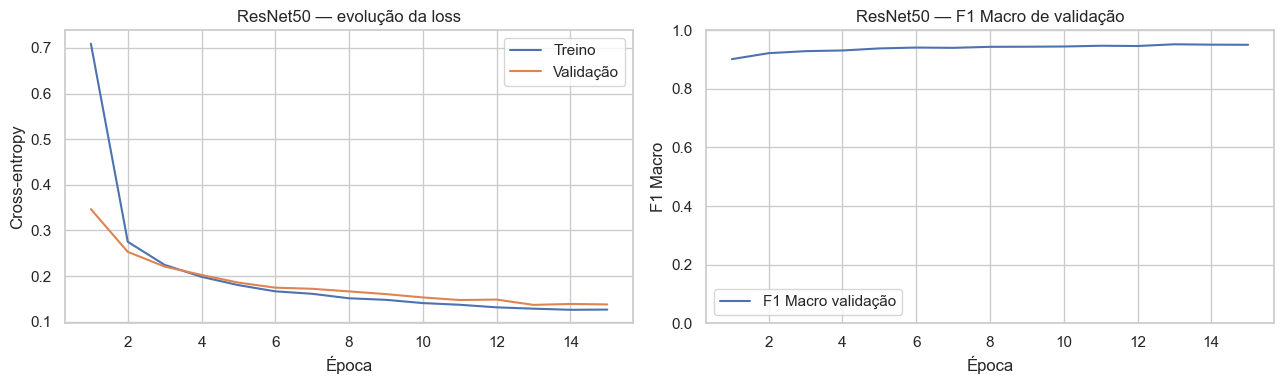

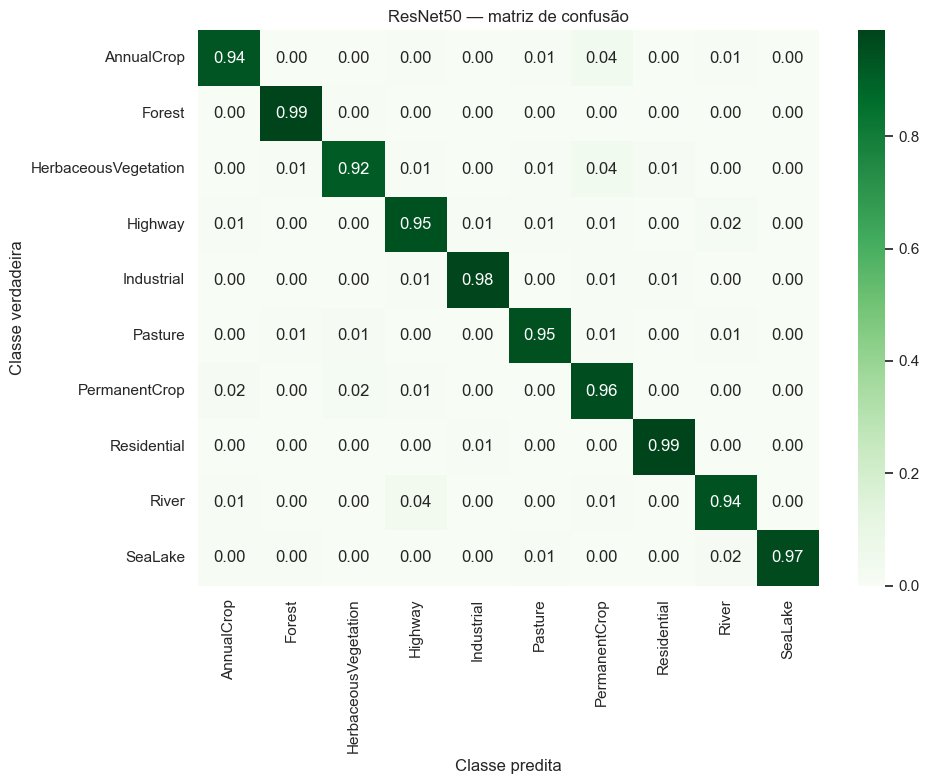

In [58]:
# -----------------------------------------------------------------------------
# Objetivo desta célula: Treinar, validar e testar a ResNet50 cronologicamente.
# -----------------------------------------------------------------------------
if EXECUTAR_TREINOS:
    from sklearn.metrics import log_loss

    # -------------------------------------------------------------------------
    # 1. PREPARAR HISTÓRICO E EARLY STOPPING
    # -------------------------------------------------------------------------
    historico_resnet = []
    melhor_f1_resnet = -np.inf
    melhor_estado_resnet = None
    epocas_sem_melhora_resnet = 0

    max_epocas_resnet = (6 if MODO_RAPIDO_RESNET else 15)
    paciencia_resnet = 4

    inicio_treino_resnet = time.perf_counter()

    # -------------------------------------------------------------------------
    # 2. LOOP DE ÉPOCAS
    # -------------------------------------------------------------------------
    for epoca in range(1, max_epocas_resnet + 1):

        # ----------------------------- TREINO --------------------------------
        resnet50.train()

        # Se o backbone está congelado, mantemos suas BatchNorms em avaliação
        # para não atualizar estatísticas internas sem atualizar os pesos.
        if not DESCONGELAR_LAYER4:
            for modulo in resnet50.modules():
                if isinstance(modulo, nn.BatchNorm2d):
                    modulo.eval()

        soma_loss_treino = 0.0

        for imagens, labels in loader_resnet_treino:
            imagens = imagens.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)

            optimizer_resnet.zero_grad(set_to_none=True)

            logits = resnet50(imagens)
            loss = loss_fn_resnet(logits, labels)

            loss.backward()
            nn.utils.clip_grad_norm_(
                parametros_resnet_otimizados,
                max_norm=1.0,
            )
            optimizer_resnet.step()

            soma_loss_treino += loss.item()

        loss_treino_resnet = (
            soma_loss_treino / len(loader_resnet_treino)
        )

        # --------------------------- VALIDAÇÃO -------------------------------
        resnet50.eval()
        soma_loss_validacao = 0.0
        labels_validacao = []
        predicoes_validacao = []

        with torch.no_grad():
            for imagens, labels in loader_resnet_validacao:
                imagens = imagens.to(DEVICE, non_blocking=True)
                labels_device = labels.to(DEVICE, non_blocking=True)

                logits = resnet50(imagens)
                loss = loss_fn_resnet(
                    logits,
                    labels_device,
                )

                predicoes = logits.argmax(dim=1)

                soma_loss_validacao += loss.item()
                labels_validacao.append(labels.numpy())
                predicoes_validacao.append(
                    predicoes.cpu().numpy()
                )

        loss_validacao_resnet = (
            soma_loss_validacao
            / len(loader_resnet_validacao)
        )

        y_validacao_resnet = np.concatenate(
            labels_validacao
        )
        pred_validacao_resnet = np.concatenate(
            predicoes_validacao
        )

        f1_validacao_resnet = f1_score(
            y_validacao_resnet,
            pred_validacao_resnet,
            average="macro",
            zero_division=0,
        )

        scheduler_resnet.step(loss_validacao_resnet)

        historico_resnet.append({
            "epoca": epoca,
            "loss_treino": loss_treino_resnet,
            "loss_validacao": loss_validacao_resnet,
            "f1_validacao": f1_validacao_resnet,
        })

        print(
            f"Época {epoca:02d} | "
            f"Loss treino {loss_treino_resnet:.4f} | "
            f"Loss validação {loss_validacao_resnet:.4f} | "
            f"F1 validação {f1_validacao_resnet:.4f}"
        )

        # ----------------------- MELHOR CHECKPOINT ---------------------------
        if f1_validacao_resnet > melhor_f1_resnet + 1e-4:
            melhor_f1_resnet = f1_validacao_resnet
            melhor_estado_resnet = copy.deepcopy(
                resnet50.state_dict()
            )
            epocas_sem_melhora_resnet = 0
        else:
            epocas_sem_melhora_resnet += 1

            if (
                epocas_sem_melhora_resnet
                >= paciencia_resnet
            ):
                print("Early stopping acionado.")
                break

    tempo_treino_resnet = (
        time.perf_counter() - inicio_treino_resnet
    )

    # Restauramos a melhor época e salvamos seu estado.
    resnet50.load_state_dict(melhor_estado_resnet)

    caminho_resnet = (
        ARTIFACT_DIR / "resnet50_eurosat_best.pt"
    )
    torch.save(resnet50.state_dict(), caminho_resnet)

    # -------------------------------------------------------------------------
    # 3. TESTE FINAL
    # -------------------------------------------------------------------------
    resnet50.eval()

    labels_teste_resnet = []
    predicoes_teste_resnet = []
    probabilidades_teste_resnet = []

    inicio_inferencia_resnet = time.perf_counter()

    with torch.no_grad():
        for imagens, labels in loader_resnet_teste:
            imagens = imagens.to(DEVICE, non_blocking=True)

            logits = resnet50(imagens)
            probabilidades = logits.softmax(dim=1)
            predicoes = probabilidades.argmax(dim=1)

            labels_teste_resnet.append(labels.numpy())
            predicoes_teste_resnet.append(
                predicoes.cpu().numpy()
            )
            probabilidades_teste_resnet.append(
                probabilidades.cpu().numpy()
            )

    tempo_inferencia_resnet = (
        time.perf_counter() - inicio_inferencia_resnet
    )

    y_res = np.concatenate(labels_teste_resnet)
    pred_res = np.concatenate(predicoes_teste_resnet)
    proba_res = np.concatenate(
        probabilidades_teste_resnet
    )

    # -------------------------------------------------------------------------
    # 4. MÉTRICAS DA RESNET50
    # -------------------------------------------------------------------------
    accuracy_res = accuracy_score(y_res, pred_res)
    precision_res = precision_score(
        y_res,
        pred_res,
        average="macro",
        zero_division=0,
    )
    recall_res = recall_score(
        y_res,
        pred_res,
        average="macro",
        zero_division=0,
    )
    f1_macro_res = f1_score(
        y_res,
        pred_res,
        average="macro",
        zero_division=0,
    )
    auc_res = roc_auc_score(
        y_res,
        proba_res,
        multi_class="ovr",
        average="macro",
    )
    log_loss_res = log_loss(
        y_res,
        proba_res,
        labels=range(len(CLASSES)),
    )
    f1_classes_res = f1_score(
        y_res,
        pred_res,
        labels=range(len(CLASSES)),
        average=None,
        zero_division=0,
    )

    tamanho_resnet_mb = (
        caminho_resnet.stat().st_size / 1024**2
    )

    metricas_resnet = pd.DataFrame({
        "métrica": [
            "Accuracy",
            "Precision Macro",
            "Recall Macro",
            "F1 Macro",
            "AUC OVR Macro",
            "Log Loss",
        ],
        "valor": [
            accuracy_res,
            precision_res,
            recall_res,
            f1_macro_res,
            auc_res,
            log_loss_res,
        ],
    })

    f1_por_classe_resnet = pd.DataFrame({
        "classe": CLASSES,
        "f1": f1_classes_res,
    }).sort_values("f1")

    display(metricas_resnet)
    display(f1_por_classe_resnet)

    # -------------------------------------------------------------------------
    # 5. CURVAS DE APRENDIZADO
    # -------------------------------------------------------------------------
    historico_resnet_df = pd.DataFrame(
        historico_resnet
    )

    fig, axes = plt.subplots(1, 2, figsize=(13, 4))

    axes[0].plot(
        historico_resnet_df["epoca"],
        historico_resnet_df["loss_treino"],
        label="Treino",
    )
    axes[0].plot(
        historico_resnet_df["epoca"],
        historico_resnet_df["loss_validacao"],
        label="Validação",
    )
    axes[0].set_title("ResNet50 — evolução da loss")
    axes[0].set_xlabel("Época")
    axes[0].set_ylabel("Cross-entropy")
    axes[0].legend()

    axes[1].plot(
        historico_resnet_df["epoca"],
        historico_resnet_df["f1_validacao"],
        label="F1 Macro validação",
    )
    axes[1].set_title("ResNet50 — F1 Macro de validação")
    axes[1].set_xlabel("Época")
    axes[1].set_ylabel("F1 Macro")
    axes[1].set_ylim(0, 1)
    axes[1].legend()

    plt.tight_layout()

    # -------------------------------------------------------------------------
    # 6. MATRIZ DE CONFUSÃO
    # -------------------------------------------------------------------------
    matriz_resnet = confusion_matrix(
        y_res,
        pred_res,
        labels=range(len(CLASSES)),
        normalize="true",
    )

    plt.figure(figsize=(10, 8))
    sns.heatmap(
        matriz_resnet,
        annot=True,
        fmt=".2f",
        cmap="Greens",
        xticklabels=CLASSES,
        yticklabels=CLASSES,
    )
    plt.title("ResNet50 — matriz de confusão")
    plt.xlabel("Classe predita")
    plt.ylabel("Classe verdadeira")
    plt.tight_layout()

    # -------------------------------------------------------------------------
    # 7. REGISTRO PARA O BENCHMARK
    # -------------------------------------------------------------------------
    RESULTADOS["ResNet50"] = {
        "modelo": "ResNet50",
        "accuracy": accuracy_res,
        "precision_macro": precision_res,
        "recall_macro": recall_res,
        "f1_macro": f1_macro_res,
        "auc_ovr_macro": auc_res,
        "log_loss": log_loss_res,
        "treino_s": tempo_treino_resnet,
        "inferencia_s": tempo_inferencia_resnet,
        "parametros_totais": total_parametros_resnet,
        "parametros_treinaveis": treinaveis_resnet,
        "tamanho_mb": tamanho_resnet_mb,
        **{
            f"f1_{classe}": valor
            for classe, valor in zip(
                CLASSES,
                f1_classes_res,
            )
        },
    }

    print(
        f"Treino: {tempo_treino_resnet:.1f}s | "
        f"Inferência: {tempo_inferencia_resnet:.1f}s | "
        f"Parâmetros treináveis: {treinaveis_resnet:,}"
    )
else:
    print(
        "Treino da ResNet50 aguardando "
        "EXECUTAR_TREINOS=True."
    )

**Como interpretar:** uma cabeça congelada tem baixo custo e reduz risco de sobreajuste; descongelar `layer4` aumenta capacidade e custo. A decisão deve vir da validação.

**Conclusão da seção:** transfer learning reaproveita uma representação visual geral e aprende apenas a fronteira necessária para as dez classes.


## 17. ViT congelado: extração de embeddings e LightGBM

**Pergunta de aprendizagem:** como separar a representação visual da classificação final?

Este módulo reúne as duas partes de um único pipeline. Primeiro, um Vision Transformer pré-treinado e totalmente congelado converte cada imagem em um vetor de 768 características. Depois, o LightGBM aprende a transformar esses vetores nas dez classes do EuroSAT.

```text
Imagem RGB (3, 224, 224)
        ↓ ViT congelado
197 tokens = 196 patches + token [CLS]
        ↓ selecionar o token [CLS]
Embedding (768 características)
        ↓ LightGBM multiclasse
10 probabilidades + classe prevista
```

### Da imagem aos tokens

O checkpoint `google/vit-base-patch16-224-in21k` divide uma imagem $224\times224$ em patches de $16\times16$:

$$
N_{patches}=\frac{224}{16}\times\frac{224}{16}=14\times14=196
$$

O modelo adiciona o token especial `[CLS]`, totalizando 197 tokens. Após os blocos Transformer, a posição zero funciona como um resumo contextual da imagem:

$$
h_{CLS}\in\mathbb{R}^{768}
$$

Embedding não é previsão. Ele é uma representação numérica que ainda precisa de um classificador.

### Self-attention

Para cada token, o Transformer constrói Query, Key e Value:

$$
Q=XW_Q,\qquad K=XW_K,\qquad V=XW_V
$$

$$
Attention(Q,K,V)=softmax\left(\frac{QK^T}{\sqrt{d_k}}\right)V
$$

O token `[CLS]` participa dessas relações e acumula informação dos patches. Como o backbone ficará congelado, nenhum peso do ViT será ajustado com os rótulos do EuroSAT.

### LightGBM sobre a representação congelada

Para $N$ imagens, o classificador recebe:

$$
X_{emb}\in\mathbb{R}^{N\times768},\qquad y\in\{0,\ldots,9\}^N
$$

O gradient boosting adiciona árvores sequencialmente para corrigir os erros do conjunto anterior:

$$
F_m(x)=F_{m-1}(x)+\eta f_m(x)
$$

O fluxo experimental respeita a separação dos dados: as configurações são treinadas no treino, escolhidas pelo F1 Macro de validação e avaliadas uma única vez no teste. Não existe backpropagation do LightGBM para o ViT.

| Etapa | Implementação |
|---|---|
| Pré-processamento do checkpoint | `AutoImageProcessor` |
| Backbone sem classificador | `ViTModel` |
| ViT congelado | `requires_grad=False` |
| Inferência sem gradientes | `torch.inference_mode()` |
| Embedding da imagem | `last_hidden_state[:, 0]` |
| Classificador externo | `LGBMClassifier` |
| Seleção de configuração | F1 Macro na validação |
| Avaliação final | teste consultado uma vez |


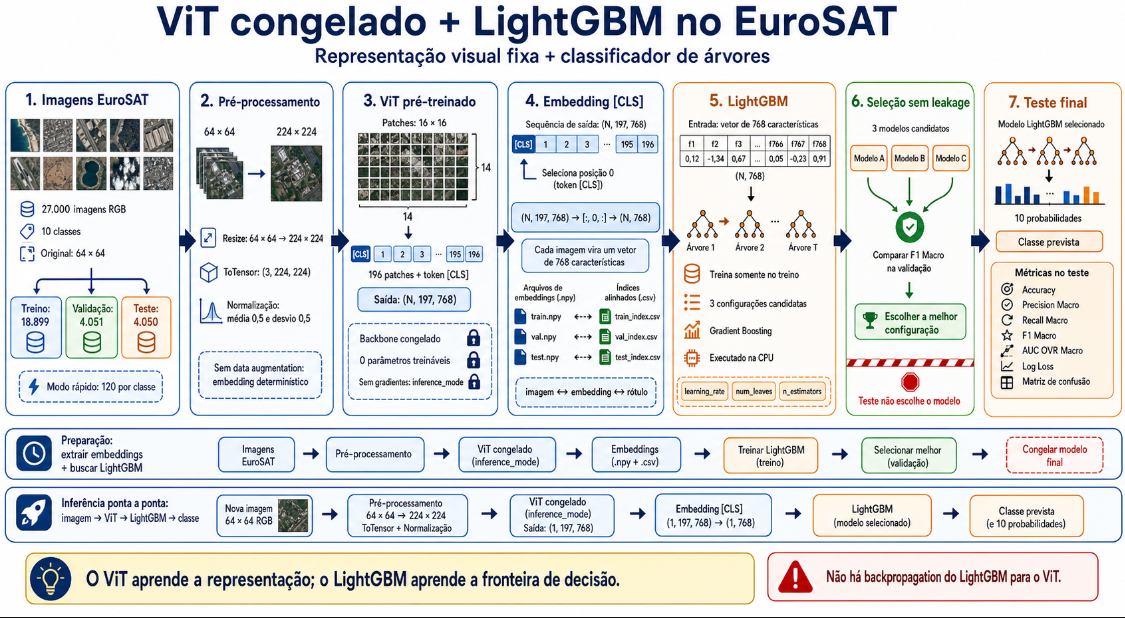

In [87]:
# =============================================================================
# PREPARAÇÃO DO PIPELINE: VIT CONGELADO + LIGHTGBM
# =============================================================================
#
# Objetivo desta célula:
#
# 1. Carregar as configurações de pré-processamento do ViT.
# 2. Redimensionar e normalizar as imagens no padrão do checkpoint.
# 3. Separar treino, validação e teste.
# 4. Aplicar, opcionalmente, uma amostragem rápida.
# 5. Criar Datasets e DataLoaders específicos para o ViT.
# 6. Liberar da GPU os modelos treinados anteriormente.
# 7. Carregar e congelar o backbone do Vision Transformer.
#
# IMPORTANTE:
#
# Esta célula ainda não extrai os embeddings e não treina o LightGBM.
# Ela apenas prepara os dados e o modelo que serão usados na próxima célula.
#
# Fluxo preparado:
#
# imagem EuroSAT
# (3, 64, 64)
#       ↓ Resize
# (3, 224, 224)
#       ↓ normalização
# tensor no padrão do checkpoint
#       ↓ ViT congelado
# embedding CLS
# (768 características)
# =============================================================================


# O bloco só será executado quando as etapas de modelagem estiverem habilitadas.
if EXECUTAR_TREINOS:

    # Confere se a biblioteca transformers está disponível no kernel.
    exigir_pacote("transformers")

    # AutoImageProcessor:
    # recupera as configurações de pré-processamento do checkpoint.
    #
    # ViTModel:
    # carrega apenas o backbone do Vision Transformer, sem uma cabeça de
    # classificação específica para as classes do EuroSAT.
    from transformers import AutoImageProcessor
    from transformers import ViTModel

    # =========================================================================
    # 1. CONTROLES EXCLUSIVOS DO EXPERIMENTO
    # =========================================================================

    # True:
    # utiliza até 120 imagens por classe em cada split.
    #
    # False:
    # utiliza todas as imagens disponíveis:
    # - treino: 18.899;
    # - validação: 4.051;
    # - teste: 4.050.
    #
    # Recomenda-se começar com True para validar o pipeline.
    MODO_RAPIDO_VIT = False

    # Quantidade máxima de imagens de cada classe quando o modo rápido estiver
    # ativado.
    AMOSTRAS_POR_CLASSE_VIT = 120

    # Quantidade máxima de imagens que serão processadas simultaneamente.
    #
    # Um batch completo terá o formato:
    #
    # (N, C, H, W) = (32, 3, 224, 224)
    #
    # Caso ocorra "CUDA out of memory", reduza para 16.
    BATCH_SIZE_VIT = 32

    # O sufixo identifica se os embeddings foram produzidos no modo rápido ou
    # usando o conjunto completo.
    #
    # Isso impede que uma execução rápida sobrescreva os arquivos definitivos.
    sufixo_vit = (
        "rapido"
        if MODO_RAPIDO_VIT
        else "completo"
    )

    # =========================================================================
    # 2. DEFINIR OS CAMINHOS DOS ARTEFATOS
    # =========================================================================

    # Arquivo que armazenará os embeddings das imagens de treinamento.
    caminho_embeddings_treino = (
        DATA_DIR
        / f"vit_embeddings_train_{sufixo_vit}.npy"
    )

    # Arquivo que armazenará os rótulos do treinamento na mesma ordem dos
    # embeddings.
    caminho_labels_treino = (
        DATA_DIR
        / f"vit_labels_train_{sufixo_vit}.npy"
    )

    # Embeddings e rótulos do conjunto de validação.
    caminho_embeddings_validacao = (
        DATA_DIR
        / f"vit_embeddings_val_{sufixo_vit}.npy"
    )

    caminho_labels_validacao = (
        DATA_DIR
        / f"vit_labels_val_{sufixo_vit}.npy"
    )

    # Embeddings e rótulos do conjunto de teste.
    caminho_embeddings_teste = (
        DATA_DIR
        / f"vit_embeddings_test_{sufixo_vit}.npy"
    )

    caminho_labels_teste = (
        DATA_DIR
        / f"vit_labels_test_{sufixo_vit}.npy"
    )

    # =========================================================================
    # 3. CARREGAR O PROCESSADOR DO CHECKPOINT
    # =========================================================================

    # CFG.vit_model_id contém:
    #
    # google/vit-base-patch16-224-in21k
    #
    # O processador informa:
    # - o tamanho esperado das imagens;
    # - a média de cada canal RGB;
    # - o desvio-padrão de cada canal RGB.
    vit_processor = AutoImageProcessor.from_pretrained(
        CFG.vit_model_id
    )

    # Recuperamos a configuração de tamanho retornada pelo processador.
    configuracao_tamanho_vit = vit_processor.size

    # =========================================================================
    # 4. DESCOBRIR O TAMANHO ESPERADO PELO VIT
    # =========================================================================

    # Versões recentes da biblioteca transformers retornam um objeto SizeDict.
    # Nesse caso, o tamanho pode ser acessado como atributo:
    #
    # configuracao_tamanho_vit.height
    tamanho_vit = getattr(
        configuracao_tamanho_vit,
        "height",
        None,
    )

    # Alguns processadores utilizam shortest_edge em vez de height.
    if tamanho_vit is None:
        tamanho_vit = getattr(
            configuracao_tamanho_vit,
            "shortest_edge",
            None,
        )

    # Mantém compatibilidade com versões que retornam um dicionário comum.
    if (
        tamanho_vit is None
        and hasattr(configuracao_tamanho_vit, "get")
    ):
        tamanho_vit = configuracao_tamanho_vit.get(
            "height"
        )

        if tamanho_vit is None:
            tamanho_vit = configuracao_tamanho_vit.get(
                "shortest_edge"
            )

    # Mantém compatibilidade com versões que retornam diretamente um número.
    if (
        tamanho_vit is None
        and isinstance(
            configuracao_tamanho_vit,
            (int, float),
        )
    ):
        tamanho_vit = configuracao_tamanho_vit

    # Se nenhuma representação conhecida for encontrada, interrompemos a célula
    # com uma mensagem que mostra o tipo recebido.
    if tamanho_vit is None:
        raise TypeError(
            "Formato desconhecido para vit_processor.size: "
            f"{type(configuracao_tamanho_vit)}"
        )

    # Garante que o tamanho final seja um número inteiro.
    tamanho_vit = int(tamanho_vit)

    # Exibe as configurações recuperadas.
    print("Checkpoint:", CFG.vit_model_id)

    print(
        "Tamanho de entrada:",
        tamanho_vit,
        "x",
        tamanho_vit,
    )

    print(
        "Média RGB:",
        vit_processor.image_mean,
    )

    print(
        "Desvio-padrão RGB:",
        vit_processor.image_std,
    )

    # =========================================================================
    # 5. DEFINIR AS TRANSFORMAÇÕES DAS IMAGENS
    # =========================================================================

    # Não usamos data augmentation aleatório nesta etapa.
    #
    # Queremos que uma mesma imagem produza sempre o mesmo embedding.
    #
    # Fluxo:
    #
    # imagem PIL (64, 64)
    #       ↓ Resize
    # imagem PIL (224, 224)
    #       ↓ ToTensor
    # tensor (3, 224, 224), valores entre 0 e 1
    #       ↓ Normalize
    # tensor no padrão esperado pelo checkpoint
    transform_vit_embeddings = transforms.Compose(
        [
            # Redimensiona a imagem original de 64 × 64 para 224 × 224.
            #
            # A interpolação bilinear estima os novos pixels usando os pixels
            # vizinhos da imagem original.
            transforms.Resize(
                (tamanho_vit, tamanho_vit),
                interpolation=InterpolationMode.BILINEAR,
            ),

            # Converte a imagem PIL para um tensor PyTorch.
            #
            # Também altera a organização:
            #
            # (H, W, C) → (C, H, W)
            #
            # e converte a escala:
            #
            # 0..255 → 0..1
            transforms.ToTensor(),

            # Normaliza os canais vermelho, verde e azul usando os valores do
            # próprio checkpoint.
            #
            # Para cada canal:
            #
            # valor_normalizado = (valor - média) / desvio-padrão
            transforms.Normalize(
                mean=tuple(vit_processor.image_mean),
                std=tuple(vit_processor.image_std),
            ),
        ]
    )

    # =========================================================================
    # 6. SEPARAR TREINO, VALIDAÇÃO E TESTE
    # =========================================================================

    # Selecionamos somente as linhas marcadas como treinamento.
    vit_treino_df = (
        df_splits.loc[
            df_splits["split"].eq("treino")
        ]
        .copy()
        .reset_index(drop=True)
    )

    # Selecionamos somente as linhas marcadas como validação.
    vit_validacao_df = (
        df_splits.loc[
            df_splits["split"].eq("validacao")
        ]
        .copy()
        .reset_index(drop=True)
    )

    # Selecionamos somente as linhas marcadas como teste.
    vit_teste_df = (
        df_splits.loc[
            df_splits["split"].eq("teste")
        ]
        .copy()
        .reset_index(drop=True)
    )

    # =========================================================================
    # 7. APLICAR O MODO RÁPIDO, QUANDO SOLICITADO
    # =========================================================================

    if MODO_RAPIDO_VIT:

        # Seleciona até 120 imagens de cada classe no treino.
        vit_treino_df = subconjunto_rapido(
            vit_treino_df,
            n_por_classe=AMOSTRAS_POR_CLASSE_VIT,
        ).reset_index(drop=True)

        # Aplica a mesma regra ao conjunto de validação.
        vit_validacao_df = subconjunto_rapido(
            vit_validacao_df,
            n_por_classe=AMOSTRAS_POR_CLASSE_VIT,
        ).reset_index(drop=True)

        # Aplica a mesma regra ao conjunto de teste.
        vit_teste_df = subconjunto_rapido(
            vit_teste_df,
            n_por_classe=AMOSTRAS_POR_CLASSE_VIT,
        ).reset_index(drop=True)

    # Armazena as quantidades em um dicionário para facilitar a conferência.
    quantidades_vit = {
        "treino": len(vit_treino_df),
        "validação": len(vit_validacao_df),
        "teste": len(vit_teste_df),
    }

    # Confere se algum conjunto ficou vazio.
    #
    # Isso pode acontecer, por exemplo, se o nome usado na coluna "split"
    # estiver diferente de "treino", "validacao" ou "teste".
    if any(
        quantidade == 0
        for quantidade in quantidades_vit.values()
    ):
        raise ValueError(
            f"Existe split vazio: {quantidades_vit}"
        )

    print(
        "Modo rápido:",
        MODO_RAPIDO_VIT,
    )

    print(
        "Imagens:",
        quantidades_vit,
    )

    # =========================================================================
    # 8. CRIAR OS DATASETS
    # =========================================================================

    # EuroSATPaths recebe dois argumentos:
    #
    # 1. DataFrame contendo os caminhos e rótulos.
    # 2. Transformação aplicada quando uma imagem for carregada.
    #
    # A transformação precisa ser passada como argumento posicional porque a
    # classe não possui um parâmetro chamado "transform".
    dataset_vit_treino = EuroSATPaths(
        vit_treino_df,
        transform_vit_embeddings,
    )

    dataset_vit_validacao = EuroSATPaths(
        vit_validacao_df,
        transform_vit_embeddings,
    )

    dataset_vit_teste = EuroSATPaths(
        vit_teste_df,
        transform_vit_embeddings,
    )

    print("\nTamanho dos Datasets:")

    print(
        "Treino:",
        len(dataset_vit_treino),
    )

    print(
        "Validação:",
        len(dataset_vit_validacao),
    )

    print(
        "Teste:",
        len(dataset_vit_teste),
    )

    # =========================================================================
    # 9. CRIAR O DATALOADER DE TREINO
    # =========================================================================

    # O DataLoader carrega as imagens do Dataset e as organiza em batches.
    #
    # shuffle=False é essencial porque queremos manter:
    #
    # linha do DataFrame
    #       ↕
    # imagem carregada
    #       ↕
    # embedding extraído
    #       ↕
    # rótulo salvo
    loader_vit_treino = DataLoader(
        # Dataset de onde as imagens serão carregadas.
        dataset_vit_treino,

        # Quantidade máxima de imagens em cada batch.
        batch_size=BATCH_SIZE_VIT,

        # Mantém a ordem original das imagens.
        shuffle=False,

        # Quantidade de processos auxiliares para carregar as imagens.
        #
        # No Windows, normalmente usamos zero.
        num_workers=CFG.num_workers,

        # Quando existe GPU, prepara os tensores na RAM para tornar sua
        # transferência para a GPU mais eficiente.
        pin_memory=torch.cuda.is_available(),

        # Define sementes reproduzíveis para os workers.
        worker_init_fn=worker_seed,
    )

    # =========================================================================
    # 10. CRIAR O DATALOADER DE VALIDAÇÃO
    # =========================================================================

    loader_vit_validacao = DataLoader(
        dataset_vit_validacao,
        batch_size=BATCH_SIZE_VIT,

        # A validação também deve manter a ordem dos exemplos.
        shuffle=False,

        num_workers=CFG.num_workers,
        pin_memory=torch.cuda.is_available(),
        worker_init_fn=worker_seed,
    )

    # =========================================================================
    # 11. CRIAR O DATALOADER DE TESTE
    # =========================================================================

    loader_vit_teste = DataLoader(
        dataset_vit_teste,
        batch_size=BATCH_SIZE_VIT,

        # O teste também não deve ser embaralhado.
        shuffle=False,

        num_workers=CFG.num_workers,
        pin_memory=torch.cuda.is_available(),
        worker_init_fn=worker_seed,
    )

    # Exibe quantos batches serão processados em cada conjunto.
    print(
        "\nBatches | treino:",
        len(loader_vit_treino),
        "| validação:",
        len(loader_vit_validacao),
        "| teste:",
        len(loader_vit_teste),
    )

    # =========================================================================
    # 12. LIBERAR A GPU DOS MODELOS ANTERIORES
    # =========================================================================

    # CNN e ResNet podem continuar existindo como objetos Python depois de seus
    # treinamentos.
    #
    # Se continuarem na GPU, ocuparão memória que será necessária para o ViT.
    #
    # Movê-los para a CPU:
    # - não apaga os modelos;
    # - não altera seus pesos;
    # - apenas libera espaço na memória da GPU.
    for nome_modelo_anterior in (
        "cnn_final",
        "resnet50",
    ):
        # Procura o objeto pelo nome no ambiente global do notebook.
        modelo_anterior = globals().get(
            nome_modelo_anterior
        )

        # Só tenta mover o objeto se ele for realmente um modelo PyTorch.
        if isinstance(modelo_anterior, nn.Module):
            modelo_anterior.to("cpu")

    # empty_cache libera blocos de memória CUDA que não estão mais sendo
    # utilizados por tensores ativos.
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    # =========================================================================
    # 13. CARREGAR O BACKBONE VIT PRÉ-TREINADO
    # =========================================================================

    # ViTModel carrega somente o backbone.
    #
    # Isso significa que o modelo produz representações internas, mas não possui
    # uma cabeça final específica para classificar as dez classes do EuroSAT.
    vit_backbone = ViTModel.from_pretrained(
        CFG.vit_model_id,
    )

    # Move o ViT para:
    # - GPU, se DEVICE for cuda;
    # - CPU, caso contrário.
    vit_backbone = vit_backbone.to(DEVICE)

    # =========================================================================
    # 14. CONGELAR TODOS OS PARÂMETROS DO VIT
    # =========================================================================

    # Percorre todos os pesos e vieses do backbone.
    for parametro in vit_backbone.parameters():

        # Impede que o PyTorch calcule gradientes para o parâmetro.
        #
        # Consequências:
        # - os pesos não serão atualizados;
        # - não haverá treinamento do ViT;
        # - o modelo funcionará somente como extrator de características.
        parametro.requires_grad = False

    # Coloca o modelo em modo de avaliação.
    #
    # Isso desativa comportamentos de treinamento, principalmente o Dropout.
    vit_backbone.eval()

    # =========================================================================
    # 15. CONTAR OS PARÂMETROS
    # =========================================================================

    # Conta todos os parâmetros existentes no backbone.
    total_parametros_vit_backbone = sum(
        parametro.numel()
        for parametro in vit_backbone.parameters()
    )

    # Conta somente os parâmetros que possuem requires_grad=True.
    #
    # Como congelamos todo o backbone, o resultado esperado é zero.
    treinaveis_vit_backbone = sum(
        parametro.numel()
        for parametro in vit_backbone.parameters()
        if parametro.requires_grad
    )

    # Recupera a dimensão interna do checkpoint.
    #
    # No ViT Base utilizado, hidden_size é 768.
    dimensao_embedding_vit = int(
        vit_backbone.config.hidden_size
    )

    # Confirma programaticamente que o congelamento funcionou.
    if treinaveis_vit_backbone != 0:
        raise RuntimeError(
            "O ViT deveria estar totalmente congelado."
        )

    # =========================================================================
    # 16. EXIBIR A CONFIGURAÇÃO FINAL
    # =========================================================================

    print(
        "\nParâmetros treináveis do ViT:",
        f"{treinaveis_vit_backbone:,}/"
        f"{total_parametros_vit_backbone:,}",
    )

    print(
        "Dimensão do embedding CLS:",
        dimensao_embedding_vit,
    )

    print(
        "Dispositivo do ViT:",
        next(vit_backbone.parameters()).device,
    )

    print(
        "\nPipeline preparado. "
        "A próxima célula extrairá os embeddings."
    )

else:

    # Mensagem exibida quando as etapas pesadas estiverem desabilitadas.
    print(
        "Pipeline ViT + LightGBM aguardando "
        "EXECUTAR_TREINOS=True."
    )

Checkpoint: google/vit-base-patch16-224-in21k
Tamanho de entrada: 224 x 224
Média RGB: (0.5, 0.5, 0.5)
Desvio-padrão RGB: (0.5, 0.5, 0.5)
Modo rápido: False
Imagens: {'treino': 18899, 'validação': 4051, 'teste': 4050}

Tamanho dos Datasets:
Treino: 18899
Validação: 4051
Teste: 4050

Batches | treino: 591 | validação: 127 | teste: 127


Loading weights: 100%|██████████| 200/200 [00:00<00:00, 9082.61it/s]



Parâmetros treináveis do ViT: 0/86,389,248
Dimensão do embedding CLS: 768
Dispositivo do ViT: cuda:0

Pipeline preparado. A próxima célula extrairá os embeddings.


In [88]:
# =============================================================================
# EXTRAÇÃO DOS EMBEDDINGS DE TREINO, VALIDAÇÃO E TESTE
# =============================================================================
#
# Objetivo desta célula:
#
# 1. Enviar as imagens dos três conjuntos para o ViT congelado.
# 2. Recuperar a representação do token especial [CLS].
# 3. Transformar cada imagem em um vetor com 768 características.
# 4. Confirmar se embeddings e rótulos continuam corretamente alinhados.
# 5. Salvar os embeddings em arquivos .npy.
# 6. Salvar a ordem dos arquivos em CSV para permitir auditoria.
# 7. Retirar o ViT da GPU depois da extração.
#
# Fluxo de um batch:
#
# imagens
# (N, 3, 224, 224)
#       ↓ ViT
# tokens contextualizados
# (N, 197, 768)
#       ↓ selecionar token de posição zero
# embeddings CLS
# (N, 768)
#
# N pode ser 32 ou menos, caso seja o último batch.
# =============================================================================


if EXECUTAR_TREINOS:

    # =========================================================================
    # 1. PREPARAR O VIT PARA A EXTRAÇÃO
    # =========================================================================

    # O ViT pode ter sido movido para a CPU ao final de uma execução anterior.
    #
    # Por isso, enviamos explicitamente o modelo para DEVICE antes de começar.
    # Isso também permite executar novamente esta célula sem precisar executar
    # obrigatoriamente a célula anterior.
    vit_backbone = vit_backbone.to(DEVICE)

    # Coloca o modelo em modo de avaliação.
    #
    # Isso desativa comportamentos exclusivos do treinamento, principalmente
    # o Dropout, garantindo embeddings determinísticos.
    vit_backbone.eval()

    # Como o backbone está congelado, nenhum de seus parâmetros deve possuir
    # requires_grad=True.
    parametros_treinaveis_durante_extracao = sum(
        parametro.numel()
        for parametro in vit_backbone.parameters()
        if parametro.requires_grad
    )

    if parametros_treinaveis_durante_extracao != 0:
        raise RuntimeError(
            "O ViT deveria estar congelado antes da extração."
        )

    print(
        "Dispositivo utilizado pelo ViT:",
        next(vit_backbone.parameters()).device,
    )

    print(
        "Dimensão esperada dos embeddings:",
        dimensao_embedding_vit,
    )

    # =========================================================================
    # 2. EXTRAIR OS EMBEDDINGS DE TREINO
    # =========================================================================

    # Cada batch produzirá uma matriz com formato:
    #
    # (quantidade_de_imagens_do_batch, 768)
    #
    # Como não queremos reservar uma matriz gigante antecipadamente, guardamos
    # as matrizes de cada batch em uma lista.
    partes_embeddings_treino = []

    # Os rótulos também são armazenados batch a batch na mesma ordem.
    partes_labels_treino = []

    # Inicia o cronômetro da extração do conjunto de treinamento.
    inicio_embeddings_treino = time.perf_counter()

    # inference_mode informa ao PyTorch que:
    #
    # - nenhum gradiente será calculado;
    # - nenhum backward será executado;
    # - não precisamos construir o grafo de derivadas;
    # - a execução pode usar menos memória.
    #
    # Ele é apropriado porque o ViT funciona somente como extrator.
    with torch.inference_mode():

        # O DataLoader entrega:
        #
        # imagens: tensor (N, 3, 224, 224)
        # labels:  tensor (N,)
        for numero_batch, (imagens, labels) in enumerate(
            loader_vit_treino,
            start=1,
        ):

            # As imagens chegam inicialmente pela CPU.
            #
            # Movemos o batch para a GPU quando DEVICE="cuda".
            imagens = imagens.to(
                DEVICE,
                non_blocking=True,
            )

            # Executa o forward do Vision Transformer.
            #
            # O argumento pixel_values é o nome esperado pela implementação
            # do ViT da Hugging Face.
            saida_vit = vit_backbone(
                pixel_values=imagens
            )

            # last_hidden_state contém a representação final de todos os tokens.
            #
            # Formato:
            #
            # (N, 197, 768)
            #
            # 197:
            # - posição 0: token [CLS];
            # - posições 1 até 196: tokens dos patches da imagem.
            #
            # A operação [:, 0, :] significa:
            #
            # :  → todas as imagens do batch;
            # 0  → somente o token [CLS];
            # :  → todas as 768 características.
            #
            # Resultado:
            #
            # (N, 768)
            embedding_cls = (
                saida_vit
                .last_hidden_state[:, 0, :]
            )

            # O LightGBM trabalha com arrays NumPy na CPU.
            #
            # Portanto:
            # 1. movemos os embeddings da GPU para a CPU;
            # 2. convertemos o tensor para NumPy;
            # 3. adicionamos o resultado à lista.
            partes_embeddings_treino.append(
                embedding_cls.cpu().numpy()
            )

            # Os labels já estão na CPU porque não foram enviados para DEVICE.
            partes_labels_treino.append(
                labels.numpy()
            )

            # No primeiro batch, exibimos os shapes para relacionar a teoria
            # com aquilo que realmente passa pelo modelo.
            if numero_batch == 1:
                print("\nPrimeiro batch de treinamento:")

                print(
                    "Imagens recebidas pelo ViT:",
                    tuple(imagens.shape),
                )

                print(
                    "Saída completa do ViT:",
                    tuple(
                        saida_vit
                        .last_hidden_state
                        .shape
                    ),
                )

                print(
                    "Embedding CLS selecionado:",
                    tuple(embedding_cls.shape),
                )

            # Exibe progresso sem adicionar uma nova dependência, como tqdm.
            if (
                numero_batch % 100 == 0
                or numero_batch == len(loader_vit_treino)
            ):
                print(
                    "Treino | batch",
                    numero_batch,
                    "de",
                    len(loader_vit_treino),
                )

    # np.concatenate une as matrizes dos batches pelo eixo das imagens.
    #
    # Exemplo:
    #
    # batch 1: (32, 768)
    # batch 2: (32, 768)
    # batch 3: (32, 768)
    #
    # resultado: (96, 768)
    X_train_embeddings = np.concatenate(
        partes_embeddings_treino,
        axis=0,
    )

    # Fazemos a mesma união para os rótulos.
    #
    # Resultado esperado no conjunto completo:
    #
    # (18.899,)
    y_train_embeddings = np.concatenate(
        partes_labels_treino,
        axis=0,
    )

    # Calcula o tempo total da extração do treinamento.
    tempo_embeddings_treino = (
        time.perf_counter()
        - inicio_embeddings_treino
    )

    # =========================================================================
    # 3. EXTRAIR OS EMBEDDINGS DE VALIDAÇÃO
    # =========================================================================

    # Repetimos explicitamente o processo para deixar claro que a validação
    # permanece separada do treinamento.
    partes_embeddings_validacao = []
    partes_labels_validacao = []

    inicio_embeddings_validacao = (
        time.perf_counter()
    )

    with torch.inference_mode():

        for numero_batch, (imagens, labels) in enumerate(
            loader_vit_validacao,
            start=1,
        ):
            # Move somente as imagens para o dispositivo do modelo.
            imagens = imagens.to(
                DEVICE,
                non_blocking=True,
            )

            # Executa o forward do ViT.
            saida_vit = vit_backbone(
                pixel_values=imagens
            )

            # Seleciona somente o token [CLS].
            embedding_cls = (
                saida_vit
                .last_hidden_state[:, 0, :]
            )

            # Converte os embeddings para NumPy.
            partes_embeddings_validacao.append(
                embedding_cls.cpu().numpy()
            )

            # Preserva os labels na mesma ordem.
            partes_labels_validacao.append(
                labels.numpy()
            )

            if (
                numero_batch % 50 == 0
                or numero_batch
                == len(loader_vit_validacao)
            ):
                print(
                    "Validação | batch",
                    numero_batch,
                    "de",
                    len(loader_vit_validacao),
                )

    # Une todos os batches de validação.
    X_val_embeddings = np.concatenate(
        partes_embeddings_validacao,
        axis=0,
    )

    y_val_embeddings = np.concatenate(
        partes_labels_validacao,
        axis=0,
    )

    tempo_embeddings_validacao = (
        time.perf_counter()
        - inicio_embeddings_validacao
    )

    # =========================================================================
    # 4. EXTRAIR OS EMBEDDINGS DE TESTE
    # =========================================================================

    # Extraímos os embeddings do teste agora por eficiência operacional.
    #
    # Entretanto, os rótulos do teste não serão usados para:
    #
    # - escolher configurações do LightGBM;
    # - escolher hiperparâmetros;
    # - decidir quantas árvores usar;
    # - comparar candidatos.
    #
    # O teste será consultado somente depois da escolha pela validação.
    partes_embeddings_teste = []
    partes_labels_teste = []

    inicio_embeddings_teste = (
        time.perf_counter()
    )

    with torch.inference_mode():

        for numero_batch, (imagens, labels) in enumerate(
            loader_vit_teste,
            start=1,
        ):
            imagens = imagens.to(
                DEVICE,
                non_blocking=True,
            )

            saida_vit = vit_backbone(
                pixel_values=imagens
            )

            embedding_cls = (
                saida_vit
                .last_hidden_state[:, 0, :]
            )

            partes_embeddings_teste.append(
                embedding_cls.cpu().numpy()
            )

            partes_labels_teste.append(
                labels.numpy()
            )

            if (
                numero_batch % 50 == 0
                or numero_batch
                == len(loader_vit_teste)
            ):
                print(
                    "Teste | batch",
                    numero_batch,
                    "de",
                    len(loader_vit_teste),
                )

    # Une os embeddings e rótulos de todos os batches de teste.
    X_test_embeddings = np.concatenate(
        partes_embeddings_teste,
        axis=0,
    )

    y_test_embeddings = np.concatenate(
        partes_labels_teste,
        axis=0,
    )

    tempo_embeddings_teste = (
        time.perf_counter()
        - inicio_embeddings_teste
    )

    # =========================================================================
    # 5. ORGANIZAR OS CONJUNTOS PARA VALIDAÇÃO
    # =========================================================================

    # Este dicionário permite aplicar as mesmas verificações aos três splits.
    #
    # Cada item contém:
    #
    # 1. matriz de embeddings;
    # 2. vetor de rótulos;
    # 3. quantidade esperada de imagens.
    conjuntos_embeddings = {
        "treino": (
            X_train_embeddings,
            y_train_embeddings,
            len(vit_treino_df),
        ),
        "validação": (
            X_val_embeddings,
            y_val_embeddings,
            len(vit_validacao_df),
        ),
        "teste": (
            X_test_embeddings,
            y_test_embeddings,
            len(vit_teste_df),
        ),
    }

    # =========================================================================
    # 6. VALIDAR SHAPES, VALORES E RÓTULOS
    # =========================================================================

    for (
        nome_split,
        (
            X_split,
            y_split,
            quantidade_esperada,
        ),
    ) in conjuntos_embeddings.items():

        # Cada imagem deve gerar exatamente um vetor com 768 características.
        shape_esperado_embeddings = (
            quantidade_esperada,
            dimensao_embedding_vit,
        )

        if X_split.shape != shape_esperado_embeddings:
            raise ValueError(
                f"Shape incorreto em {nome_split}: "
                f"{X_split.shape}; "
                f"esperado {shape_esperado_embeddings}."
            )

        # Deve existir exatamente um rótulo para cada imagem.
        shape_esperado_labels = (
            quantidade_esperada,
        )

        if y_split.shape != shape_esperado_labels:
            raise ValueError(
                f"Shape incorreto nos rótulos de "
                f"{nome_split}: {y_split.shape}; "
                f"esperado {shape_esperado_labels}."
            )

        # Verifica se o ViT produziu algum NaN ou infinito.
        #
        # Esses valores poderiam impedir ou comprometer o treinamento do
        # LightGBM.
        if not np.isfinite(X_split).all():
            raise ValueError(
                f"Os embeddings de {nome_split} "
                "possuem NaN ou infinito."
            )

        # Confere se todos os labels estão dentro do intervalo:
        #
        # 0, 1, 2, ..., 9
        if (
            y_split.min() < 0
            or y_split.max() >= len(CLASSES)
        ):
            raise ValueError(
                f"Existem rótulos inválidos em {nome_split}."
            )

        print(
            f"{nome_split.capitalize()} validado | "
            f"X={X_split.shape} | "
            f"y={y_split.shape} | "
            f"dtype={X_split.dtype}"
        )

    # =========================================================================
    # 7. SALVAR OS EMBEDDINGS E RÓTULOS
    # =========================================================================

    # np.save armazena arrays NumPy preservando:
    #
    # - shape;
    # - dtype;
    # - valores;
    # - ordem das linhas.
    #
    # Os embeddings podem ser reutilizados sem executar o ViT novamente.
    np.save(
        caminho_embeddings_treino,
        X_train_embeddings,
    )

    np.save(
        caminho_labels_treino,
        y_train_embeddings,
    )

    np.save(
        caminho_embeddings_validacao,
        X_val_embeddings,
    )

    np.save(
        caminho_labels_validacao,
        y_val_embeddings,
    )

    np.save(
        caminho_embeddings_teste,
        X_test_embeddings,
    )

    np.save(
        caminho_labels_teste,
        y_test_embeddings,
    )

    # =========================================================================
    # 8. SALVAR OS ÍNDICES PARA AUDITORIA
    # =========================================================================

    # Os CSVs registram a ordem exata das imagens.
    #
    # Dessa forma, podemos descobrir posteriormente qual arquivo corresponde
    # a qualquer linha da matriz de embeddings.
    caminho_indice_treino = (
        DATA_DIR
        / f"vit_index_train_{sufixo_vit}.csv"
    )

    caminho_indice_validacao = (
        DATA_DIR
        / f"vit_index_val_{sufixo_vit}.csv"
    )

    caminho_indice_teste = (
        DATA_DIR
        / f"vit_index_test_{sufixo_vit}.csv"
    )

    vit_treino_df.to_csv(
        caminho_indice_treino,
        index=False,
    )

    vit_validacao_df.to_csv(
        caminho_indice_validacao,
        index=False,
    )

    vit_teste_df.to_csv(
        caminho_indice_teste,
        index=False,
    )

    # =========================================================================
    # 9. CALCULAR O TEMPO TOTAL
    # =========================================================================

    tempo_extracao_total = (
        tempo_embeddings_treino
        + tempo_embeddings_validacao
        + tempo_embeddings_teste
    )

    # =========================================================================
    # 10. EXIBIR O RESUMO DA EXTRAÇÃO
    # =========================================================================

    print("\nResumo da extração:")

    print(
        f"Treino: {X_train_embeddings.shape} | "
        f"{tempo_embeddings_treino:.1f}s"
    )

    print(
        f"Validação: {X_val_embeddings.shape} | "
        f"{tempo_embeddings_validacao:.1f}s"
    )

    print(
        f"Teste: {X_test_embeddings.shape} | "
        f"{tempo_embeddings_teste:.1f}s"
    )

    print(
        f"Extração total: "
        f"{tempo_extracao_total:.1f}s"
    )

    print(
        "Artefatos identificados pelo sufixo:",
        sufixo_vit,
    )

    print("\nArquivos de embeddings:")

    print(
        "Treino:",
        caminho_embeddings_treino,
    )

    print(
        "Validação:",
        caminho_embeddings_validacao,
    )

    print(
        "Teste:",
        caminho_embeddings_teste,
    )

    # =========================================================================
    # 11. LIBERAR A MEMÓRIA DA GPU
    # =========================================================================

    # O próximo experimento pode carregar outro modelo grande.
    #
    # Mantemos vit_backbone disponível como objeto Python para possível
    # reutilização dos embeddings, mas movemos seus parâmetros para a CPU.
    vit_backbone = vit_backbone.to("cpu")

    # Libera os blocos de memória CUDA que não estão mais em uso.
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    print(
        "\nExtração concluída. "
        "O ViT foi movido para a CPU."
    )

else:

    print(
        "Extração de embeddings aguardando "
        "EXECUTAR_TREINOS=True."
    )

Dispositivo utilizado pelo ViT: cuda:0
Dimensão esperada dos embeddings: 768

Primeiro batch de treinamento:
Imagens recebidas pelo ViT: (32, 3, 224, 224)
Saída completa do ViT: (32, 197, 768)
Embedding CLS selecionado: (32, 768)
Treino | batch 100 de 591
Treino | batch 200 de 591
Treino | batch 300 de 591
Treino | batch 400 de 591
Treino | batch 500 de 591
Treino | batch 591 de 591
Validação | batch 50 de 127
Validação | batch 100 de 127
Validação | batch 127 de 127
Teste | batch 50 de 127
Teste | batch 100 de 127
Teste | batch 127 de 127
Treino validado | X=(18899, 768) | y=(18899,) | dtype=float32
Validação validado | X=(4051, 768) | y=(4051,) | dtype=float32
Teste validado | X=(4050, 768) | y=(4050,) | dtype=float32

Resumo da extração:
Treino: (18899, 768) | 181.7s
Validação: (4051, 768) | 37.9s
Teste: (4050, 768) | 38.0s
Extração total: 257.6s
Artefatos identificados pelo sufixo: completo

Arquivos de embeddings:
Treino: D:\Projetos_v2\Modelo_VC_Satelites\data\vit_embeddings_trai

Treino | X=(18899, 768) | y=(18899,) | dtype=float32
Validação | X=(4051, 768) | y=(4051,) | dtype=float32
Teste | X=(4050, 768) | y=(4050,) | dtype=float32

Quantidade de configurações: 3

Configuração 1/3


learning_rate      0.05
num_leaves        31.00
max_depth          2.00
n_estimators     300.00
reg_alpha          0.00
reg_lambda         0.00
Name: valor, dtype: float64

Tempo de treinamento: 14.0s
F1 Macro de validação: 0.9122

Configuração 2/3


c:\Users\leova\anaconda3\envs\engenharia_ia_venv\lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


learning_rate      0.03
num_leaves        63.00
max_depth         10.00
n_estimators     500.00
reg_alpha          0.10
reg_lambda         0.10
Name: valor, dtype: float64

...


Métricas no teste:


,métrica,valor
0,Accuracy,0.9210
1,Precision Macro,0.9181
2,Recall Macro,0.9172
3,F1 Macro,0.9174
4,AUC OVR Macro,0.9950
5,Log Loss,0.2561


F1 por classe:


,classe,f1
0,Highway,0.8556
1,River,0.8630
2,PermanentCrop,0.8743
3,Pasture,0.8995
4,AnnualCrop,0.9023
5,Industrial,0.9401
6,HerbaceousVegetation,0.9464
7,Residential,0.9532
8,SeaLake,0.9618
9,Forest,0.9779



Resumo do pipeline:
Extração dos embeddings: 257.6s
Busca do LightGBM: 194.3s
Preparação total: 451.9s
Inferência apenas do LightGBM: 0.247s
Inferência ponta a ponta no teste: 38.2s
Tamanho do classificador: 6.07 MB
Tamanho estimado do pipeline: 335.62 MB
Histórico da busca salvo em: D:\Projetos_v2\Modelo_VC_Satelites\reports\busca_lightgbm_completo.csv
Classificador salvo em: D:\Projetos_v2\Modelo_VC_Satelites\models\lightgbm_embeddings_completo.pkl


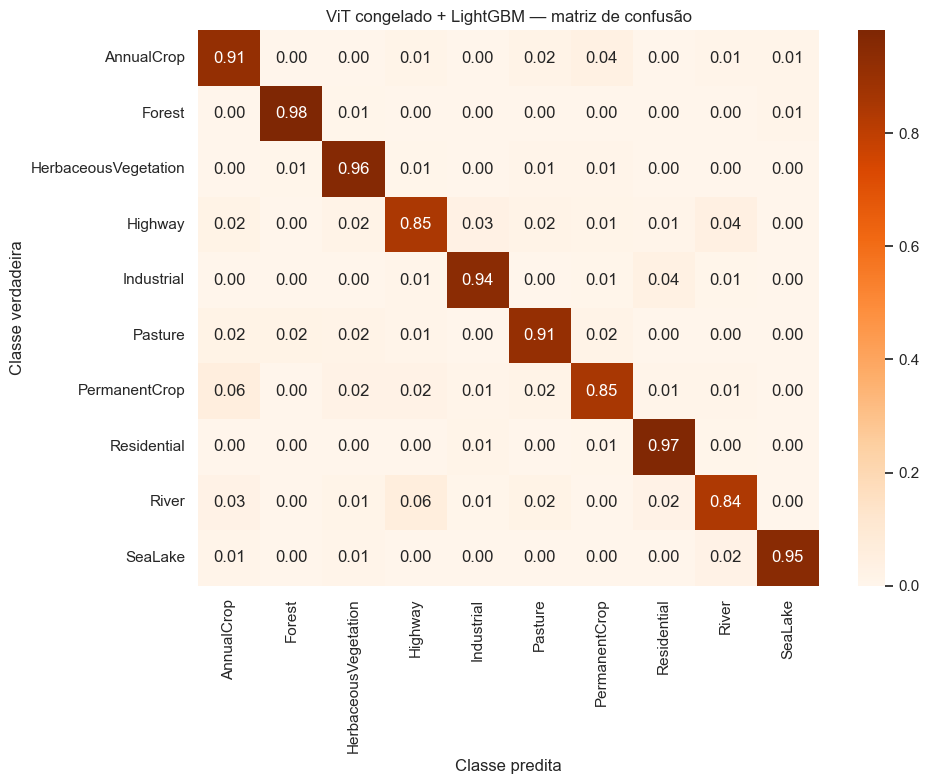

In [91]:
# =============================================================================
# TREINAMENTO, SELEÇÃO E TESTE DO LIGHTGBM SOBRE EMBEDDINGS DO VIT
# =============================================================================
#
# Objetivo desta célula:
#
# 1. Carregar os embeddings gerados pelo ViT congelado.
# 2. Validar se embeddings e rótulos estão corretamente alinhados.
# 3. Criar três configurações candidatas do LightGBM.
# 4. Treinar cada configuração somente no conjunto de treino.
# 5. Comparar as configurações pelo F1 Macro de validação.
# 6. Escolher o melhor modelo sem consultar o teste.
# 7. Avaliar o modelo escolhido uma única vez no teste.
# 8. Calcular métricas, matriz de confusão, tempos e tamanho.
# 9. Salvar o classificador treinado.
# 10. Registrar o resultado para a comparação final do benchmark.
#
# Fluxo:
#
# embeddings de treino
# (N_treino, 768)
#       ↓
# treinamento dos candidatos LightGBM
#       ↓
# embeddings de validação
# (N_validação, 768)
#       ↓
# seleção pelo F1 Macro
#       ↓
# melhor LightGBM
#       ↓
# embeddings de teste
# (N_teste, 768)
#       ↓
# métricas finais
#
# IMPORTANTE:
#
# - O LightGBM não recebe pixels.
# - O LightGBM recebe uma tabela com 768 características por imagem.
# - Não existe backpropagation do LightGBM para o ViT.
# - A GPU não é utilizada por padrão pelo LGBMClassifier desta célula.
# - O teste não participa da escolha da configuração.
# =============================================================================


if EXECUTAR_TREINOS:

    # Confere se o pacote está instalado no ambiente atual.
    exigir_pacote("lightgbm")

    # pickle será usado para salvar o classificador treinado.
    import pickle

    # LGBMClassifier implementa o LightGBM para problemas de classificação.
    from lightgbm import LGBMClassifier

    # log_loss avalia a qualidade das probabilidades produzidas pelo modelo.
    from sklearn.metrics import log_loss

    # =========================================================================
    # 1. CONFERIR SE OS ARQUIVOS DE EMBEDDINGS EXISTEM
    # =========================================================================

    # Cada caminho foi criado nas células anteriores com o sufixo:
    #
    # - rapido;
    # - completo.
    #
    # Assim, não misturamos embeddings produzidos com quantidades diferentes
    # de imagens.
    caminhos_necessarios_lgbm = [
        caminho_embeddings_treino,
        caminho_labels_treino,
        caminho_embeddings_validacao,
        caminho_labels_validacao,
        caminho_embeddings_teste,
        caminho_labels_teste,
    ]

    # Identifica arquivos ausentes.
    arquivos_ausentes_lgbm = [
        caminho
        for caminho in caminhos_necessarios_lgbm
        if not caminho.exists()
    ]

    # Interrompe a célula antes do np.load caso algum artefato não exista.
    if arquivos_ausentes_lgbm:
        raise FileNotFoundError(
            "Os seguintes artefatos não foram encontrados:\n"
            + "\n".join(
                str(caminho)
                for caminho in arquivos_ausentes_lgbm
            )
            + "\nExecute primeiro a extração dos embeddings."
        )

    # =========================================================================
    # 2. CARREGAR OS EMBEDDINGS E RÓTULOS
    # =========================================================================

    # Recarregamos os arquivos mesmo que os arrays ainda estejam na memória.
    #
    # Isso demonstra que o LightGBM é independente do ViT depois que os
    # embeddings são salvos.
    #
    # allow_pickle=False impede o carregamento de objetos Python arbitrários.
    # Os arquivos devem conter somente arrays numéricos.
    X_train_lgbm = np.load(
        caminho_embeddings_treino,
        allow_pickle=False,
    )

    y_train_lgbm = np.load(
        caminho_labels_treino,
        allow_pickle=False,
    )

    X_val_lgbm = np.load(
        caminho_embeddings_validacao,
        allow_pickle=False,
    )

    y_val_lgbm = np.load(
        caminho_labels_validacao,
        allow_pickle=False,
    )

    X_test_lgbm = np.load(
        caminho_embeddings_teste,
        allow_pickle=False,
    )

    y_test_lgbm = np.load(
        caminho_labels_teste,
        allow_pickle=False,
    )

    # =========================================================================
    # 3. VALIDAR OS ARRAYS CARREGADOS
    # =========================================================================

    # Organizamos os três conjuntos para repetir as mesmas verificações.
    conjuntos_lgbm = (
        (
            "treino",
            X_train_lgbm,
            y_train_lgbm,
        ),
        (
            "validação",
            X_val_lgbm,
            y_val_lgbm,
        ),
        (
            "teste",
            X_test_lgbm,
            y_test_lgbm,
        ),
    )

    for nome_split, X_split, y_split in conjuntos_lgbm:

        # A matriz de embeddings precisa ter duas dimensões:
        #
        # linhas   = imagens;
        # colunas  = características do embedding.
        if X_split.ndim != 2:
            raise ValueError(
                f"A matriz de {nome_split} deveria possuir "
                f"duas dimensões, mas possui shape {X_split.shape}."
            )

        # O número de colunas deve coincidir com o hidden_size do ViT.
        #
        # Para o ViT Base:
        #
        # dimensao_embedding_vit = 768
        if (
            X_split.shape[1]
            != dimensao_embedding_vit
        ):
            raise ValueError(
                f"Quantidade incorreta de características em "
                f"{nome_split}: {X_split.shape[1]}; "
                f"esperado: {dimensao_embedding_vit}."
            )

        # Deve existir um rótulo para cada linha da matriz de embeddings.
        if len(X_split) != len(y_split):
            raise ValueError(
                f"Quantidade de embeddings e rótulos diverge "
                f"em {nome_split}: "
                f"{len(X_split)} embeddings e "
                f"{len(y_split)} rótulos."
            )

        # Verifica se não existem valores NaN ou infinitos.
        if not np.isfinite(X_split).all():
            raise ValueError(
                f"Os embeddings de {nome_split} "
                "contêm NaN ou infinito."
            )

        # Confere se todos os rótulos estão no intervalo 0..9.
        if (
            y_split.min() < 0
            or y_split.max() >= len(CLASSES)
        ):
            raise ValueError(
                f"Existem rótulos inválidos em {nome_split}."
            )

        print(
            f"{nome_split.capitalize()} | "
            f"X={X_split.shape} | "
            f"y={y_split.shape} | "
            f"dtype={X_split.dtype}"
        )

    # =========================================================================
    # 4. DEFINIR O ESPAÇO DE CONFIGURAÇÕES
    # =========================================================================

    # Faremos uma busca pequena e explícita.
    #
    # Isso não é uma otimização exaustiva. O objetivo é comparar algumas
    # combinações plausíveis sem esconder o processo em outra ferramenta.
    configuracoes_lgbm = [
        {
            # CONFIGURAÇÃO 1:
            # referência relativamente conservadora.
            #
            # learning_rate:
            # contribuição de cada nova árvore.
            "learning_rate": 0.05,

            # num_leaves:
            # quantidade máxima de folhas por árvore.
            #
            # Mais folhas permitem divisões mais complexas.
            "num_leaves": 31,

            # max_depth=-1:
            # não impõe um limite explícito de profundidade.
            "max_depth": 2,

            # Quantidade máxima de iterações de boosting.
            "n_estimators": 300,

            # Sem regularização L1.
            "reg_alpha": 0.0,

            # Sem regularização L2.
            "reg_lambda": 0.0,
        },
        {
            # CONFIGURAÇÃO 2:
            # taxa de aprendizado menor, mais árvores e maior quantidade
            # de folhas.
            "learning_rate": 0.03,
            "num_leaves": 63,

            # Limita a profundidade para controlar a complexidade.
            "max_depth": 10,

            # A taxa menor é compensada por mais árvores.
            "n_estimators": 500,

            # Regularizações leves.
            "reg_alpha": 0.1,
            "reg_lambda": 0.1,
        },
        {
            # CONFIGURAÇÃO 3:
            # aprendizado mais rápido, árvores menos profundas e
            # regularização mais forte.
            "learning_rate": 0.08,
            "num_leaves": 31,
            "max_depth": 8,
            "n_estimators": 250,
            "reg_alpha": 0.5,
            "reg_lambda": 0.5,
        },
    ]

    print(
        "\nQuantidade de configurações:",
        len(configuracoes_lgbm),
    )

    # =========================================================================
    # 5. PREPARAR O HISTÓRICO DA BUSCA
    # =========================================================================

    # Armazena as métricas e tempos de cada configuração.
    historico_busca_lgbm = []

    # Começamos com menos infinito para garantir que a primeira configuração
    # válida seja considerada uma melhoria.
    melhor_f1_validacao_lgbm = -np.inf

    # Receberá o melhor modelo encontrado.
    lgbm_embeddings = None

    # Receberá o dicionário de hiperparâmetros vencedor.
    melhor_cfg_lgbm = None

    # Receberá o número da melhor configuração.
    melhor_numero_config_lgbm = None

    # Inicia o cronômetro da busca inteira.
    inicio_busca_lgbm = time.perf_counter()

    # =========================================================================
    # 6. TREINAR OS CANDIDATOS
    # =========================================================================

    # enumerate fornece:
    #
    # numero_config = 1, 2, 3...
    # parametros    = dicionário da configuração atual.
    for numero_config, parametros in enumerate(
        configuracoes_lgbm,
        start=1,
    ):
        print(
            "\n"
            + "=" * 70
        )

        print(
            f"Configuração "
            f"{numero_config}/"
            f"{len(configuracoes_lgbm)}"
        )

        print(
            "=" * 70
        )

        # Exibe os hiperparâmetros verticalmente.
        display(
            pd.Series(
                parametros,
                name="valor",
            )
        )

        # Cronometra somente o treinamento do candidato atual.
        inicio_candidato_lgbm = (
            time.perf_counter()
        )

        # Cria um novo classificador para a configuração atual.
        candidato_lgbm = LGBMClassifier(
            # Problema de classificação multiclasse.
            objective="multiclass",

            # Quantidade de classes do EuroSAT.
            num_class=len(CLASSES),

            # Torna o treinamento reproduzível.
            random_state=SEED,

            # Usa todos os núcleos lógicos disponíveis da CPU.
            n_jobs=-1,

            # Evita excesso de mensagens internas do LightGBM.
            verbosity=-1,

            # Expande o dicionário de hiperparâmetros.
            **parametros,
        )

        # Treina o candidato somente com o conjunto de treinamento.
        #
        # O modelo aprende regras sobre as 768 características do embedding.
        candidato_lgbm.fit(
            X_train_lgbm,
            y_train_lgbm,
        )

        # Calcula o tempo de treinamento do candidato atual.
        tempo_candidato_lgbm = (
            time.perf_counter()
            - inicio_candidato_lgbm
        )

        # Produz as classes previstas para o conjunto de validação.
        #
        # O teste ainda não foi consultado.
        pred_validacao_lgbm = (
            candidato_lgbm.predict(
                X_val_lgbm
            )
        )

        # Calcula a métrica utilizada para selecionar a configuração.
        #
        # average="macro":
        # calcula o F1 de cada classe e depois tira a média, dando a mesma
        # importância às dez classes.
        f1_validacao_lgbm = f1_score(
            y_val_lgbm,
            pred_validacao_lgbm,
            average="macro",
            zero_division=0,
        )

        # Registra o resultado da configuração atual.
        historico_busca_lgbm.append(
            {
                "configuração": numero_config,
                "f1_macro_validação": (
                    f1_validacao_lgbm
                ),
                "tempo_s": tempo_candidato_lgbm,

                # Adiciona também todos os hiperparâmetros.
                **parametros,
            }
        )

        print(
            "Tempo de treinamento:",
            f"{tempo_candidato_lgbm:.1f}s",
        )

        print(
            "F1 Macro de validação:",
            f"{f1_validacao_lgbm:.4f}",
        )

        # Se a configuração atual superar o melhor F1 anterior, ela se torna a
        # nova configuração vencedora.
        if (
            f1_validacao_lgbm
            > melhor_f1_validacao_lgbm
        ):
            melhor_f1_validacao_lgbm = (
                f1_validacao_lgbm
            )

            # copy cria um novo dicionário, independente do original.
            melhor_cfg_lgbm = parametros.copy()

            # Guardamos a referência para o modelo treinado.
            lgbm_embeddings = candidato_lgbm

            melhor_numero_config_lgbm = (
                numero_config
            )

    # Calcula o tempo de todas as configurações.
    tempo_busca_lgbm = (
        time.perf_counter()
        - inicio_busca_lgbm
    )

    # Confirma se pelo menos um candidato foi treinado.
    if lgbm_embeddings is None:
        raise RuntimeError(
            "Nenhum candidato LightGBM foi treinado."
        )

    # =========================================================================
    # 7. EXIBIR E SALVAR O HISTÓRICO DA BUSCA
    # =========================================================================

    # Converte a lista de dicionários em uma tabela.
    historico_busca_lgbm_df = pd.DataFrame(
        historico_busca_lgbm
    )

    # Ordena da melhor para a pior configuração.
    historico_busca_lgbm_df = (
        historico_busca_lgbm_df
        .sort_values(
            "f1_macro_validação",
            ascending=False,
        )
        .reset_index(drop=True)
    )

    print("\nResultado da busca:")

    display(
        historico_busca_lgbm_df.style.format(
            {
                "f1_macro_validação": "{:.4f}",
                "tempo_s": "{:.1f}",
            }
        )
    )

    print(
        "Melhor configuração:",
        melhor_numero_config_lgbm,
    )

    display(
        pd.Series(
            melhor_cfg_lgbm,
            name="valor",
        )
    )

    print(
        "Melhor F1 Macro de validação:",
        f"{melhor_f1_validacao_lgbm:.4f}",
    )

    # Salva a tabela de busca para consulta posterior.
    caminho_historico_lgbm = (
        REPORT_DIR
        / f"busca_lightgbm_{sufixo_vit}.csv"
    )

    historico_busca_lgbm_df.to_csv(
        caminho_historico_lgbm,
        index=False,
    )

    # =========================================================================
    # 8. CONFIRMAR A ORDEM DAS CLASSES
    # =========================================================================

    # O predict_proba retornará uma coluna para cada valor de classes_.
    #
    # Precisamos confirmar que a ordem é:
    #
    # 0, 1, 2, ..., 9
    classes_esperadas_lgbm = np.arange(
        len(CLASSES)
    )

    if not np.array_equal(
        lgbm_embeddings.classes_,
        classes_esperadas_lgbm,
    ):
        raise ValueError(
            "A ordem das classes do LightGBM não corresponde "
            "aos índices esperados pelo benchmark."
        )

    # =========================================================================
    # 9. AVALIAR O MODELO ESCOLHIDO NO TESTE
    # =========================================================================

    # Somente agora o modelo escolhido será aplicado ao teste.
    #
    # O cronômetro abaixo mede apenas o LightGBM, pois os embeddings já foram
    # calculados anteriormente.
    inicio_inferencia_lgbm = (
        time.perf_counter()
    )

    # Retorna a classe prevista para cada imagem:
    #
    # shape esperado: (N_teste,)
    pred_lgbm = lgbm_embeddings.predict(
        X_test_lgbm
    )

    # Retorna uma probabilidade para cada uma das dez classes:
    #
    # shape esperado: (N_teste, 10)
    proba_lgbm = (
        lgbm_embeddings
        .predict_proba(X_test_lgbm)
    )

    tempo_inferencia_lgbm = (
        time.perf_counter()
        - inicio_inferencia_lgbm
    )

    # Para comparar com CNN e ResNet, precisamos considerar o pipeline completo:
    #
    # imagem
    #   ↓ ViT
    # embedding
    #   ↓ LightGBM
    # previsão
    #
    # Por isso, somamos o tempo usado para extrair os embeddings do teste.
    tempo_inferencia_pipeline_lgbm = (
        tempo_embeddings_teste
        + tempo_inferencia_lgbm
    )

    # Valida os shapes das previsões.
    if pred_lgbm.shape != y_test_lgbm.shape:
        raise ValueError(
            "O shape das predições não corresponde "
            "ao shape dos rótulos de teste."
        )

    if proba_lgbm.shape != (
        len(y_test_lgbm),
        len(CLASSES),
    ):
        raise ValueError(
            "O shape das probabilidades está incorreto: "
            f"{proba_lgbm.shape}."
        )

    # =========================================================================
    # 10. CALCULAR AS MÉTRICAS DE TESTE
    # =========================================================================

    # Accuracy:
    # proporção total de previsões corretas.
    accuracy_lgbm = accuracy_score(
        y_test_lgbm,
        pred_lgbm,
    )

    # Precision Macro:
    # calcula a precision de cada classe e faz a média simples.
    precision_lgbm = precision_score(
        y_test_lgbm,
        pred_lgbm,
        average="macro",
        zero_division=0,
    )

    # Recall Macro:
    # calcula o recall de cada classe e faz a média simples.
    recall_lgbm = recall_score(
        y_test_lgbm,
        pred_lgbm,
        average="macro",
        zero_division=0,
    )

    # F1 Macro:
    # média simples dos F1 individuais das dez classes.
    f1_macro_lgbm = f1_score(
        y_test_lgbm,
        pred_lgbm,
        average="macro",
        zero_division=0,
    )

    # AUC OVR Macro:
    #
    # OVR significa One-vs-Rest.
    # Cada classe é comparada contra todas as demais.
    auc_lgbm = roc_auc_score(
        y_test_lgbm,
        proba_lgbm,
        multi_class="ovr",
        average="macro",
    )

    # Log Loss:
    # avalia a qualidade das probabilidades.
    #
    # Previsões erradas feitas com alta confiança recebem penalidade maior.
    log_loss_lgbm = log_loss(
        y_test_lgbm,
        proba_lgbm,
        labels=range(len(CLASSES)),
    )

    # Calcula o F1 individual de cada classe.
    f1_classes_lgbm = f1_score(
        y_test_lgbm,
        pred_lgbm,
        labels=range(len(CLASSES)),
        average=None,
        zero_division=0,
    )

    # =========================================================================
    # 11. ORGANIZAR AS MÉTRICAS EM TABELAS
    # =========================================================================

    metricas_lgbm = pd.DataFrame(
        {
            "métrica": [
                "Accuracy",
                "Precision Macro",
                "Recall Macro",
                "F1 Macro",
                "AUC OVR Macro",
                "Log Loss",
            ],
            "valor": [
                accuracy_lgbm,
                precision_lgbm,
                recall_lgbm,
                f1_macro_lgbm,
                auc_lgbm,
                log_loss_lgbm,
            ],
        }
    )

    # Ordenamos do menor para o maior F1 para colocar as classes mais difíceis
    # no início da tabela.
    f1_por_classe_lgbm = (
        pd.DataFrame(
            {
                "classe": CLASSES,
                "f1": f1_classes_lgbm,
            }
        )
        .sort_values("f1")
        .reset_index(drop=True)
    )

    print("\nMétricas no teste:")

    display(
        metricas_lgbm.style.format(
            {"valor": "{:.4f}"}
        )
    )

    print("F1 por classe:")

    display(
        f1_por_classe_lgbm.style.format(
            {"f1": "{:.4f}"}
        )
    )

    # =========================================================================
    # 12. MATRIZ DE CONFUSÃO
    # =========================================================================

    # normalize="true" divide cada linha pela quantidade real daquela classe.
    #
    # Portanto:
    # - cada linha soma aproximadamente 1;
    # - a diagonal representa a proporção corretamente classificada;
    # - as células fora da diagonal mostram as confusões.
    matriz_lgbm = confusion_matrix(
        y_test_lgbm,
        pred_lgbm,
        labels=range(len(CLASSES)),
        normalize="true",
    )

    plt.figure(
        figsize=(10, 8)
    )

    sns.heatmap(
        matriz_lgbm,

        # Mostra os valores dentro das células.
        annot=True,

        # Exibe duas casas decimais.
        fmt=".2f",

        cmap="Oranges",
        xticklabels=CLASSES,
        yticklabels=CLASSES,
    )

    plt.title(
        "ViT congelado + LightGBM — "
        "matriz de confusão"
    )

    plt.xlabel(
        "Classe predita"
    )

    plt.ylabel(
        "Classe verdadeira"
    )

    plt.tight_layout()

    # =========================================================================
    # 13. SALVAR O CLASSIFICADOR
    # =========================================================================

    # O nome mantém a separação entre o experimento rápido e o completo.
    caminho_lgbm = (
        ARTIFACT_DIR
        / f"lightgbm_embeddings_{sufixo_vit}.pkl"
    )

    # "wb" significa escrita binária.
    with caminho_lgbm.open("wb") as arquivo:
        pickle.dump(
            lgbm_embeddings,
            arquivo,
        )

    # Calcula o tamanho isolado do classificador LightGBM.
    tamanho_classificador_lgbm_mb = (
        caminho_lgbm.stat().st_size
        / 1024**2
    )

    # =========================================================================
    # 14. ESTIMAR O TAMANHO DO PIPELINE COMPLETO
    # =========================================================================

    # Cada parâmetro float32 ocupa aproximadamente quatro bytes.
    #
    # Esta é uma estimativa do tamanho do backbone ViT.
    # O tamanho real pode variar dependendo do formato usado para armazená-lo.
    tamanho_backbone_vit_estimado_mb = (
        total_parametros_vit_backbone
        * 4
        / 1024**2
    )

    # Para usar o pipeline completo, precisamos de:
    #
    # 1. backbone ViT;
    # 2. classificador LightGBM.
    tamanho_pipeline_lgbm_mb = (
        tamanho_backbone_vit_estimado_mb
        + tamanho_classificador_lgbm_mb
    )

    # =========================================================================
    # 15. REGISTRAR O RESULTADO NO BENCHMARK
    # =========================================================================

    # O tempo de "treino" do pipeline inclui:
    #
    # - extração de todos os embeddings;
    # - treinamento e comparação das configurações do LightGBM.
    tempo_preparacao_pipeline_lgbm = (
        tempo_extracao_total
        + tempo_busca_lgbm
    )

    RESULTADOS[
        "ViT congelado + LightGBM"
    ] = {
        "modelo": (
            "ViT congelado + LightGBM"
        ),
        "accuracy": accuracy_lgbm,
        "precision_macro": precision_lgbm,
        "recall_macro": recall_lgbm,
        "f1_macro": f1_macro_lgbm,
        "auc_ovr_macro": auc_lgbm,
        "log_loss": log_loss_lgbm,

        # Custo total para preparar o pipeline.
        "treino_s": (
            tempo_preparacao_pipeline_lgbm
        ),

        # Inferência imagem → ViT → LightGBM.
        "inferencia_s": (
            tempo_inferencia_pipeline_lgbm
        ),

        # Valores adicionais para análises específicas.
        "extracao_embeddings_s": (
            tempo_extracao_total
        ),
        "busca_lightgbm_s": (
            tempo_busca_lgbm
        ),
        "inferencia_classificador_s": (
            tempo_inferencia_lgbm
        ),

        # O LightGBM não possui "parâmetros treináveis" diretamente comparáveis
        # aos pesos de uma rede neural.
        "parametros_totais": (
            total_parametros_vit_backbone
        ),
        "parametros_treinaveis": np.nan,

        # Estimativa do backbone mais o classificador.
        "tamanho_mb": (
            tamanho_pipeline_lgbm_mb
        ),

        # Registra também o tamanho isolado do LightGBM.
        "tamanho_classificador_mb": (
            tamanho_classificador_lgbm_mb
        ),

        # Adiciona uma coluna de F1 para cada classe.
        **{
            f"f1_{classe}": valor
            for classe, valor in zip(
                CLASSES,
                f1_classes_lgbm,
            )
        },
    }

    # =========================================================================
    # 16. EXIBIR O RESUMO FINAL
    # =========================================================================

    print("\nResumo do pipeline:")

    print(
        f"Extração dos embeddings: "
        f"{tempo_extracao_total:.1f}s"
    )

    print(
        f"Busca do LightGBM: "
        f"{tempo_busca_lgbm:.1f}s"
    )

    print(
        f"Preparação total: "
        f"{tempo_preparacao_pipeline_lgbm:.1f}s"
    )

    print(
        f"Inferência apenas do LightGBM: "
        f"{tempo_inferencia_lgbm:.3f}s"
    )

    print(
        f"Inferência ponta a ponta no teste: "
        f"{tempo_inferencia_pipeline_lgbm:.1f}s"
    )

    print(
        f"Tamanho do classificador: "
        f"{tamanho_classificador_lgbm_mb:.2f} MB"
    )

    print(
        f"Tamanho estimado do pipeline: "
        f"{tamanho_pipeline_lgbm_mb:.2f} MB"
    )

    print(
        "Histórico da busca salvo em:",
        caminho_historico_lgbm,
    )

    print(
        "Classificador salvo em:",
        caminho_lgbm,
    )

else:

    print(
        "LightGBM aguardando "
        "EXECUTAR_TREINOS=True."
    )

**Como interpretar:** um resultado competitivo indica que o ViT pré-treinado já organiza as imagens em uma representação separável. Um resultado inferior ao LoRA sugere que adaptar a atenção ao domínio de satélite acrescentou sinal útil.

**Conclusão da seção:** o pipeline separa claramente duas responsabilidades: o ViT produz a representação visual e o LightGBM aprende a fronteira de decisão. Os arquivos rápidos e completos recebem nomes diferentes para impedir a mistura acidental de experimentos.

## 18. Vision Transformer adaptado com LoRA

**Pergunta de aprendizagem:** como adaptar a atenção sem atualizar todos os pesos do Transformer?

No módulo anterior, a representação do ViT permaneceu fixa. LoRA mantém os grandes pesos pré-treinados congelados, mas insere pequenas matrizes treináveis nas projeções de atenção.

```text
Imagem (N, 3, 224, 224)
        ↓ patches 16×16
Tokens (N, 197, 768)
        ↓ self-attention com LoRA em Query e Value
Token [CLS] adaptado (N, 768)
        ↓ classificador treinável
Logits (N, 10)
        ↓ CrossEntropyLoss
Gradientes somente em LoRA e no classificador
```

### Equação do LoRA

No fine-tuning completo, atualizaríamos a matriz grande $W$. No LoRA, ela permanece congelada:

$$
W'=W+\Delta W,\qquad \Delta W=\frac{\alpha}{r}BA
$$

As matrizes $A$ e $B$ têm rank pequeno $r$, reduzindo muito a quantidade de parâmetros treináveis. Neste experimento usamos `r=8`, `alpha=16`, dropout de 0,10 e adaptamos `q_proj` e `v_proj`, nomes adotados pela versão instalada do Transformers.

| Componente | Decisão |
|---|---|
| Backbone original | congelado |
| Projeções adaptadas | `q_proj` e `v_proj` |
| Cabeça de classificação | treinável e salva com o adapter |
| Otimizador | AdamW somente nos parâmetros treináveis |
| Estabilidade | warmup linear e gradient clipping |
| Memória | batch menor e mixed precision quando há CUDA |
| Seleção de época | F1 Macro de validação + early stopping |

O teste permanece isolado até a melhor época ser restaurada.

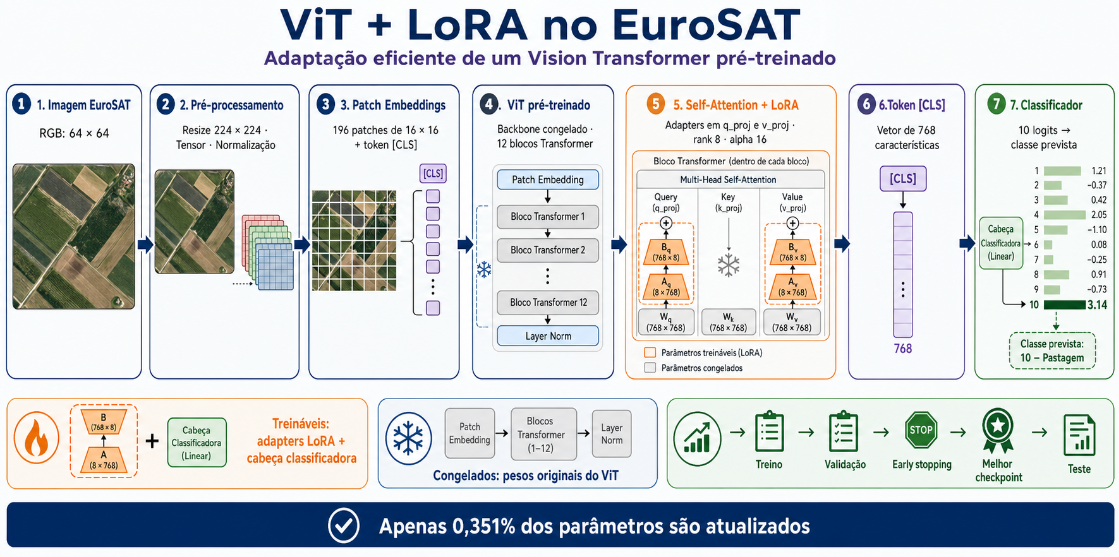

In [94]:
# =============================================================================
# PREPARAÇÃO DO EXPERIMENTO: VISION TRANSFORMER + LORA
# =============================================================================
#
# Objetivo desta célula:
#
# 1. Definir os controles do experimento.
# 2. Carregar o processador de imagens do checkpoint.
# 3. Criar transformações específicas para treino, validação e teste.
# 4. Separar os três conjuntos de dados.
# 5. Criar Datasets e DataLoaders.
# 6. Carregar o ViT com uma cabeça para as dez classes do EuroSAT.
# 7. Inserir os adaptadores LoRA nas projeções de atenção.
# 8. Identificar quais parâmetros poderão ser treinados.
# 9. Definir loss, otimizador, mixed precision e scheduler.
#
# Esta célula ainda não executa o treinamento.
# O loop de épocas será executado na próxima célula.
#
# Fluxo preparado:
#
# Imagem EuroSAT
# (N, 3, 224, 224)
#       ↓
# ViT pré-treinado
#       ↓
# Self-Attention com LoRA em q_proj e v_proj
#       ↓
# Token [CLS]
# (N, 768)
#       ↓
# Classificador treinável
# (N, 10 logits)
#
# Durante o treinamento:
#
# - os pesos originais do ViT permanecem congelados;
# - as matrizes LoRA recebem gradientes;
# - a nova cabeça classificadora recebe gradientes.
# =============================================================================


if EXECUTAR_TREINOS:

    # Confere se as bibliotecas necessárias estão instaladas.
    exigir_pacote("transformers")
    exigir_pacote("peft")

    # AutoImageProcessor:
    # recupera as configurações de pré-processamento do checkpoint.
    from transformers import AutoImageProcessor

    # ViTForImageClassification:
    # carrega o backbone ViT junto com uma cabeça de classificação.
    from transformers import ViTForImageClassification

    # Cria um scheduler com:
    # - crescimento linear da learning rate durante o warmup;
    # - redução linear depois do warmup.
    from transformers import (
        get_linear_schedule_with_warmup
    )

    # LoraConfig:
    # define como e onde os adaptadores LoRA serão inseridos.
    from peft import LoraConfig

    # get_peft_model:
    # insere os adaptadores LoRA no modelo original.
    from peft import get_peft_model

    # Essas duas funções serão usadas na célula de treinamento para salvar e
    # restaurar somente os parâmetros LoRA e a cabeça classificadora.
    from peft import get_peft_model_state_dict
    from peft import set_peft_model_state_dict

    # =========================================================================
    # 1. CONTROLES DO EXPERIMENTO LORA
    # =========================================================================

    # False determina que o LoRA utilizará todos os dados disponíveis:
    #
    # treino:     18.899 imagens
    # validação:   4.051 imagens
    # teste:       4.050 imagens
    #
    # Total:      27.000 imagens
    MODO_RAPIDO_LORA = False

    # Esta variável só seria utilizada se MODO_RAPIDO_LORA=True.
    # Ela pode permanecer definida para facilitar testes rápidos futuros.
    AMOSTRAS_POR_CLASSE_LORA = 120

    # Número de imagens processadas simultaneamente.
    #
    # O ViT consome mais memória do que a CNN e a ResNet50, principalmente
    # durante o backward. Por isso, começamos com batch size 8.
    #
    # Caso apareça o erro "CUDA out of memory", reduza para 4.
    BATCH_SIZE_LORA = 8

    # Número máximo de épocas do treinamento completo.
    #
    # O treinamento pode terminar antes por causa do early stopping.
    MAX_EPOCAS_LORA = 20

    # Interrompe o treinamento depois de quatro épocas consecutivas
    # sem melhora na F1 Macro de validação.
    PACIENCIA_LORA = 4

    # Ativa Automatic Mixed Precision quando CUDA estiver disponível.
    #
    # Algumas operações serão executadas em float16, reduzindo o consumo
    # de memória e podendo acelerar o treinamento.
    USAR_AMP_LORA = torch.cuda.is_available()

    print("Modo rápido LoRA:", MODO_RAPIDO_LORA)
    print("Utilizar conjunto completo:", not MODO_RAPIDO_LORA)
    print("Batch size:", BATCH_SIZE_LORA)
    print("Épocas máximas:", MAX_EPOCAS_LORA)
    print("Paciência:", PACIENCIA_LORA)
    print("Mixed precision:", USAR_AMP_LORA)

    # =========================================================================
    # 2. CARREGAR O PROCESSADOR DO CHECKPOINT
    # =========================================================================

    # CFG.vit_model_id contém:
    #
    # google/vit-base-patch16-224-in21k
    #
    # Esse checkpoint foi pré-treinado anteriormente em uma grande coleção de
    # imagens e será adaptado ao EuroSAT utilizando LoRA.
    lora_processor = (
        AutoImageProcessor.from_pretrained(
            CFG.vit_model_id
        )
    )

    # Recupera a configuração de tamanho do processador.
    configuracao_tamanho_lora = (
        lora_processor.size
    )

    # =========================================================================
    # 3. DESCOBRIR O TAMANHO ESPERADO PELO PROCESSADOR
    # =========================================================================

    # Transformers 5 pode retornar um objeto SizeDict.
    #
    # Nesse objeto, o tamanho normalmente está em:
    #
    # configuracao_tamanho_lora.height
    tamanho_lora = getattr(
        configuracao_tamanho_lora,
        "height",
        None,
    )

    # Alguns processadores utilizam shortest_edge em vez de height.
    if tamanho_lora is None:
        tamanho_lora = getattr(
            configuracao_tamanho_lora,
            "shortest_edge",
            None,
        )

    # Mantém compatibilidade com versões que retornam um dicionário comum.
    if (
        tamanho_lora is None
        and hasattr(
            configuracao_tamanho_lora,
            "get",
        )
    ):
        tamanho_lora = (
            configuracao_tamanho_lora.get(
                "height"
            )
        )

        if tamanho_lora is None:
            tamanho_lora = (
                configuracao_tamanho_lora.get(
                    "shortest_edge"
                )
            )

    # Mantém compatibilidade com versões que retornam diretamente um número.
    if (
        tamanho_lora is None
        and isinstance(
            configuracao_tamanho_lora,
            (int, float),
        )
    ):
        tamanho_lora = (
            configuracao_tamanho_lora
        )

    # Interrompe a execução caso apareça um formato desconhecido.
    if tamanho_lora is None:
        raise TypeError(
            "Formato desconhecido para "
            "lora_processor.size: "
            f"{type(configuracao_tamanho_lora)}"
        )

    # Garante que o tamanho final seja inteiro.
    tamanho_lora = int(tamanho_lora)

    print(
        "\nTamanho esperado pelo ViT:",
        tamanho_lora,
        "x",
        tamanho_lora,
    )

    print(
        "Média RGB:",
        lora_processor.image_mean,
    )

    print(
        "Desvio-padrão RGB:",
        lora_processor.image_std,
    )

    # =========================================================================
    # 4. TRANSFORMAÇÕES DO TREINAMENTO
    # =========================================================================

    # No treinamento usamos augmentation.
    #
    # Imagens de satélite podem ser observadas em diferentes orientações.
    # Por isso, flips horizontais e verticais são transformações plausíveis:
    # eles alteram a orientação, mas normalmente não alteram a classe.
    transform_lora_treino = transforms.Compose(
        [
            # Redimensiona a imagem original de 64 × 64 para 224 × 224.
            transforms.Resize(
                (
                    tamanho_lora,
                    tamanho_lora,
                ),
                interpolation=(
                    InterpolationMode.BILINEAR
                ),
            ),

            # Aplica espelhamento horizontal com probabilidade padrão de 50%.
            transforms.RandomHorizontalFlip(),

            # Aplica espelhamento vertical com probabilidade padrão de 50%.
            transforms.RandomVerticalFlip(),

            # Converte:
            #
            # PIL (H, W, C), valores 0..255
            #
            # para:
            #
            # tensor (C, H, W), valores 0..1
            transforms.ToTensor(),

            # Normaliza os canais no padrão do checkpoint.
            transforms.Normalize(
                mean=tuple(
                    lora_processor.image_mean
                ),
                std=tuple(
                    lora_processor.image_std
                ),
            ),
        ]
    )

    # =========================================================================
    # 5. TRANSFORMAÇÕES DE VALIDAÇÃO E TESTE
    # =========================================================================

    # Validação e teste não recebem transformações aleatórias.
    #
    # Queremos avaliar sempre a mesma versão de cada imagem.
    transform_lora_avaliacao = (
        transforms.Compose(
            [
                transforms.Resize(
                    (
                        tamanho_lora,
                        tamanho_lora,
                    ),
                    interpolation=(
                        InterpolationMode.BILINEAR
                    ),
                ),

                transforms.ToTensor(),

                transforms.Normalize(
                    mean=tuple(
                        lora_processor.image_mean
                    ),
                    std=tuple(
                        lora_processor.image_std
                    ),
                ),
            ]
        )
    )

    # =========================================================================
    # 6. SEPARAR TREINO, VALIDAÇÃO E TESTE
    # =========================================================================

    # Seleciona somente as imagens marcadas como treino.
    lora_treino_df = (
        df_splits.loc[
            df_splits["split"].eq("treino")
        ]
        .copy()
        .reset_index(drop=True)
    )

    # Seleciona somente as imagens de validação.
    lora_validacao_df = (
        df_splits.loc[
            df_splits["split"].eq(
                "validacao"
            )
        ]
        .copy()
        .reset_index(drop=True)
    )

    # Seleciona somente as imagens reservadas para o teste final.
    lora_teste_df = (
        df_splits.loc[
            df_splits["split"].eq("teste")
        ]
        .copy()
        .reset_index(drop=True)
    )

    # =========================================================================
    # 7. APLICAR O MODO RÁPIDO
    # =========================================================================

    if MODO_RAPIDO_LORA:

        # Seleciona até 120 imagens por classe no treinamento.
        lora_treino_df = (
            subconjunto_rapido(
                lora_treino_df,
                n_por_classe=(
                    AMOSTRAS_POR_CLASSE_LORA
                ),
            )
            .reset_index(drop=True)
        )

        # Repete a amostragem para a validação.
        lora_validacao_df = (
            subconjunto_rapido(
                lora_validacao_df,
                n_por_classe=(
                    AMOSTRAS_POR_CLASSE_LORA
                ),
            )
            .reset_index(drop=True)
        )

        # Repete a amostragem para o teste.
        lora_teste_df = (
            subconjunto_rapido(
                lora_teste_df,
                n_por_classe=(
                    AMOSTRAS_POR_CLASSE_LORA
                ),
            )
            .reset_index(drop=True)
        )

    # Confere se nenhum split ficou vazio.
    quantidades_lora = {
        "treino": len(lora_treino_df),
        "validação": len(
            lora_validacao_df
        ),
        "teste": len(lora_teste_df),
    }

    if any(
        quantidade == 0
        for quantidade
        in quantidades_lora.values()
    ):
        raise ValueError(
            f"Existe split vazio: "
            f"{quantidades_lora}"
        )

    print(
        "\nQuantidade de imagens:",
        quantidades_lora,
    )

    # =========================================================================
    # 8. CRIAR OS DATASETS
    # =========================================================================

    # EuroSATPaths recebe:
    #
    # 1. DataFrame com caminhos e rótulos;
    # 2. transformação aplicada às imagens.
    #
    # A transformação é um argumento posicional na classe utilizada no
    # notebook.
    dataset_lora_treino = EuroSATPaths(
        lora_treino_df,
        transform_lora_treino,
    )

    dataset_lora_validacao = EuroSATPaths(
        lora_validacao_df,
        transform_lora_avaliacao,
    )

    dataset_lora_teste = EuroSATPaths(
        lora_teste_df,
        transform_lora_avaliacao,
    )

    # =========================================================================
    # 9. CRIAR O DATALOADER DE TREINAMENTO
    # =========================================================================

    loader_lora_treino = DataLoader(
        # Dataset de treinamento.
        dataset_lora_treino,

        # Quantidade máxima de imagens por batch.
        batch_size=BATCH_SIZE_LORA,

        # Embaralha as imagens no início de cada época.
        shuffle=True,

        # Quantidade de processos auxiliares para leitura.
        num_workers=CFG.num_workers,

        # Melhora a transferência da RAM para a GPU quando há CUDA.
        pin_memory=torch.cuda.is_available(),

        # Define uma semente para cada worker.
        worker_init_fn=worker_seed,

        # Torna a ordem do embaralhamento reproduzível.
        generator=criar_gerador(SEED),
    )

    # =========================================================================
    # 10. CRIAR O DATALOADER DE VALIDAÇÃO
    # =========================================================================

    loader_lora_validacao = DataLoader(
        dataset_lora_validacao,
        batch_size=BATCH_SIZE_LORA,

        # Não embaralhamos porque não haverá aprendizado.
        shuffle=False,

        num_workers=CFG.num_workers,
        pin_memory=torch.cuda.is_available(),
        worker_init_fn=worker_seed,
    )

    # =========================================================================
    # 11. CRIAR O DATALOADER DE TESTE
    # =========================================================================

    loader_lora_teste = DataLoader(
        dataset_lora_teste,
        batch_size=BATCH_SIZE_LORA,

        # Preserva a ordem das imagens e previsões.
        shuffle=False,

        num_workers=CFG.num_workers,
        pin_memory=torch.cuda.is_available(),
        worker_init_fn=worker_seed,
    )

    print(
        "\nQuantidade de batches | treino:",
        len(loader_lora_treino),
        "| validação:",
        len(loader_lora_validacao),
        "| teste:",
        len(loader_lora_teste),
    )

    # =========================================================================
    # 12. LIBERAR MEMÓRIA DA GPU
    # =========================================================================

    # O backbone utilizado para extrair os embeddings pode continuar existindo
    # na memória.
    #
    # Movemos esse modelo para a CPU porque agora carregaremos outro ViT para o
    # experimento LoRA.
    if "vit_backbone" in globals():
        vit_backbone = vit_backbone.to(
            "cpu"
        )

    # CNN e ResNet também podem continuar na memória do notebook.
    for nome_modelo_anterior in (
        "cnn_final",
        "resnet50",
    ):
        modelo_anterior = globals().get(
            nome_modelo_anterior
        )

        if isinstance(
            modelo_anterior,
            nn.Module,
        ):
            modelo_anterior.to("cpu")

    # Libera blocos CUDA que deixaram de ser utilizados.
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    # =========================================================================
    # 13. CARREGAR O VIT COM CABEÇA DE CLASSIFICAÇÃO
    # =========================================================================

    # ViTForImageClassification possui:
    #
    # 1. backbone ViT;
    # 2. camada classificadora final.
    #
    # O checkpoint original não possui uma cabeça para as dez classes do
    # EuroSAT. Por isso, a nova cabeça será inicializada.
    vit_base_lora = (
        ViTForImageClassification
        .from_pretrained(
            CFG.vit_model_id,

            # Define dez saídas, uma para cada classe do EuroSAT.
            num_labels=len(CLASSES),

            # Relaciona índice numérico com nome da classe.
            id2label={
                indice: classe
                for indice, classe
                in enumerate(CLASSES)
            },

            # Relaciona nome da classe com índice numérico.
            label2id=classe_para_id,

            # Permite substituir a cabeça original por outra com shape
            # diferente.
            ignore_mismatched_sizes=True,

            # Usa a implementação explícita da atenção.
            attn_implementation="eager",
        )
    )

    # =========================================================================
    # 14. DEFINIR A CONFIGURAÇÃO LORA
    # =========================================================================

    configuracao_lora = LoraConfig(
        # Rank das matrizes LoRA.
        #
        # Em vez de aprender uma matriz completa 768 × 768, o LoRA representa
        # a atualização usando duas matrizes menores de rank 8.
        r=8,

        # Controla a escala da atualização LoRA.
        #
        # A contribuição é proporcional a:
        #
        # alpha / rank = 16 / 8 = 2
        lora_alpha=16,

        # Desliga aleatoriamente 10% das entradas do caminho LoRA durante o
        # treinamento, ajudando na regularização.
        lora_dropout=0.10,

        # Não cria atualizações LoRA para os termos de bias.
        bias="none",

        # Transformers 5 utiliza os nomes:
        #
        # q_proj = projeção que produz as Queries;
        # v_proj = projeção que produz os Values.
        #
        # As demais projeções permanecem congeladas.
        target_modules=[
            "q_proj",
            "v_proj",
        ],

        # A cabeça classificadora não é um adaptador LoRA, mas também precisa:
        #
        # - receber gradientes;
        # - ser salva junto com os adapters;
        # - ser restaurada no melhor checkpoint.
        modules_to_save=[
            "classifier",
        ],
    )

    # =========================================================================
    # 15. INSERIR OS ADAPTADORES NO MODELO
    # =========================================================================

    # get_peft_model:
    #
    # 1. congela os pesos originais do ViT;
    # 2. insere as matrizes LoRA;
    # 3. mantém a cabeça classificadora treinável;
    # 4. devolve um modelo PEFT.
    vit_lora = get_peft_model(
        vit_base_lora,
        configuracao_lora,
    )

    # Move o modelo completo para GPU ou CPU.
    vit_lora = vit_lora.to(DEVICE)

    # =========================================================================
    # 16. IDENTIFICAR OS PARÂMETROS TREINÁVEIS
    # =========================================================================

    # O otimizador deve receber somente os parâmetros que podem ser atualizados.
    #
    # Isso inclui:
    #
    # - matrizes LoRA em q_proj;
    # - matrizes LoRA em v_proj;
    # - pesos e bias da cabeça classificadora.
    parametros_lora_otimizados = [
        parametro
        for parametro
        in vit_lora.parameters()
        if parametro.requires_grad
    ]

    # Guardamos também os nomes para conferir se o congelamento foi configurado
    # corretamente.
    nomes_parametros_lora = [
        nome
        for nome, parametro
        in vit_lora.named_parameters()
        if parametro.requires_grad
    ]

    # Conta todos os parâmetros, congelados e treináveis.
    total_parametros_lora = sum(
        parametro.numel()
        for parametro
        in vit_lora.parameters()
    )

    # Conta somente os parâmetros que receberão gradientes.
    treinaveis_lora = sum(
        parametro.numel()
        for parametro
        in vit_lora.parameters()
        if parametro.requires_grad
    )

    # Calcula a proporção treinável.
    percentual_treinavel_lora = (
        100
        * treinaveis_lora
        / total_parametros_lora
    )

    # Confere se existe pelo menos um parâmetro treinável.
    if treinaveis_lora == 0:
        raise RuntimeError(
            "Nenhum parâmetro LoRA foi marcado "
            "como treinável."
        )

    # Se todos os parâmetros estiverem treináveis, o backbone não foi congelado
    # corretamente.
    if (
        treinaveis_lora
        >= total_parametros_lora
    ):
        raise RuntimeError(
            "Todos os parâmetros estão treináveis. "
            "O LoRA deveria atualizar somente uma "
            "pequena fração do modelo."
        )

    # Confirma se os módulos esperados aparecem entre os parâmetros treináveis.
    if not any(
        "lora_" in nome
        for nome in nomes_parametros_lora
    ):
        raise RuntimeError(
            "Nenhum parâmetro LoRA foi encontrado."
        )

    if not any(
        "classifier" in nome
        for nome in nomes_parametros_lora
    ):
        raise RuntimeError(
            "A cabeça classificadora não foi "
            "marcada como treinável."
        )

    # =========================================================================
    # 17. DEFINIR A FUNÇÃO DE LOSS
    # =========================================================================

    # CrossEntropyLoss é apropriada para classificação multiclasse.
    #
    # Entrada:
    #
    # logits: (N, 10)
    # labels: (N,)
    #
    # Não aplicamos softmax antes da loss porque a CrossEntropyLoss já realiza
    # internamente a transformação necessária.
    loss_fn_lora = nn.CrossEntropyLoss()

    # =========================================================================
    # 18. DEFINIR O OTIMIZADOR
    # =========================================================================

    # AdamW atualizará somente a lista parametros_lora_otimizados.
    #
    # Portanto, os pesos originais do ViT não serão modificados.
    optimizer_lora = torch.optim.AdamW(
        parametros_lora_otimizados,

        # Learning rate dos adapters e da cabeça.
        lr=2e-4,

        # Regularização L2 desacoplada aplicada pelo AdamW.
        weight_decay=1e-4,
    )

    # =========================================================================
    # 19. CALCULAR A QUANTIDADE DE PASSOS
    # =========================================================================

    # Um passo corresponde ao processamento de um batch seguido de:
    #
    # backward → optimizer.step() → scheduler.step()
    #
    # Exemplo:
    #
    # 150 batches × 8 épocas = 1.200 passos.
    total_passos_lora = (
        len(loader_lora_treino)
        * MAX_EPOCAS_LORA
    )

    # Durante os primeiros 10% dos passos, a learning rate crescerá
    # gradualmente.
    passos_warmup_lora = int(
        0.10
        * total_passos_lora
    )

    # =========================================================================
    # 20. CRIAR O SCHEDULER
    # =========================================================================

    # Funcionamento:
    #
    # início:
    # learning rate cresce durante o warmup;
    #
    # depois:
    # learning rate diminui linearmente até o final planejado.
    scheduler_lora = (
        get_linear_schedule_with_warmup(
            optimizer_lora,
            num_warmup_steps=(
                passos_warmup_lora
            ),
            num_training_steps=(
                total_passos_lora
            ),
        )
    )

    # =========================================================================
    # 21. CRIAR O GRADIENT SCALER
    # =========================================================================

    # Em float16, valores pequenos podem sofrer underflow.
    #
    # O GradScaler multiplica temporariamente a loss antes do backward,
    # preservando a qualidade numérica dos gradientes.
    #
    # Na CPU, enabled=False faz o objeto se comportar como uma operação neutra.
    scaler_lora = torch.amp.GradScaler(
        "cuda",
        enabled=USAR_AMP_LORA,
    )

    # =========================================================================
    # 22. EXIBIR A CONFIGURAÇÃO FINAL
    # =========================================================================

    print("\nConfiguração LoRA:")

    print(
        f"Parâmetros treináveis: "
        f"{treinaveis_lora:,}/"
        f"{total_parametros_lora:,} "
        f"({percentual_treinavel_lora:.3f}%)"
    )

    print(
        "Passos totais planejados:",
        total_passos_lora,
    )

    print(
        "Passos de warmup:",
        passos_warmup_lora,
    )

    print(
        "Learning rate inicial do otimizador:",
        optimizer_lora.param_groups[0]["lr"],
    )

    print(
        "Dispositivo:",
        next(vit_lora.parameters()).device,
    )

    # Mostra alguns nomes para confirmar visualmente quais componentes serão
    # atualizados.
    print(
        "\nExemplos de parâmetros treináveis:"
    )

    for nome in nomes_parametros_lora[:12]:
        print(" -", nome)

    print(
        "\nExperimento preparado. "
        "A próxima célula executará treino, "
        "validação, early stopping e teste."
    )

else:

    print(
        "Preparação do ViT + LoRA aguardando "
        "EXECUTAR_TREINOS=True."
    )

Modo rápido LoRA: False
Utilizar conjunto completo: True
Batch size: 8
Épocas máximas: 20
Paciência: 4
Mixed precision: True

Tamanho esperado pelo ViT: 224 x 224
Média RGB: (0.5, 0.5, 0.5)
Desvio-padrão RGB: (0.5, 0.5, 0.5)

Quantidade de imagens: {'treino': 18899, 'validação': 4051, 'teste': 4050}

Quantidade de batches | treino: 2363 | validação: 507 | teste: 507


Loading weights: 100%|██████████| 6/6 [00:00<?, ?it/s]
[transformers] ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224-in21k
Key                                                     | Status     | 
--------------------------------------------------------+------------+-
encoder.layer.{0...11}.attention.attention.key.bias     | UNEXPECTED | 
encoder.layer.{0...11}.output.dense.bias                | UNEXPECTED | 
encoder.layer.{0...11}.attention.attention.key.weight   | UNEXPECTED | 
encoder.layer.{0...11}.attention.output.dense.bias      | UNEXPECTED | 
encoder.layer.{0...11}.output.dense.weight              | UNEXPECTED | 
encoder.layer.{0...11}.attention.attention.value.weight | UNEXPECTED | 
encoder.layer.{0...11}.layernorm_before.weight          | UNEXPECTED | 
encoder.layer.{0...11}.attention.attention.query.weight | UNEXPECTED | 
encoder.layer.{0...11}.attention.output.dense.weight    | UNEXPECTED | 
encoder.layer.{0...11}.layernorm_after.weight           | UN


Configuração LoRA:
Parâmetros treináveis: 302,602/86,108,948 (0.351%)
Passos totais planejados: 47260
Passos de warmup: 4726
Learning rate inicial do otimizador: 0.0
Dispositivo: cuda:0

Exemplos de parâmetros treináveis:
 - base_model.model.vit.layers.0.attention.q_proj.lora_A.default.weight
 - base_model.model.vit.layers.0.attention.q_proj.lora_B.default.weight
 - base_model.model.vit.layers.0.attention.v_proj.lora_A.default.weight
 - base_model.model.vit.layers.0.attention.v_proj.lora_B.default.weight
 - base_model.model.vit.layers.1.attention.q_proj.lora_A.default.weight
 - base_model.model.vit.layers.1.attention.q_proj.lora_B.default.weight
 - base_model.model.vit.layers.1.attention.v_proj.lora_A.default.weight
 - base_model.model.vit.layers.1.attention.v_proj.lora_B.default.weight
 - base_model.model.vit.layers.2.attention.q_proj.lora_A.default.weight
 - base_model.model.vit.layers.2.attention.q_proj.lora_B.default.weight
 - base_model.model.vit.layers.2.attention.v_proj.lora_A.

Época 01 | Loss treino 1.5934 | Loss validação 0.9850 | F1 validação 0.6720 | LR 1.00e-04
Época 02 | Loss treino 0.7701 | Loss validação 0.6959 | F1 validação 0.7383 | LR 2.00e-04
Época 03 | Loss treino 0.5139 | Loss validação 0.4221 | F1 validação 0.8488 | LR 1.89e-04
Época 04 | Loss treino 0.3970 | Loss validação 0.3861 | F1 validação 0.8616 | LR 1.78e-04
Época 05 | Loss treino 0.3435 | Loss validação 0.3271 | F1 validação 0.8900 | LR 1.67e-04
Época 06 | Loss treino 0.3031 | Loss validação 0.3341 | F1 validação 0.8946 | LR 1.56e-04
Época 07 | Loss treino 0.2756 | Loss validação 0.3171 | F1 validação 0.8974 | LR 1.44e-04
Época 08 | Loss treino 0.2557 | Loss validação 0.3435 | F1 validação 0.8893 | LR 1.33e-04
Época 09 | Loss treino 0.2286 | Loss validação 0.2782 | F1 validação 0.9140 | LR 1.22e-04
Época 10 | Loss treino 0.2197 | Loss validação 0.2677 | F1 validação 0.9156 | LR 1.11e-04
Época 11 | Loss treino 0.2035 | Loss validação 0.2668 | F1 validação 0.9195 | LR 1.00e-04
Época 12 |

c:\Users\leova\anaconda3\envs\engenharia_ia_venv\lib\site-packages\sklearn\metrics\_classification.py:259: UserWarning: The y_prob values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


,métrica,valor
0,Accuracy,0.938519
1,Precision Macro,0.936085
2,Recall Macro,0.936644
3,F1 Macro,0.936005
4,AUC OVR Macro,0.997143
5,Log Loss,0.242798


,classe,f1
0,River,0.890957
1,PermanentCrop,0.895364
2,Highway,0.904762
3,Pasture,0.917342
4,HerbaceousVegetation,0.926174
5,AnnualCrop,0.931416
6,Industrial,0.960630
7,Forest,0.975610
8,Residential,0.978022
9,SeaLake,0.979775


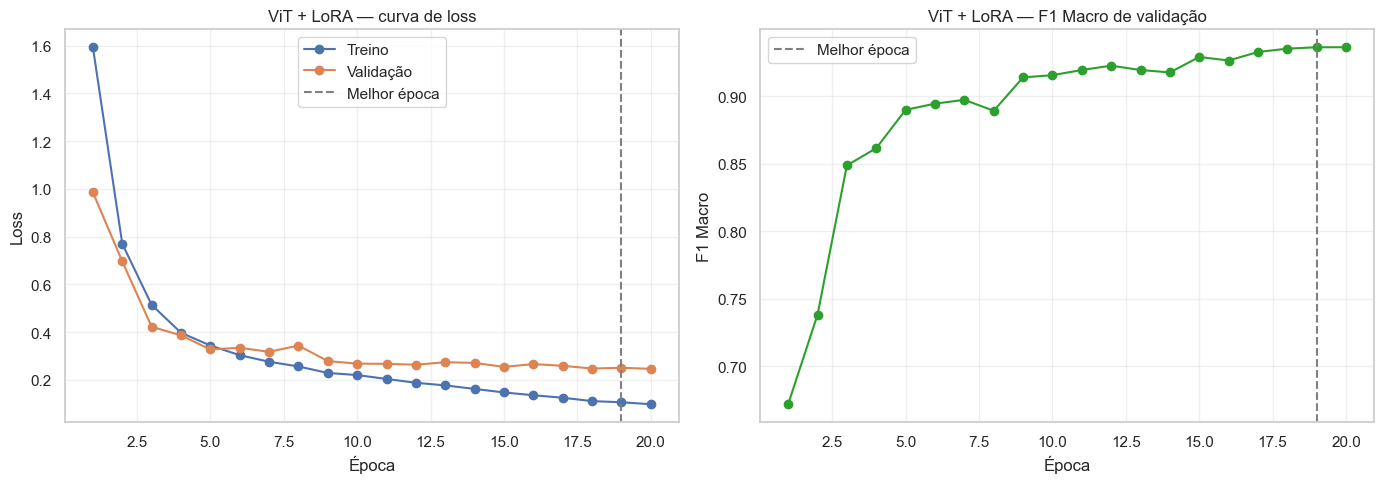

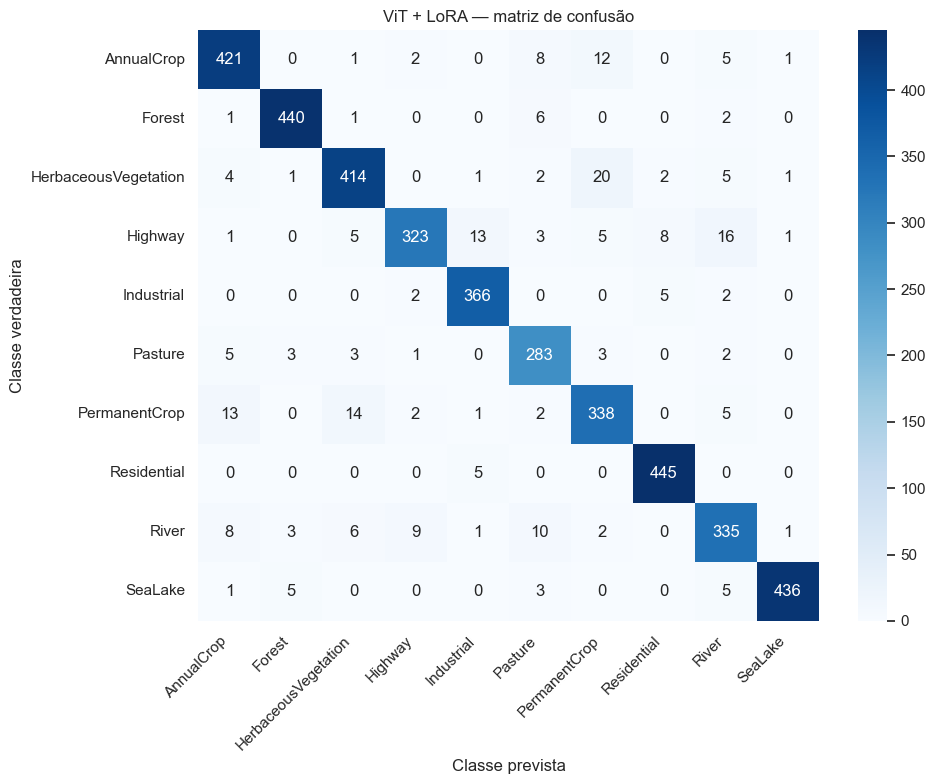

Treino: 4773.5s | Inferência: 41.0s
Adapter LoRA salvo: 1.17 MB | Pipeline completo estimado: 328.48 MB
Adapter salvo em: D:\Projetos_v2\Modelo_VC_Satelites\models\vit_lora_adapter_completo
Histórico salvo em: D:\Projetos_v2\Modelo_VC_Satelites\reports\historico_lora_completo.csv


NameError: name 'parametros_treinaveis_lora' is not defined

In [ ]:
# =============================================================================
# OBJETIVO DESTA CÉLULA
# =============================================================================
# Treinar, validar e testar o ViT adaptado com LoRA.
#
# Fluxo cronológico:
#
# 1. Treinar o modelo em vários batches.
# 2. Validar ao final de cada época.
# 3. Aplicar early stopping usando a F1 Macro de validação.
# 4. Guardar somente o melhor estado do adapter LoRA.
# 5. Restaurar o melhor estado encontrado.
# 6. Avaliar uma única vez no conjunto de teste.
# 7. Calcular métricas, gerar gráficos e salvar o adapter.
# =============================================================================

if EXECUTAR_TREINOS:

    # log_loss avalia a qualidade das probabilidades previstas.
    # Uma previsão errada e muito confiante recebe uma penalização maior.
    from sklearn.metrics import log_loss

    # Garante que o modelo esteja no dispositivo correto.
    # Isso também permite executar novamente esta célula caso o modelo tenha sido
    # movido para a CPU no final de uma execução anterior.
    vit_lora = vit_lora.to(DEVICE)

    # -------------------------------------------------------------------------
    # 1. VARIÁVEIS PARA ACOMPANHAR O TREINAMENTO
    # -------------------------------------------------------------------------

    # Cada item desta lista armazenará as métricas de uma época.
    historico_lora = []

    # Melhor F1 Macro encontrada no conjunto de validação.
    melhor_f1_lora = -np.inf

    # Estado do adapter LoRA correspondente à melhor F1 de validação.
    melhor_estado_lora = None

    # Época em que o melhor resultado foi encontrado.
    melhor_epoca_lora = 0

    # Conta quantas épocas consecutivas ocorreram sem melhora.
    epocas_sem_melhora_lora = 0

    # Registra o tempo total do treinamento.
    inicio_treino_lora = time.perf_counter()

    # -------------------------------------------------------------------------
    # 2. LOOP PRINCIPAL DE ÉPOCAS
    # -------------------------------------------------------------------------

    for epoca in range(1, MAX_EPOCAS_LORA + 1):

        # =====================================================================
        # ETAPA A: TREINAMENTO
        # =====================================================================

        # Ativa o modo de treinamento.
        #
        # Isso é importante para camadas que têm comportamentos diferentes
        # durante treino e avaliação, como Dropout.
        vit_lora.train()

        # Soma ponderada das losses de todos os batches da época.
        soma_loss_treino_lora = 0.0

        # Número total de imagens processadas nesta época.
        quantidade_treino_lora = 0

        # O DataLoader entrega um batch por vez.
        for imagens, rotulos in loader_lora_treino:

            # Move as imagens para GPU ou CPU.
            #
            # non_blocking=True pode acelerar a transferência quando o
            # DataLoader utiliza pin_memory=True e o dispositivo é CUDA.
            imagens = imagens.to(DEVICE, non_blocking=True)

            # Move os rótulos verdadeiros para o mesmo dispositivo.
            rotulos = rotulos.to(DEVICE, non_blocking=True)

            # Remove os gradientes calculados no batch anterior.
            #
            # set_to_none=True costuma consumir menos memória do que preencher
            # todos os gradientes anteriores com zero.
            optimizer_lora.zero_grad(set_to_none=True)

            # Mixed precision permite executar parte das operações em float16.
            #
            # Na GPU, isso pode reduzir o consumo de memória e acelerar o treino.
            # O bloco será desativado automaticamente quando USAR_AMP_LORA=False.
            with torch.amp.autocast(
                device_type=DEVICE.type,
                dtype=torch.float16,
                enabled=USAR_AMP_LORA,
            ):

                # Forward pass:
                # as imagens atravessam o ViT e produzem dez logits por imagem.
                #
                # Como também fornecemos labels, o próprio modelo calcula
                # a Cross-Entropy Loss.
                saida = vit_lora(
                    pixel_values=imagens,
                    labels=rotulos,
                )

                # Loss média do batch atual.
                loss = saida.loss

            # Calcula os gradientes da loss em relação aos parâmetros treináveis.
            #
            # O GradScaler aumenta temporariamente a escala da loss para reduzir
            # problemas de underflow numérico durante o treino em float16.
            scaler_lora.scale(loss).backward()

            # Antes de limitar os gradientes, desfazemos a escala aplicada
            # anteriormente pelo GradScaler.
            scaler_lora.unscale_(optimizer_lora)

            # Gradient clipping evita atualizações exageradas causadas por
            # gradientes muito grandes.
            torch.nn.utils.clip_grad_norm_(
                vit_lora.parameters(),
                max_norm=1.0,
            )

            # Atualiza os parâmetros treináveis usando o otimizador.
            #
            # No LoRA, a maior parte do ViT permanece congelada. São atualizados
            # principalmente os adaptadores LoRA e a cabeça classificadora.
            scaler_lora.step(optimizer_lora)

            # Ajusta dinamicamente a escala usada pelo mixed precision.
            scaler_lora.update()

            # Atualiza a learning rate de acordo com o scheduler.
            #
            # Neste pipeline, o scheduler avança depois de cada batch.
            scheduler_lora.step()

            # Número de imagens presentes no batch atual.
            tamanho_batch = rotulos.size(0)

            # Como loss.item() representa a média do batch, multiplicamos pelo
            # tamanho do batch para calcular corretamente a média da época.
            soma_loss_treino_lora += loss.item() * tamanho_batch

            # Atualiza o número total de imagens processadas.
            quantidade_treino_lora += tamanho_batch

        # Loss média de treinamento considerando todas as imagens da época.
        loss_treino_lora = (
            soma_loss_treino_lora / quantidade_treino_lora
        )

        # =====================================================================
        # ETAPA B: VALIDAÇÃO
        # =====================================================================

        # Ativa o modo de avaliação.
        #
        # Isso desativa comportamentos de treinamento, como o Dropout.
        vit_lora.eval()

        soma_loss_validacao_lora = 0.0
        quantidade_validacao_lora = 0

        # Listas que armazenarão os rótulos reais e as previsões.
        y_validacao_lora = []
        pred_validacao_lora = []

        # inference_mode desativa o cálculo e o armazenamento dos gradientes.
        #
        # Isso reduz o consumo de memória e acelera a validação.
        with torch.inference_mode():

            for imagens, rotulos in loader_lora_validacao:

                imagens = imagens.to(DEVICE, non_blocking=True)
                rotulos = rotulos.to(DEVICE, non_blocking=True)

                # Também podemos usar AMP na validação porque não haverá backward.
                with torch.amp.autocast(
                    device_type=DEVICE.type,
                    dtype=torch.float16,
                    enabled=USAR_AMP_LORA,
                ):

                    saida = vit_lora(
                        pixel_values=imagens,
                        labels=rotulos,
                    )

                    loss_validacao = saida.loss
                    logits_validacao = saida.logits

                # argmax seleciona a classe com o maior logit para cada imagem.
                previsoes = logits_validacao.argmax(dim=1)

                tamanho_batch = rotulos.size(0)

                soma_loss_validacao_lora += (
                    loss_validacao.item() * tamanho_batch
                )

                quantidade_validacao_lora += tamanho_batch

                # As métricas do scikit-learn são calculadas na CPU.
                y_validacao_lora.extend(
                    rotulos.cpu().numpy().tolist()
                )

                pred_validacao_lora.extend(
                    previsoes.cpu().numpy().tolist()
                )

        # Loss média do conjunto de validação.
        loss_validacao_lora = (
            soma_loss_validacao_lora / quantidade_validacao_lora
        )

        # F1 Macro calcula a F1 individualmente para cada classe e depois
        # realiza uma média simples entre as dez classes.
        f1_validacao_lora = f1_score(
            y_validacao_lora,
            pred_validacao_lora,
            average="macro",
            zero_division=0,
        )

        # Learning rate existente ao final da época.
        learning_rate_atual = optimizer_lora.param_groups[0]["lr"]

        # Guarda as informações desta época para os gráficos posteriores.
        historico_lora.append(
            {
                "epoca": epoca,
                "loss_treino": loss_treino_lora,
                "loss_validacao": loss_validacao_lora,
                "f1_validacao": f1_validacao_lora,
                "learning_rate": learning_rate_atual,
            }
        )

        print(
            f"Época {epoca:02d} | "
            f"Loss treino {loss_treino_lora:.4f} | "
            f"Loss validação {loss_validacao_lora:.4f} | "
            f"F1 validação {f1_validacao_lora:.4f} | "
            f"LR {learning_rate_atual:.2e}"
        )

        # =====================================================================
        # ETAPA C: EARLY STOPPING E MELHOR CHECKPOINT
        # =====================================================================

        # Verifica se a F1 desta época superou a melhor F1 anterior.
        if f1_validacao_lora > melhor_f1_lora:

            # Atualiza o melhor resultado conhecido.
            melhor_f1_lora = f1_validacao_lora
            melhor_epoca_lora = epoca

            # Como houve melhora, zeramos o contador do early stopping.
            epocas_sem_melhora_lora = 0

            # Salva somente os parâmetros treináveis do PEFT/LoRA.
            #
            # Não precisamos duplicar todos os pesos congelados do ViT.
            # Os tensores são copiados para a CPU para liberar memória da GPU.
            melhor_estado_lora = {
                nome: tensor.detach().cpu().clone()
                for nome, tensor in get_peft_model_state_dict(
                    vit_lora
                ).items()
            }

        else:

            # A época não melhorou a F1 de validação.
            epocas_sem_melhora_lora += 1

            # Interrompe o treinamento quando o número de épocas consecutivas
            # sem melhora alcança a paciência definida.
            if epocas_sem_melhora_lora >= PACIENCIA_LORA:
                print(
                    f"Early stopping acionado na época {epoca}. "
                    f"Melhor época: {melhor_epoca_lora}."
                )
                break

    # Tempo total gasto no treinamento e validação.
    tempo_treino_lora = time.perf_counter() - inicio_treino_lora

    # -------------------------------------------------------------------------
    # 3. RESTAURAÇÃO DO MELHOR ESTADO
    # -------------------------------------------------------------------------

    # Verificação defensiva: o estado deveria existir após a primeira época.
    if melhor_estado_lora is None:
        raise RuntimeError(
            "Nenhum estado LoRA foi salvo durante o treinamento."
        )

    # Recoloca os melhores pesos LoRA no modelo.
    #
    # Isso garante que o teste seja feito com a melhor época de validação,
    # e não necessariamente com a última época executada.
    set_peft_model_state_dict(
        vit_lora,
        melhor_estado_lora,
    )

    print(
        f"\nMelhor época LoRA: {melhor_epoca_lora} | "
        f"Melhor F1 de validação: {melhor_f1_lora:.4f}"
    )

    # -------------------------------------------------------------------------
    # 4. SALVAMENTO DO ADAPTER LORA
    # -------------------------------------------------------------------------

    # Mantemos resultados rápidos e completos em pastas diferentes.
    sufixo_lora = (
        "rapido" if MODO_RAPIDO_LORA else "completo"
    )

    pasta_adapter_lora = (
        ARTIFACT_DIR / f"vit_lora_adapter_{sufixo_lora}"
    )

    pasta_adapter_lora.mkdir(
        parents=True,
        exist_ok=True,
    )

    # Salva o adapter LoRA, sua configuração e os módulos adicionais definidos
    # em modules_to_save, como a cabeça classificadora.
    #
    # O backbone completo do ViT não é duplicado nessa pasta.
    vit_lora.save_pretrained(pasta_adapter_lora)

    # -------------------------------------------------------------------------
    # 5. AVALIAÇÃO FINAL NO CONJUNTO DE TESTE
    # -------------------------------------------------------------------------

    # O conjunto de teste só deve ser utilizado depois que todas as decisões,
    # como hiperparâmetros e melhor época, já estiverem definidas.
    vit_lora.eval()

    y_teste_lora = []
    pred_teste_lora = []
    proba_teste_lora = []

    inicio_inferencia_lora = time.perf_counter()

    with torch.inference_mode():

        for imagens, rotulos in loader_lora_teste:

            imagens = imagens.to(DEVICE, non_blocking=True)
            rotulos = rotulos.to(DEVICE, non_blocking=True)

            with torch.amp.autocast(
                device_type=DEVICE.type,
                dtype=torch.float16,
                enabled=USAR_AMP_LORA,
            ):

                # No teste não precisamos fornecer labels porque não precisamos
                # calcular a loss diretamente no modelo.
                saida = vit_lora(pixel_values=imagens)

                logits_teste = saida.logits

            # Convertemos os logits para float32 antes do softmax para obter
            # probabilidades numericamente mais estáveis.
            probabilidades = (
                logits_teste.float()
                .softmax(dim=1)
            )

            # Classe com a maior probabilidade prevista.
            previsoes = probabilidades.argmax(dim=1)

            y_teste_lora.extend(
                rotulos.cpu().numpy().tolist()
            )

            pred_teste_lora.extend(
                previsoes.cpu().numpy().tolist()
            )

            proba_teste_lora.extend(
                probabilidades.cpu().numpy().tolist()
            )

    tempo_inferencia_lora = (
        time.perf_counter() - inicio_inferencia_lora
    )

    # Converte as listas em arrays NumPy.
    y_teste_lora = np.asarray(y_teste_lora)
    pred_teste_lora = np.asarray(pred_teste_lora)
    proba_teste_lora = np.asarray(proba_teste_lora)

    # Confere se o modelo gerou uma linha de probabilidades para cada imagem
    # e uma coluna para cada classe.
    if proba_teste_lora.shape != (
        len(y_teste_lora),
        len(CLASSES),
    ):
        raise ValueError(
            "Formato inesperado das probabilidades: "
            f"{proba_teste_lora.shape}"
        )

    # Confere se existem valores inválidos, como NaN ou infinito.
    if not np.isfinite(proba_teste_lora).all():
        raise ValueError(
            "As probabilidades do LoRA contêm NaN ou infinito."
        )

    # -------------------------------------------------------------------------
    # 6. CÁLCULO DAS MÉTRICAS DE TESTE
    # -------------------------------------------------------------------------

    metricas_lora = {
        "Accuracy": accuracy_score(
            y_teste_lora,
            pred_teste_lora,
        ),
        "Precision Macro": precision_score(
            y_teste_lora,
            pred_teste_lora,
            average="macro",
            zero_division=0,
        ),
        "Recall Macro": recall_score(
            y_teste_lora,
            pred_teste_lora,
            average="macro",
            zero_division=0,
        ),
        "F1 Macro": f1_score(
            y_teste_lora,
            pred_teste_lora,
            average="macro",
            zero_division=0,
        ),
        "AUC OVR Macro": roc_auc_score(
            y_teste_lora,
            proba_teste_lora,
            multi_class="ovr",
            average="macro",
        ),
        "Log Loss": log_loss(
            y_teste_lora,
            proba_teste_lora,
            labels=np.arange(len(CLASSES)),
        ),
    }

    # Transforma o dicionário em tabela para facilitar a visualização.
    tabela_metricas_lora = pd.DataFrame(
        {
            "métrica": metricas_lora.keys(),
            "valor": metricas_lora.values(),
        }
    )

    display(tabela_metricas_lora)

    # -------------------------------------------------------------------------
    # 7. F1 INDIVIDUAL POR CLASSE
    # -------------------------------------------------------------------------

    f1_por_classe_lora = f1_score(
        y_teste_lora,
        pred_teste_lora,
        average=None,
        labels=np.arange(len(CLASSES)),
        zero_division=0,
    )

    tabela_f1_classes_lora = (
        pd.DataFrame(
            {
                "classe": CLASSES,
                "f1": f1_por_classe_lora,
            }
        )
        .sort_values("f1")
        .reset_index(drop=True)
    )

    display(tabela_f1_classes_lora)

    # -------------------------------------------------------------------------
    # 8. HISTÓRICO E CURVAS DE APRENDIZADO
    # -------------------------------------------------------------------------

    historico_lora_df = pd.DataFrame(historico_lora)

    # Guarda o histórico para análise posterior sem precisar treinar novamente.
    caminho_historico_lora = (
        REPORT_DIR / f"historico_lora_{sufixo_lora}.csv"
    )

    historico_lora_df.to_csv(
        caminho_historico_lora,
        index=False,
    )

    fig, axes = plt.subplots(
        1,
        2,
        figsize=(14, 5),
    )

    # Gráfico das losses de treinamento e validação.
    axes[0].plot(
        historico_lora_df["epoca"],
        historico_lora_df["loss_treino"],
        marker="o",
        label="Treino",
    )

    axes[0].plot(
        historico_lora_df["epoca"],
        historico_lora_df["loss_validacao"],
        marker="o",
        label="Validação",
    )

    axes[0].axvline(
        melhor_epoca_lora,
        color="gray",
        linestyle="--",
        label="Melhor época",
    )

    axes[0].set_title("ViT + LoRA — curva de loss")
    axes[0].set_xlabel("Época")
    axes[0].set_ylabel("Loss")
    axes[0].legend()
    axes[0].grid(alpha=0.3)

    # Gráfico da F1 Macro de validação.
    axes[1].plot(
        historico_lora_df["epoca"],
        historico_lora_df["f1_validacao"],
        marker="o",
        color="tab:green",
    )

    axes[1].axvline(
        melhor_epoca_lora,
        color="gray",
        linestyle="--",
        label="Melhor época",
    )

    axes[1].set_title("ViT + LoRA — F1 Macro de validação")
    axes[1].set_xlabel("Época")
    axes[1].set_ylabel("F1 Macro")
    axes[1].legend()
    axes[1].grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

    # -------------------------------------------------------------------------
    # 9. MATRIZ DE CONFUSÃO
    # -------------------------------------------------------------------------

    matriz_confusao_lora = confusion_matrix(
        y_teste_lora,
        pred_teste_lora,
        labels=np.arange(len(CLASSES)),
    )

    plt.figure(figsize=(10, 8))

    sns.heatmap(
        matriz_confusao_lora,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=CLASSES,
        yticklabels=CLASSES,
    )

    plt.title("ViT + LoRA — matriz de confusão")
    plt.xlabel("Classe prevista")
    plt.ylabel("Classe verdadeira")
    plt.xticks(rotation=45, ha="right")
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

    # -------------------------------------------------------------------------
    # 10. TAMANHO DO ADAPTER E CUSTO COMPUTACIONAL
    # -------------------------------------------------------------------------

    # Soma o tamanho dos arquivos salvos na pasta do adapter.
    tamanho_adapter_mb = sum(
        arquivo.stat().st_size
        for arquivo in pasta_adapter_lora.rglob("*")
        if arquivo.is_file()
    ) / (1024 ** 2)

    # Estimativa do tamanho de todos os parâmetros do pipeline em float32.
    #
    # Cada parâmetro float32 ocupa aproximadamente quatro bytes.
    tamanho_pipeline_mb = (
        total_parametros_lora * 4
    ) / (1024 ** 2)

    print(
        f"Treino: {tempo_treino_lora:.1f}s | "
        f"Inferência: {tempo_inferencia_lora:.1f}s"
    )

    print(
        f"Adapter LoRA salvo: {tamanho_adapter_mb:.2f} MB | "
        f"Pipeline completo estimado: {tamanho_pipeline_mb:.2f} MB"
    )

    print(f"Adapter salvo em: {pasta_adapter_lora}")
    print(f"Histórico salvo em: {caminho_historico_lora}")

    # -------------------------------------------------------------------------
    # 11. REGISTRO NO BENCHMARK CONSOLIDADO
    # -------------------------------------------------------------------------

    if MODO_RAPIDO_LORA:

        # O modo rápido é adequado para testar se o código funciona, mas seu
        # resultado não deve ser comparado diretamente com modelos avaliados
        # usando todo o conjunto de teste.
        print(
            "Execução em modo rápido: resultado não registrado "
            "na tabela final do benchmark."
        )

    else:

        # Somente a execução completa entra na comparação oficial.
        RESULTADOS["ViT + LoRA"] = {
            **metricas_lora,
            "Tempo treino (s)": tempo_treino_lora,
            "Tempo inferência (s)": tempo_inferencia_lora,
            "Parâmetros treináveis": treinaveis_lora,
            "Tamanho adapter (MB)": tamanho_adapter_mb,
            "Melhor época": melhor_epoca_lora,
        }

    # -------------------------------------------------------------------------
    # 12. LIBERAÇÃO DA MEMÓRIA DA GPU
    # -------------------------------------------------------------------------

    # Move o modelo para a CPU.
    vit_lora = vit_lora.to("cpu")

    # Remove referências temporárias que não serão mais utilizadas.
    del melhor_estado_lora

    # Solicita ao PyTorch que libere blocos de memória CUDA não utilizados.
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

else:

    print(
        "Treinamento LoRA não executado porque "
        "EXECUTAR_TREINOS=False."
    )

**Como interpretar:** a fração treinável deve ser muito menor que 100%. O LoRA ocupa o meio-termo entre uma representação totalmente congelada e o fine-tuning completo do backbone.

**Checkpoint:**

- CNN: representação aprendida do zero;
- ResNet50: representação convolucional transferida;
- ViT congelado + LightGBM: representação fixa e classificador externo;
- ViT + LoRA: representação Transformer adaptada com poucos parâmetros.

## 19. Trade-offs, Limitações e Conclusões

**Pergunta de aprendizagem:** quando escolher cada estratégia?

Cada abordagem resolve o problema de maneira diferente. Portanto, o melhor modelo não deve ser escolhido apenas pela maior métrica, mas também pelo custo computacional, tamanho, velocidade e objetivo do projeto.

### Quando escolher cada estratégia?

| Estratégia | Principal vantagem | Principal limitação | Quando escolher |
|---|---|---|---|
| **CNN do zero** | Modelo compacto e totalmente controlável | Precisa aprender todas as features com os dados disponíveis | Quando o objetivo é aprender CNNs, controlar a arquitetura ou produzir um modelo pequeno |
| **ResNet50** | Melhor desempenho e excelente transferência de conhecimento | Precisa armazenar e executar todo o backbone | Quando a prioridade é obter alto desempenho com implementação relativamente simples |
| **ViT congelado + LightGBM** | Pipeline mais rápido de preparar e treinar; embeddings reutilizáveis | A representação visual não se adapta ao EuroSAT | Quando velocidade de treinamento e reuso dos embeddings são prioridades |
| **ViT + LoRA** | Adapta o Transformer treinando somente uma pequena fração dos parâmetros | O backbone completo ainda torna treino e inferência custosos | Quando é necessário adaptar um grande modelo sem realizar fine-tuning completo |

### Resultados consolidados

| Posição | Modelo | F1 Macro no teste |
|---:|---|---:|
| 1 | **ResNet50** | **0,9576** |
| 2 | **ViT + LoRA** | **0,9360** |
| 3 | **ViT congelado + LightGBM** | **0,9174** |
| 4 | **CNN do zero + Optuna** | **0,8379** |

### Interpretação dos resultados

#### 1. ResNet50

A ResNet50 apresentou o melhor resultado do benchmark. As convoluções possuem um viés indutivo adequado para identificar padrões locais, como bordas, texturas, estradas, plantações, vegetação e agrupamentos de construções.

Além disso, o modelo já havia aprendido representações visuais úteis no ImageNet. Como apenas a nova cabeça classificadora foi treinada, foi possível reutilizar esse conhecimento sem modificar os filtros do backbone.

Esse resultado mostra que uma arquitetura mais recente ou complexa não é necessariamente superior em todos os problemas. Para o EuroSAT RGB, as representações convolucionais da ResNet50 foram especialmente adequadas.

#### 2. ViT + LoRA

O ViT + LoRA ficou em segundo lugar e superou o ViT congelado + LightGBM. Isso mostra que adaptar a atenção do Transformer aos rótulos do EuroSAT foi melhor do que utilizar apenas embeddings fixos.

Somente **302.602 de 86.108.948 parâmetros**, aproximadamente **0,351%**, foram treinados. O adapter resultante ocupou apenas **1,17 MB**.

Entretanto, eficiência em número de parâmetros não significa necessariamente menor tempo de execução. O forward e o backward ainda atravessam todo o backbone ViT, fazendo com que essa estratégia apresente custo computacional elevado.

O LoRA não ficou abaixo da ResNet50 por ser uma metodologia ruim. Alguns fatores ajudam a explicar o resultado:

- somente `q_proj` e `v_proj` foram adaptados;
- foi utilizado rank 8, limitando propositalmente a capacidade da atualização;
- o restante do backbone permaneceu congelado;
- as imagens originais possuem apenas `64 × 64` pixels;
- o resize para `224 × 224` não cria novos detalhes;
- os padrões locais do EuroSAT combinam muito bem com convoluções.

A F1 de validação foi `0,9363` e a F1 de teste foi `0,9360`. Essa diferença de apenas `0,0003` indica excelente generalização do checkpoint selecionado.

#### 3. ViT congelado + LightGBM

Os embeddings congelados do ViT já apresentaram boa capacidade de separar as classes, mesmo sem adaptação supervisionada do Transformer.

A principal vantagem dessa estratégia é que os embeddings podem ser calculados uma vez e reutilizados. Depois da extração, diferentes classificadores podem ser treinados sem executar novamente o ViT. Considerando a extração completa e a busca do classificador, este foi o pipeline mais rápido de preparar e treinar: aproximadamente **7,5 minutos**. Com os embeddings prontos, o LightGBM classificou o teste em apenas **0,247 segundo**. A inferência ponta a ponta é uma medida diferente, pois inclui executar novamente o ViT.

Sua limitação é que o LightGBM consegue apenas aprender sobre as features existentes. Como nenhum gradiente retorna ao ViT, a representação visual não se adapta especificamente ao EuroSAT. Isso ajuda a explicar por que o resultado ficou abaixo do LoRA.

#### 4. CNN do zero

A CNN apresentou o menor F1 Macro porque começou com pesos aleatórios e precisou aprender todas as representações utilizando somente o EuroSAT. Os outros modelos partiram de conhecimento visual adquirido em conjuntos de dados muito maiores.

Mesmo assim, a CNN não representa um resultado ruim. Ela apresentou boa generalização e foi o modelo mais compacto. Também foi fundamental para compreender convolução, feature maps, pooling, classificação e backpropagation.

### Limitações

- O EuroSAT RGB não contém todas as bandas espectrais do Sentinel-2;
- o split aleatório estratificado não mede generalização geográfica ou temporal;
- imagens provenientes de regiões próximas podem compartilhar características visuais;
- o resize de `64 × 64` para `224 × 224` não adiciona novos detalhes espaciais;
- os tempos dependem do hardware, cache, batch size e mixed precision;
- a estimativa de tamanho dos pipelines com ViT varia conforme o formato de armazenamento;
- o benchmark não avalia calibração, dados fora de distribuição ou deriva;
- não foi realizado fine-tuning completo da ResNet50 ou do ViT;
- apenas uma configuração principal de LoRA foi avaliada;
- a busca do Optuna foi realizada em um subconjunto rápido, podendo não encontrar a melhor configuração para os dados completos.

### Conclusões

A principal conclusão do benchmark é que o uso de representações pré-treinadas trouxe uma vantagem significativa. ResNet50, ViT + LoRA e ViT + LightGBM superaram a CNN treinada do zero.

Para este conjunto de dados e protocolo experimental:

- a **ResNet50** foi a melhor escolha preditiva e apresentou o melhor equilíbrio geral;
- o **ViT + LoRA** demonstrou adaptação eficiente, treinando apenas uma pequena fração dos parâmetros;
- o **ViT + LightGBM** foi o pipeline mais rápido de preparar e treinar e mostrou que embeddings congelados podem alimentar modelos clássicos com bons resultados;
- a **CNN do zero** permaneceu como a alternativa mais compacta e didática.

O ranking não deve ser interpretado como uma superioridade universal entre arquiteturas. Ele descreve o comportamento das configurações testadas no EuroSAT RGB.

Em outro dataset, especialmente com mais dados, imagens de maior resolução ou padrões que dependam de relações globais, o ViT poderia superar a ResNet50. Da mesma forma, em um ambiente com recursos computacionais limitados, a CNN compacta poderia ser a escolha mais apropriada mesmo apresentando menor F1.

Portanto, a escolha final depende do objetivo:

- **maior desempenho neste problema:** ResNet50;
- **adaptação eficiente de um Transformer:** ViT + LoRA;
- **maior velocidade de preparação e treinamento, com reutilização de representações:** ViT + LightGBM;
- **simplicidade, compactação e aprendizado dos fundamentos:** CNN do zero.